# CCR-Diffusion — larger-dataset, reproducible comparison run

This revision keeps the original model implementations but updates the experiment controls for a fresh larger-dataset run.

## Run order
1. **Restart the kernel/runtime** and run cells **[0]–[5]** in order (imports/config → metrics → patient split/preprocessing → models → Stage-1 training → Stage-2 functions).
2. Run **[6] Stage-1 ablation/evaluation**, then **[7] Stage-2 validation ablations**, then **[8] select/train the final proposed model**. Do not use test metrics to select the model or ablations.
3. Run baseline cells **[B0]–[B7]** in order for ResUNet, pix2pix, and conditional DDPM comparisons. ResUNet and pix2pix are set to the same 100-epoch maximum budget; validation selects checkpoints.
4. Run validation-based diagnostics/statistics and reproducibility logging. Only after the model and protocol are frozen, run final test evaluation **once**.
5. Optional experiments (extra seeds, extra splits, GAN, uncertainty/cost) are expensive and should be enabled only deliberately. The default run flags for optional multi-split/extra-seed experiments remain off.

## Reproducibility and fairness
- Base seed: **42**. CUDA deterministic kernels are requested and cuDNN benchmarking is disabled. Exact bitwise reproducibility can still depend on GPU/library versions and operations.
- For ablations, use the same split, preprocessing, Stage-1 setup, validation protocol, and **40 epochs** per Stage-2 ablation. Stage-1 variants use **40 epochs** each.
- The selected final Stage-2 model uses **120 epochs**. ResUNet and pix2pix main baselines use **100 epochs each**; checkpoint selection uses validation only. Conditional DDPM and deterministic-refiner epochs are explicitly recorded separately.
- A **new output directory** is used so old checkpoints/CSV files do not silently contaminate this run.
- If the input has more than the original 60 patients, a seeded **70/15/15 patient-level split** is created from all discovered patients; no patient is shared across train/validation/test. With the original 60-patient set, the notebook preserves the previous predefined split.
- Review the printed patient IDs and counts before training. If the dataset contains duplicate scans or multiple series per patient, confirm the filename-to-patient parsing before running.



In [1]:
# =====================================================================
# CCR-Diffusion v3  --  improvements + complete ablation suite
# SynthRAD2023 Brain (centre A, 60 patients), 2D 128x128 PNGs, MRI -> sCT
#
# Paste each "# %%" block into its own notebook cell, or run as a script.
#
# WHAT IS NEW vs v2
#  Improvements (each is also an ablation row, so you can prove it helps):
#   I1  2.5D Stage-1 (neighbouring slices as extra input channels)
#   I2  Stage-1 retrained with a LEAKAGE-FREE recipe (fixed epochs + EMA, no
#       checkpoint selection on the held-out fold) -> clean OOF residuals
#   I3  Raw MRI (all slices) fed to the denoiser as extra input channels
#   I4  Optional bone-weighted loss, optional x0-L1 (breaks the "no CT L1" spec,
#       so it is reported as a separate variant)
#   I5  Horizontal-flip test-time augmentation (TTA)
#   I6  Aux-SSIM target outside the MRI mask fixed to -1 (consistent with pred)
#   I7  Per-variant least-squares residual weight w* (+ val-tuned gate blend)
#
#  Ablations (val set only; test is touched ONCE at the end):
#   Stage-1: 2D vs 2.5D(+-1) vs 2.5D(+-2)
#   Stage-2: full | deterministic refiner (no diffusion) | no FiLM |
#            no coarse channel | no MRI channel | eps- vs v-prediction |
#            no aux SSIM | v1-style fixed (in-sample) conditioning |
#            bone-weighted loss | x0 L1 | Stage-2 on 2D Stage-1
#   Inference (no retraining): 1/2/4 samples, 1/2/4 folds, TTA on/off,
#            DDIM steps, EMA vs raw weights, blend variants
#   Statistics: per-patient paired differences, patient bootstrap CI, Wilcoxon
#
# Metrics: normalised PNG intensity (NOT HU). Masked = inside the MRI-derived
# mask (primary). Global = full frame (secondary). Global SSIM = mean of the
# full SSIM map (one definition everywhere).
# =====================================================================



In [2]:
# %% ====== [0] CONFIG & IMPORTS ====================================
import os, glob, math, time, json, copy, random, shutil, zipfile
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity as compute_ssim
try:
    from scipy.stats import wilcoxon
except Exception:
    wilcoxon = None

PIPELINE_VERSION = "ccr_v4_largerdataset_seed42"
SEED = 42
IMAGE_SIZE, BATCH_SIZE = 128, 8
NUM_WORKERS = 0 if os.name == "nt" else 2
N_FOLDS = 4

# ==============================================================================
# EXECUTION PROFILE (Kaggle Session Optimization)
# ==============================================================================
# Set FAST_KAGGLE_MODE = False to run the top 2.5D model & core baselines within a single ~8-9h Kaggle session!
# Set FAST_KAGGLE_MODE = False to run all 11 ablation models across multiple resumed sessions (~18h total).
FAST_KAGGLE_MODE = False

# ---- Stage-1 ----
S1_BASE, S1_EPOCHS, S1_LR, S1_EMA = 32, 40, 1e-4, 0.998
S1_VARIANTS = {"2d": (0,), "25d1": (-1, 0, 1), "25d2": (-2, -1, 0, 1, 2)}
if FAST_KAGGLE_MODE:
    S1_TO_RUN = ["25d2"]          # Top-performing 2.5D model (5 adjacent slices, 4 folds)
else:
    S1_TO_RUN = ["2d", "25d1", "25d2"]

REUSE_LEGACY_2D = False

# ---- Stage-2 ----
T_DIM, T_STEPS, Z_CLIP = 128, 1000, 8.0
S2_LR, S2_WD, S2_WARMUP, EMA_DECAY = 2e-4, 1e-4, 500, 0.999
SSIM_T_CUTOFF = 250
LOSS_BONE_THR = -0.15
VAL_FREQ = 10
QV = dict(folds=(1, 2), samples=1, steps=20)
if FAST_KAGGLE_MODE:
    ABL_EPOCHS, FINAL_EPOCHS = 40, 40
else:
    ABL_EPOCHS, FINAL_EPOCHS = 40, 120

ABL_PROTOCOL = dict(folds=(1, 2, 3, 4), samples=2, steps=25)
FINAL_PROTOCOL = dict(folds=(1, 2, 3, 4), samples=4, steps=50, flips=(False, True))

BASE_CFG = dict(s1=None,
                mode="diff",
                pred="v",
                film=True, coarse_ch=True, mri_ch=True,
                aux_ssim=0.05, x0_l1=0.0, bone_w=1.0,
                cond="oof",
                base_ch=48, seed=SEED)

ABLATIONS = {
    "A_full":        {},
    "A_det":         {"mode": "det"},
    "A_noFiLM":      {"film": False},
    "A_noCoarseCh":  {"coarse_ch": False},
    "A_noMRIch":     {"mri_ch": False},
    "A_epsPred":     {"pred": "eps"},
    "A_noAuxSSIM":   {"aux_ssim": 0.0},
    "A_fixedCond":   {"cond": "fixed"},
    "A_boneLoss":    {"bone_w": 3.0},
    "A_x0L1":        {"x0_l1": 0.1},
    "A_onS1_2d":     {"s1": "2d"},
}
if FAST_KAGGLE_MODE:
    ABLATIONS_TO_RUN = ["A_full", "A_det"]
else:
    ABLATIONS_TO_RUN = list(ABLATIONS)

TEST_ABLATIONS = ("A_det",)
FINAL_NAME = None
EXTRA_SEEDS = ()

HU_MIN, HU_MAX = -1000.0, 1500.0
HU_MAPPING_VERIFIED = False
HU_SPAN = HU_MAX - HU_MIN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"


def seed_everything(seed=42):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


seed_everything(SEED)
print(f"[CONFIG READY] Device: {device} | AMP: {use_amp} | Fast Mode: {FAST_KAGGLE_MODE}")


[CONFIG READY] Device: cuda | AMP: True | Fast Mode: False


In [3]:
# %% ====== [1] NUMPY-SIDE UTILITIES (metrics, aggregation, blending, stats) ===
def slice_metrics(pred, gt, mask):
    """Normalised-intensity metrics. masked = inside mask, global = full frame."""
    p = (np.clip(pred, -1, 1) + 1) / 2
    g = (np.clip(gt, -1, 1) + 1) / 2
    body = mask > 0.5
    d = p - g
    mse = float(np.mean(d[body] ** 2))
    _, smap = compute_ssim(g, p, data_range=1.0, full=True)
    gmse = float(np.mean(d ** 2))
    return {"mae": float(np.mean(np.abs(d[body]))), "rmse": float(np.sqrt(mse)),
            "ssim": float(np.mean(smap[body])), "psnr": float(10 * np.log10(1.0 / max(mse, 1e-12))),
            "global_mae": float(np.mean(np.abs(d))), "global_ssim": float(np.mean(smap)),
            "global_psnr": float(10 * np.log10(1.0 / max(gmse, 1e-12)))}


def patient_level(pred, gt, mask, pids):
    """Mean per patient, then macro-average over patients."""
    recs = {}
    for i in range(len(pred)):
        recs.setdefault(pids[i], []).append(slice_metrics(pred[i], gt[i], mask[i]))
    df = pd.DataFrame([{"patient_id": p, **pd.DataFrame(r).mean().to_dict()} for p, r in sorted(recs.items())])
    mu = df.drop(columns=["patient_id"]).mean()
    out = {"MAE": mu["mae"], "RMSE": mu["rmse"], "SSIM": mu["ssim"], "PSNR": mu["psnr"],
           "Global_SSIM": mu["global_ssim"], "Global_PSNR": mu["global_psnr"],
           "Score": mu["mae"] + 0.25 * (1 - mu["ssim"])}
    out["HU_MAE_provisional"] = out["MAE"] * HU_SPAN
    return out, df


def finalize(coarse, res, mask, w=1.0):
    sct = np.clip(coarse + w * res, -1, 1)
    sct[mask < 0.5] = -1.0
    return sct


def blend(coarse, res, mask, w_soft, w_bone, thr):
    gate = np.stack([cv2.GaussianBlur((c > thr).astype(np.float32), (7, 7), 1.5) for c in coarse])
    return finalize(coarse, (w_soft + (w_bone - w_soft) * gate) * res, mask)


def wstar(coarse, res, gt, mask):
    """Least-squares optimal scalar on the predicted residual (masked pixels)."""
    m = mask > 0.5
    r_true, r_hat = (gt - coarse)[m], res[m]
    return float(np.clip((r_hat * r_true).sum() / max((r_hat ** 2).sum(), 1e-12), 0.0, 1.5))


def aggregate(stack, fidx=None, lidx=None, sidx=None):
    """Average a prediction stack over chosen folds / flips / samples."""
    nf, nl, ns = stack["res"].shape[:3]
    fidx = list(range(nf)) if fidx is None else list(fidx)
    lidx = list(range(nl)) if lidx is None else list(lidx)
    sidx = list(range(ns)) if sidx is None else list(sidx)
    coarse = stack["coarse"][np.ix_(fidx, lidx)].mean((0, 1))
    res = stack["res"][np.ix_(fidx, lidx, sidx)].mean((0, 1, 2))
    return coarse, res


def paired_stats(pred_a, pred_b, gt, mask, pids, n_boot=10000, seed=0):
    """b minus a, per patient. 'improved' = in the better direction for that metric."""
    _, da = patient_level(pred_a, gt, mask, pids)
    _, db = patient_level(pred_b, gt, mask, pids)
    da = da.set_index("patient_id")
    db = db.set_index("patient_id").loc[da.index]
    rng, rows = np.random.RandomState(seed), []
    for m, sign in (("mae", -1), ("rmse", -1), ("ssim", 1), ("psnr", 1)):
        d = (db[m] - da[m]).values
        boots = rng.choice(d, size=(n_boot, len(d)), replace=True).mean(1)
        lo, hi = np.percentile(boots, [2.5, 97.5])
        p = float(wilcoxon(d).pvalue) if (wilcoxon is not None and np.any(d != 0)) else float("nan")
        rows.append({"metric": m, "mean_diff(b-a)": d.mean(), "CI95_lo": lo, "CI95_hi": hi,
                     "wilcoxon_p": p, "patients_improved": int((sign * d > 0).sum()), "n_patients": len(d)})
    return pd.DataFrame(rows)


def summarize_pred(name, coarse, res, gt, mask, pids):
    """Row with w=1 metrics and the val-optimal scalar w*."""
    m1, _ = patient_level(finalize(coarse, res, mask), gt, mask, pids)
    w = wstar(coarse, res, gt, mask)
    mw, _ = patient_level(finalize(coarse, res, mask, w), gt, mask, pids)
    return {"variant": name, "MAE": m1["MAE"], "SSIM": m1["SSIM"], "PSNR": m1["PSNR"], "Score": m1["Score"],
            "w*": w, "MAE(w*)": mw["MAE"], "SSIM(w*)": mw["SSIM"], "PSNR(w*)": mw["PSNR"], "Score(w*)": mw["Score"]}




In [4]:
# %% ====== [2] DATA: discovery, split, preprocessing, 2.5D stacking ============
import os, glob, random
import numpy as np
import cv2
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

BASE_OUT_DIR = "/kaggle/working/synthrad_ccr_v4_largerdataset_seed42" if os.path.exists("/kaggle") else "./synthrad_ccr_v4_largerdataset_seed42"
DIR_S1, DIR_S2, DIR_METRICS, DIR_FIG = [os.path.join(BASE_OUT_DIR, d) for d in ("s1", "s2", "metrics", "figures")]
for d in (DIR_S1, DIR_S2, DIR_METRICS, DIR_FIG):
    os.makedirs(d, exist_ok=True)

# 1. Use already-extracted PNGs on disk
DATASET_ROOT = "/kaggle/working/synthrad_png" if os.path.isdir("/kaggle/working/synthrad_png/ct") else "./synthrad_png"
CT_DIR, MRI_DIR = os.path.join(DATASET_ROOT, "ct"), os.path.join(DATASET_ROOT, "mri")

common = sorted(set(f for f in os.listdir(CT_DIR) if f.lower().endswith(".png")) &
                set(f for f in os.listdir(MRI_DIR) if f.lower().endswith(".png")))

PATIENT_SORTED = {}
for f in common:
    PATIENT_SORTED.setdefault(f.split("_")[0], []).append(f)
for l in PATIENT_SORTED.values():
    l.sort()
POS = {s: (pid, i) for pid, l in PATIENT_SORTED.items() for i, s in enumerate(l)}
ALL_PIDS = sorted(PATIENT_SORTED)

# 2. Balanced Multi-Center Split (144 Train / 18 Val / 18 Test)
train_a = sorted(["1BA001", "1BA005", "1BA012", "1BA014", "1BA022", "1BA032", "1BA040", "1BA058",
    "1BA075", "1BA082", "1BA085", "1BA091", "1BA100", "1BA103", "1BA105", "1BA116",
    "1BA131", "1BA143", "1BA151", "1BA158", "1BA159", "1BA164", "1BA175", "1BA184",
    "1BA185", "1BA189", "1BA201", "1BA206", "1BA220", "1BA222", "1BA227", "1BA239",
    "1BA247", "1BA253", "1BA260", "1BA266", "1BA278", "1BA288", "1BA292", "1BA294",
    "1BA305", "1BA325", "1BA328", "1BA336", "1BA345", "1BA358", "1BA359", "1BA368"])
val_a   = sorted(["1BA076", "1BA111", "1BA125", "1BA141", "1BA300", "1BA379"])
test_a  = sorted(["1BA054", "1BA097", "1BA172", "1BA234", "1BA256", "1BA307"])

pids_b  = sorted([p for p in ALL_PIDS if p.startswith("1BB")])
val_b   = sorted(["1BB011", "1BB017", "1BB034", "1BB102", "1BB175", "1BB189"]) if len(pids_b) >= 12 else pids_b[-2:-1]
test_b  = sorted(["1BB003", "1BB016", "1BB039", "1BB043", "1BB098", "1BB151"]) if len(pids_b) >= 12 else pids_b[-1:]
train_b = sorted([p for p in pids_b if p not in val_b and p not in test_b])

pids_c  = sorted([p for p in ALL_PIDS if p.startswith("1BC")])
val_c   = sorted(["1BC006", "1BC008", "1BC022", "1BC062", "1BC068", "1BC074"]) if len(pids_c) >= 12 else pids_c[-2:-1]
test_c  = sorted(["1BC039", "1BC065", "1BC066", "1BC084", "1BC086", "1BC087"]) if len(pids_c) >= 12 else pids_c[-1:]
train_c = sorted([p for p in pids_c if p not in val_c and p not in test_c])

if len(ALL_PIDS) == 60:
    TRAIN_PIDS, VAL_PIDS, TEST_PIDS = train_a, val_a, test_a
else:
    TRAIN_PIDS = sorted(train_a + train_b + train_c)
    VAL_PIDS   = sorted(val_a + val_b + val_c)
    TEST_PIDS  = sorted(test_a + test_b + test_c)

print(f"[OK] Patients: Train: {len(TRAIN_PIDS)} | Val: {len(VAL_PIDS)} | Test: {len(TEST_PIDS)}")

FOLDS = {k + 1: list(x) for k, x in enumerate(np.array_split(np.asarray(TRAIN_PIDS, dtype=object), N_FOLDS))}
PID_TO_FOLD = {pid: k for k, pids in FOLDS.items() for pid in pids}

def snames_of(pids):
    return [s for pid in pids for s in PATIENT_SORTED[pid]]

TRAIN_SNAMES = snames_of(TRAIN_PIDS)
VAL_SNAMES   = snames_of(VAL_PIDS)
TEST_SNAMES  = snames_of(TEST_PIDS)
print(f"[OK] Slices: Train: {len(TRAIN_SNAMES):,} | Val: {len(VAL_SNAMES):,} | Test: {len(TEST_SNAMES):,}")

# 3. Fast uint8 Mask Extraction & RAM Cache (~1.2 GB RAM total)
def extract_brain_body_mask(img_arr, threshold=15.0):
    binary = (img_arr > threshold).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(img_arr, dtype=np.uint8)
    if contours:
        cv2.drawContours(mask, [max(contours, key=cv2.contourArea)], -1, 255, thickness=cv2.FILLED)
    else:
        mask = closed
    return (mask > 0).astype(np.uint8)

def load_raw_uint8(sname):
    mri = np.array(Image.open(os.path.join(MRI_DIR, sname)).convert("L"))
    ct  = np.array(Image.open(os.path.join(CT_DIR, sname)).convert("L"))
    m   = extract_brain_body_mask(mri)
    sz  = (IMAGE_SIZE, IMAGE_SIZE)
    if mri.shape != sz:
        mri = cv2.resize(mri, sz, interpolation=cv2.INTER_LINEAR)
        ct  = cv2.resize(ct, sz, interpolation=cv2.INTER_LINEAR)
        m   = cv2.resize(m, sz, interpolation=cv2.INTER_NEAREST)
    return mri, ct, m

print("Caching lightweight uint8 slices in RAM (safe ~1.2 GB)...")
RAW_CACHE = {s: load_raw_uint8(s) for s in tqdm(common, desc="Loading slices")}

def get_proc_slice(sname):
    mri, ct, m = RAW_CACHE[sname]
    m_f = m.astype(np.float32)
    mri_f = (mri.astype(np.float32) * m_f / 255.0) * 2.0 - 1.0
    ct_f = (ct.astype(np.float32) / 255.0) * 2.0 - 1.0
    mri_f[m < 1] = -1.0
    return mri_f, ct_f, m_f

# 4. Hybrid Dataset that acts as both a Dict and a Dataset (Zero OOM)

# ------------------------------------------------------------------------------
# Transparent Lazy Tensor Proxy (Prevents KeyError: 'Unknown key: mri' & Zero OOM)
# ------------------------------------------------------------------------------
class _LazyTensorAccessor:
    def __init__(self, dataset, key):
        self.dataset = dataset
        self.key = key

    def __getitem__(self, sub_idx):
        if isinstance(sub_idx, slice):
            indices = list(range(*sub_idx.indices(len(self.dataset))))
        elif torch.is_tensor(sub_idx):
            indices = sub_idx.tolist()
        elif isinstance(sub_idx, (list, tuple, np.ndarray)):
            indices = list(sub_idx)
        elif isinstance(sub_idx, (int, np.integer)):
            item = self.dataset[int(sub_idx)]
            return item[self.key]
        else:
            raise TypeError(f"Invalid index type for _LazyTensorAccessor: {type(sub_idx)}")
            
        return torch.stack([self.dataset[i][self.key] for i in indices], dim=0)

    def __len__(self):
        return len(self.dataset)

    def size(self, dim=None):
        if dim == 0:
            return len(self.dataset)
        elif dim is None:
            sample = self.dataset[0][self.key]
            return torch.Size((len(self.dataset),) + sample.shape)
        else:
            sample = self.dataset[0][self.key]
            return sample.shape[dim - 1]

class LazySplitDataset(Dataset):
    def __init__(self, snames, offsets, is_train=False):
        self.snames = list(snames)
        self.offsets = tuple(offsets)
        self.is_train = is_train
        self.pids = [POS[s][0] for s in self.snames]
        self.folds = torch.tensor([PID_TO_FOLD.get(p, 0) for p in self.pids], dtype=torch.long)

    def __len__(self):
        return len(self.snames)

    # Support dictionary key lookups like d["fold"], d["pid"], d["sname"]
    def __getitem__(self, idx):
        if isinstance(idx, str):
            if idx == "fold":
                return self.folds
            elif idx == "pid":
                return self.pids
            elif idx == "sname":
                return self.snames
            elif idx in ("mri", "ct", "mask"):
                return _LazyTensorAccessor(self, idx)
            raise KeyError(f"Unknown key: {idx}")

        s = self.snames[idx]
        pid, pos = POS[s]
        lst = PATIENT_SORTED[pid]
        
        mri_stack = []
        for o in self.offsets:
            c_idx = min(max(pos + o, 0), len(lst) - 1)
            mri_stack.append(get_proc_slice(lst[c_idx])[0])
            
        mri_t = torch.from_numpy(np.stack(mri_stack, axis=0))
        _, ct_arr, mk_arr = get_proc_slice(s)
        ct_t = torch.from_numpy(ct_arr[None, ...])
        mk_t = torch.from_numpy(mk_arr[None, ...])
        
        if self.is_train:
            mri_t, ct_t, mk_t = self.augment(mri_t, ct_t, mk_t)
            
        return {"mri": mri_t, "ct": ct_t, "mask": mk_t, "fold": int(self.folds[idx])}

    @staticmethod
    def augment(mri, ct, mask):
        if random.random() > 0.5:
            mri, ct, mask = TF.hflip(mri), TF.hflip(ct), TF.hflip(mask)
        kw = dict(angle=random.uniform(-6.0, 6.0), translate=[int(random.uniform(-3, 3)), int(random.uniform(-3, 3))],
                  scale=random.uniform(0.97, 1.03), shear=0)
        mri = TF.affine(mri, **kw, interpolation=InterpolationMode.BILINEAR, fill=-1.0)
        ct = TF.affine(ct, **kw, interpolation=InterpolationMode.BILINEAR, fill=-1.0)
        mask = (TF.affine(mask, **kw, interpolation=InterpolationMode.NEAREST, fill=0.0) > 0.5).float()
        return mri, ct, mask

def get_split(key, snames, offsets):
    """Preloads val/test in memory; uses lightweight lazy loader for train."""
    if key in ("val", "test") or len(snames) < 4000:
        mri_l, ct_l, mk_l, folds = [], [], [], []
        pids = [POS[s][0] for s in snames]
        for s in snames:
            pid, pos = POS[s]; lst = PATIENT_SORTED[pid]
            mri_l.append(np.stack([get_proc_slice(lst[min(max(pos + o, 0), len(lst) - 1)])[0] for o in offsets]))
            _, ct_arr, mk_arr = get_proc_slice(s)
            ct_l.append(ct_arr[None]); mk_l.append(mk_arr[None])
            folds.append(PID_TO_FOLD.get(pid, 0))
        return {
            "mri": torch.from_numpy(np.stack(mri_l)),
            "ct": torch.from_numpy(np.stack(ct_l)),
            "mask": torch.from_numpy(np.stack(mk_l)),
            "fold": torch.tensor(folds),
            "pid": pids,
            "sname": list(snames)
        }
    else:
        return LazySplitDataset(snames, offsets, is_train=True)

def SplitDataset(d, is_train=False):
    if isinstance(d, LazySplitDataset):
        d.is_train = is_train
        return d
    class InMemoryDataset(Dataset):
        def __init__(self, data, train):
            self.data, self.train = data, train
        def __len__(self): return self.data["mri"].size(0)
        def __getitem__(self, i):
            m, c, mk = self.data["mri"][i].clone(), self.data["ct"][i].clone(), self.data["mask"][i].clone()
            if self.train:
                m, c, mk = LazySplitDataset.augment(m, c, mk)
            return {"mri": m, "ct": c, "mask": mk, "fold": int(self.data["fold"][i])}
    return InMemoryDataset(d, is_train)

def iter_batches(d, bs):
    if isinstance(d, LazySplitDataset):
        loader = DataLoader(d, batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
        idx = 0
        for b in loader:
            bsz = b["mri"].size(0)
            sl = slice(idx, idx + bsz)
            idx += bsz
            yield b["mri"].to(device), b["ct"].to(device), b["mask"].to(device), sl
    else:
        n = d["mri"].size(0)
        for i in range(0, n, bs):
            sl = slice(i, min(i + bs, n))
            yield d["mri"][sl].to(device), d["ct"][sl].to(device), d["mask"][sl].to(device), sl

print("[READY] Memory-efficient data pipeline loaded successfully (RAM usage: ~1.2 GB).")


[OK] Patients: Train: 144 | Val: 18 | Test: 18
[OK] Slices: Train: 27,491 | Val: 3,463 | Test: 3,404
Caching lightweight uint8 slices in RAM (safe ~1.2 GB)...


Loading slices:   0%|          | 0/34358 [00:00<?, ?it/s]

[READY] Memory-efficient data pipeline loaded successfully (RAM usage: ~1.2 GB).


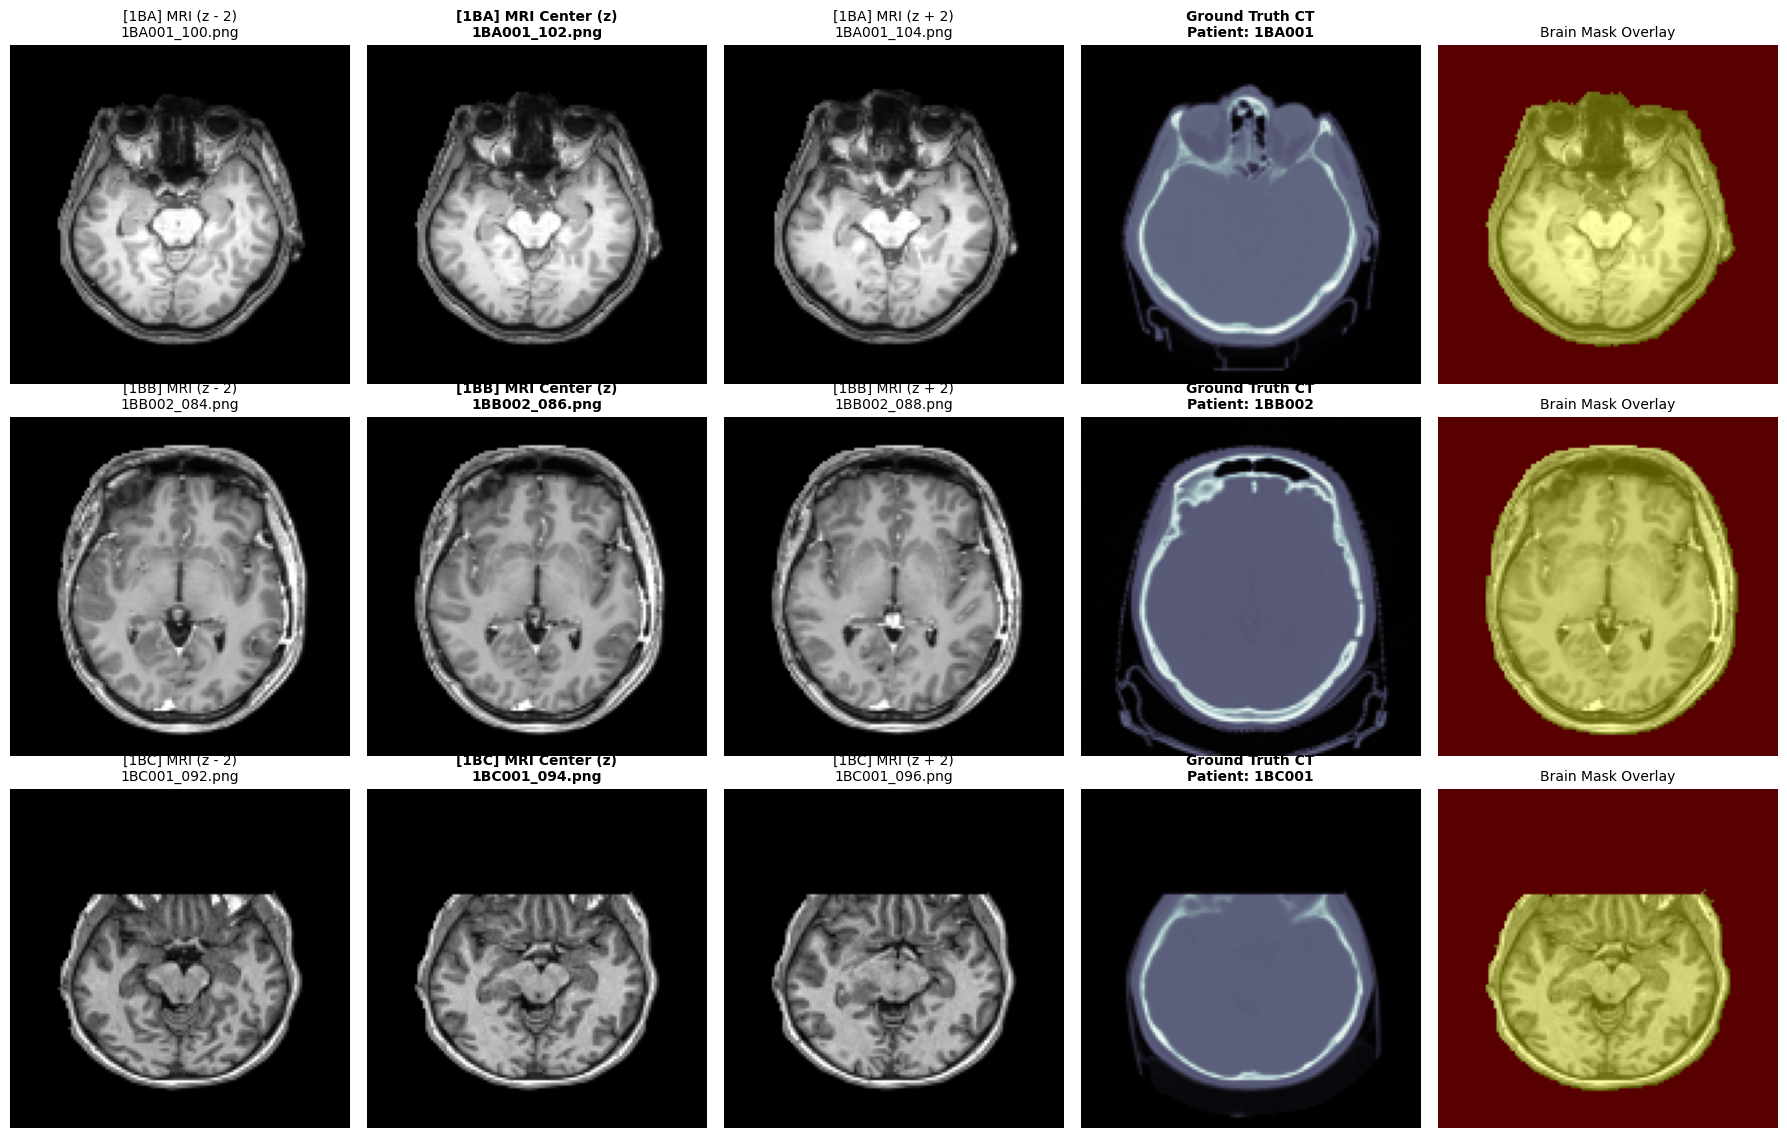

In [5]:
# %% ====== [2.1] VISUALIZATION: Verify Multi-Center Samples & 2.5D Stacks ======
import matplotlib.pyplot as plt

def visualize_dataset_samples(num_samples_per_center=1):
    centers = ["1BA", "1BB", "1BC"]
    sampled_slices = []
    
    # Pick mid-volume slices (where brain structures are clear) from each center
    for prefix in centers:
        center_pids = [p for p in ALL_PIDS if p.startswith(prefix)]
        if center_pids:
            # Pick a patient and a middle slice (slice index around 40-60%)
            for pid in center_pids[:num_samples_per_center]:
                p_slices = PATIENT_SORTED[pid]
                mid_slice = p_slices[int(len(p_slices) * 0.5)]
                sampled_slices.append((prefix, pid, mid_slice))

    n_rows = len(sampled_slices)
    fig, axes = plt.subplots(n_rows, 5, figsize=(18, 3.8 * n_rows))
    if n_rows == 1:
        axes = axes[None, :]

    offsets = (-2, -1, 0, 1, 2)
    
    for row_idx, (center, pid, sname) in enumerate(sampled_slices):
        _, pos = POS[sname]
        p_list = PATIENT_SORTED[pid]
        
        # 1. Fetch 2.5D context slices (-2, 0, +2)
        s_prev = p_list[max(pos - 2, 0)]
        s_mid  = sname
        s_next = p_list[min(pos + 2, len(p_list) - 1)]
        
        mri_prev, _, _ = get_proc_slice(s_prev)
        mri_mid, ct_mid, mask_mid = get_proc_slice(s_mid)
        mri_next, _, _ = get_proc_slice(s_next)
        
        # De-normalize from [-1, 1] to [0, 1] for display
        mri_prev_disp = np.clip((mri_prev + 1.0) / 2.0, 0, 1)
        mri_mid_disp  = np.clip((mri_mid + 1.0) / 2.0, 0, 1)
        mri_next_disp = np.clip((mri_next + 1.0) / 2.0, 0, 1)
        ct_disp       = np.clip((ct_mid + 1.0) / 2.0, 0, 1)
        
        # Column 1: Slice (z - 2)
        axes[row_idx, 0].imshow(mri_prev_disp, cmap="gray")
        axes[row_idx, 0].set_title(f"[{center}] MRI (z - 2)\n{s_prev}", fontsize=10)
        axes[row_idx, 0].axis("off")
        
        # Column 2: Center Slice (z)
        axes[row_idx, 1].imshow(mri_mid_disp, cmap="gray")
        axes[row_idx, 1].set_title(f"[{center}] MRI Center (z)\n{s_mid}", fontsize=10, fontweight="bold")
        axes[row_idx, 1].axis("off")
        
        # Column 3: Slice (z + 2)
        axes[row_idx, 2].imshow(mri_next_disp, cmap="gray")
        axes[row_idx, 2].set_title(f"[{center}] MRI (z + 2)\n{s_next}", fontsize=10)
        axes[row_idx, 2].axis("off")
        
        # Column 4: Ground Truth Target CT (z)
        axes[row_idx, 3].imshow(ct_disp, cmap="bone")
        axes[row_idx, 3].set_title(f"Ground Truth CT\nPatient: {pid}", fontsize=10, fontweight="bold")
        axes[row_idx, 3].axis("off")
        
        # Column 5: Brain Body Mask Overlay
        axes[row_idx, 4].imshow(mri_mid_disp, cmap="gray")
        axes[row_idx, 4].imshow(mask_mid, cmap="autumn", alpha=0.35)
        axes[row_idx, 4].set_title("Brain Mask Overlay", fontsize=10)
        axes[row_idx, 4].axis("off")

    plt.tight_layout()
    plt.show()

# Run the visualizer
visualize_dataset_samples(num_samples_per_center=1)


In [6]:
# %% ====== [3] MODELS: Stage-1 ResUNet, SSIM loss, EMA, diffusion UNet, scheduler ======
class ResBlock(nn.Module):
    def __init__(self, cin, cout, num_groups=8):
        super().__init__()
        g = num_groups if cout % num_groups == 0 else (4 if cout % 4 == 0 else 1)
        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False); self.norm1 = nn.GroupNorm(g, cout)
        self.act1 = nn.LeakyReLU(0.2, inplace=True)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False); self.norm2 = nn.GroupNorm(g, cout)
        self.act2 = nn.LeakyReLU(0.2, inplace=True)
        self.shortcut = (nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.GroupNorm(g, cout))
                         if cin != cout else nn.Identity())

    def forward(self, x):
        r = self.shortcut(x)
        h = self.act1(self.norm1(self.conv1(x)))
        h = self.norm2(self.conv2(h))
        return self.act2(h + r)


class Stage1ResUNet(nn.Module):
    """Same layout/keys as v1 (in_channels=1, base 32 loads legacy checkpoints); in_channels>1 = 2.5D."""

    def __init__(self, in_channels=1, out_channels=1, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1 = ResBlock(in_channels, f); self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ResBlock(f, f * 2);       self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ResBlock(f * 2, f * 4);   self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ResBlock(f * 4, f * 8);   self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = nn.Sequential(ResBlock(f * 8, f * 8), ResBlock(f * 8, f * 8))
        self.up4 = nn.ConvTranspose2d(f * 8, f * 4, 2, 2); self.dec4 = ResBlock(f * 12, f * 4)
        self.up3 = nn.ConvTranspose2d(f * 4, f * 2, 2, 2); self.dec3 = ResBlock(f * 6, f * 2)
        self.up2 = nn.ConvTranspose2d(f * 2, f, 2, 2);     self.dec2 = ResBlock(f * 3, f)
        self.up1 = nn.ConvTranspose2d(f, f, 2, 2);         self.dec1 = ResBlock(f * 2, f)
        self.final_conv = nn.Conv2d(f, out_channels, 1)
        self.final_act = nn.Tanh()

    def extract_encoder_features(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        return {"enc1": e1, "enc2": e2, "enc3": e3, "enc4": e4, "bot": self.bottleneck(self.pool4(e4))}

    def forward(self, x, return_feats=False):
        fe = self.extract_encoder_features(x)
        d4 = self.dec4(torch.cat([self.up4(fe["bot"]), fe["enc4"]], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), fe["enc3"]], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), fe["enc2"]], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), fe["enc1"]], 1))
        out = self.final_act(self.final_conv(d1))
        return (out, fe) if return_feats else out


class DifferentiableSSIM(nn.Module):
    def __init__(self, window_size=11, sigma=1.5, data_range=2.0):
        super().__init__()
        self.ws, self.dr = window_size, data_range
        c = torch.arange(window_size, dtype=torch.float32) - window_size // 2
        g = torch.exp(-(c ** 2) / (2 * sigma ** 2)); g = g / g.sum()
        self.register_buffer("window", torch.outer(g, g)[None, None])

    def forward(self, a, b, mask=None):
        w, p = self.window.to(a.dtype), self.ws // 2
        mu1, mu2 = F.conv2d(a, w, padding=p), F.conv2d(b, w, padding=p)
        s1 = F.conv2d(a * a, w, padding=p) - mu1 ** 2
        s2 = F.conv2d(b * b, w, padding=p) - mu2 ** 2
        s12 = F.conv2d(a * b, w, padding=p) - mu1 * mu2
        c1, c2 = (0.01 * self.dr) ** 2, (0.03 * self.dr) ** 2
        m = ((2 * mu1 * mu2 + c1) * (2 * s12 + c2)) / ((mu1 ** 2 + mu2 ** 2 + c1) * (s1 + s2 + c2) + 1e-8)
        if mask is not None:
            return ((1 - m) * mask).sum() / (mask.sum() + 1e-8)
        return 1 - m.mean()


class EMA:
    def __init__(self, model, decay=0.999):
        self.decay, self.n = decay, 0
        self.shadow = copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        for ps, p in zip(self.shadow.parameters(), model.parameters()):
            ps.mul_(d).add_(p.detach(), alpha=1 - d)


class SinusoidalEmb(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        f = torch.exp(torch.arange(half, device=t.device) * -(math.log(10000.0) / (half - 1)))
        a = t.float()[:, None] * f[None, :]
        return torch.cat([a.sin(), a.cos()], -1)


def _gn(ch):
    return nn.GroupNorm(8 if ch % 8 == 0 else 4, ch)


class FiLM(nn.Module):
    """(1+gamma)*x + beta from Stage-1 encoder features; zero-init => identity at start."""

    def __init__(self, ch, cond_ch):
        super().__init__()
        self.proj = nn.Sequential(nn.SiLU(), nn.Conv2d(cond_ch, ch * 2, 1))
        nn.init.zeros_(self.proj[-1].weight); nn.init.zeros_(self.proj[-1].bias)

    def forward(self, x, cond):
        if cond.shape[2:] != x.shape[2:]:
            cond = F.interpolate(cond, size=x.shape[2:], mode="bilinear", align_corners=False)
        gamma, beta = self.proj(cond).chunk(2, dim=1)
        return (1 + gamma) * x + beta


class DResBlock(nn.Module):
    def __init__(self, cin, cout, t_dim, cond_ch=None):
        super().__init__()
        self.t_proj = nn.Linear(t_dim, cout)
        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1); self.gn1 = _gn(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1); self.gn2 = _gn(cout)
        self.act = nn.SiLU()
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
        self.film = FiLM(cout, cond_ch) if cond_ch is not None else None

    def forward(self, x, t_emb, cond=None):
        h = self.act(self.gn1(self.conv1(x)))
        h = h + self.t_proj(t_emb)[:, :, None, None]
        h = self.act(self.gn2(self.conv2(h)))
        out = h + self.skip(x)
        if self.film is not None and cond is not None:
            out = self.film(out, cond)
        return out


class DiffUNet(nn.Module):
    """Denoiser / deterministic refiner. in_ch = z(1) + mask(1) + [coarse] + [MRI slices]."""

    def __init__(self, in_ch, base=48, t_dim=128, cond_channels=(32, 64, 128, 256), film=True):
        super().__init__()
        c, td = base, t_dim
        cc = tuple(cond_channels) if film else (None, None, None, None)
        self.time_mlp = nn.Sequential(SinusoidalEmb(td), nn.Linear(td, td * 2), nn.SiLU(),
                                      nn.Linear(td * 2, td), nn.SiLU())
        self.enc1 = DResBlock(in_ch, c, td);   self.down1 = nn.Conv2d(c, c, 3, 2, 1)
        self.enc2 = DResBlock(c, c * 2, td);   self.down2 = nn.Conv2d(c * 2, c * 2, 3, 2, 1)
        self.enc3 = DResBlock(c * 2, c * 4, td); self.down3 = nn.Conv2d(c * 4, c * 4, 3, 2, 1)
        self.enc4 = DResBlock(c * 4, c * 8, td); self.down4 = nn.Conv2d(c * 8, c * 8, 3, 2, 1)
        self.bot1 = DResBlock(c * 8, c * 8, td); self.bot2 = DResBlock(c * 8, c * 8, td)
        self.up4 = nn.ConvTranspose2d(c * 8, c * 8, 2, 2); self.dec4 = DResBlock(c * 16, c * 4, td, cc[3])
        self.up3 = nn.ConvTranspose2d(c * 4, c * 4, 2, 2); self.dec3 = DResBlock(c * 8, c * 2, td, cc[2])
        self.up2 = nn.ConvTranspose2d(c * 2, c * 2, 2, 2); self.dec2 = DResBlock(c * 4, c, td, cc[1])
        self.up1 = nn.ConvTranspose2d(c, c, 2, 2);         self.dec1 = DResBlock(c * 2, c, td, cc[0])
        self.final_conv = nn.Conv2d(c, 1, 1)

    def forward(self, x, t, cond):
        te = self.time_mlp(t)
        e1 = self.enc1(x, te);               e2 = self.enc2(self.down1(e1), te)
        e3 = self.enc3(self.down2(e2), te);  e4 = self.enc4(self.down3(e3), te)
        b = self.bot2(self.bot1(self.down4(e4), te), te)
        g = (lambda k: cond[k]) if cond is not None else (lambda k: None)
        d = self.dec4(torch.cat([self.up4(b), e4], 1), te, g("enc4"))
        d = self.dec3(torch.cat([self.up3(d), e3], 1), te, g("enc3"))
        d = self.dec2(torch.cat([self.up2(d), e2], 1), te, g("enc2"))
        d = self.dec1(torch.cat([self.up1(d), e1], 1), te, g("enc1"))
        return self.final_conv(d)


class CosineScheduler:
    def __init__(self, T=1000, s=0.008, dev="cpu"):
        t = torch.linspace(0, T, T + 1, dtype=torch.float64)
        f = torch.cos(((t / T) + s) / (1 + s) * math.pi / 2) ** 2
        ab = f / f[0]
        betas = (1 - ab[1:] / ab[:-1]).clamp(max=0.999)
        self.alphas_cumprod = torch.cumprod(1 - betas, 0).float().to(dev)
        self.T = T

    def ab(self, t):
        a = self.alphas_cumprod[t].view(-1, 1, 1, 1)
        return a.sqrt(), (1 - a).sqrt()

    def q_sample(self, z0, t, noise):
        a, s = self.ab(t); return a * z0 + s * noise

    def v_target(self, z0, noise, t):
        a, s = self.ab(t); return a * noise - s * z0


sched = CosineScheduler(T_STEPS, dev=device)


def out_to_z0(out, z_t, t, pred):
    a, s = sched.ab(t)
    return a * z_t - s * out if pred == "v" else (z_t - s * out) / (a + 1e-8)


def build_input(cfg, z, mask, coarse, mri):
    ch = [z, mask]
    if cfg["coarse_ch"]:
        ch.append(coarse)
    if cfg["mri_ch"]:
        ch.append(mri)
    return torch.cat(ch, 1)




In [7]:
# %% ====== [4] STAGE-1: leakage-free fold training, bundle (coarse + features + scale) ======
def _l1(pred, tgt, mask):
    return (torch.abs(pred - tgt) * mask).sum() / (mask.sum() + 1e-8)


def _find_legacy(k):
    for root in ("/kaggle/working/synthrad_ccr_diffusion/checkpoints/coarse_resunet", "/kaggle/input"):
        hits = glob.glob(os.path.join(root, "**", f"coarse_resunet_fold_{k}.pth"), recursive=True)
        if hits:
            return sorted(hits, key=len)[0]
    return None


def train_stage1_fold(tag, offsets, k):
    path = os.path.join(DIR_S1, f"s1_{tag}_fold{k}.pth")
    model = Stage1ResUNet(len(offsets), 1, S1_BASE).to(device)
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device, weights_only=False)["model_state_dict"])
        return model.eval()
    if REUSE_LEGACY_2D and tag == "2d" and _find_legacy(k):
        model.load_state_dict(torch.load(_find_legacy(k), map_location=device, weights_only=False)["model_state_dict"])
        print(f"[legacy] 2d fold {k} loaded from {_find_legacy(k)}")
        return model.eval()
    seed_everything(SEED + k)
    d = get_split("train", TRAIN_SNAMES, offsets)
    tr_idx = (d["fold"] != k).nonzero().squeeze(1).tolist()
    loader = DataLoader(Subset(SplitDataset(d, True), tr_idx), batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=NUM_WORKERS, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=S1_LR, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=S1_EPOCHS, eta_min=1e-6)
    ssim = DifferentiableSSIM().to(device)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ema = EMA(model, S1_EMA)
    for ep in range(1, S1_EPOCHS + 1):
        model.train(); run = 0.0
        for b in loader:
            mri, ct, mask = b["mri"].to(device), b["ct"].to(device), b["mask"].to(device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                pred = model(mri)
            pred = pred.float()
            ct_t = torch.where(mask > 0.5, ct, torch.full_like(ct, -1.0))
            pred_m = torch.where(mask > 0.5, pred, torch.full_like(pred, -1.0))
            loss = _l1(pred, ct, mask) + 0.10 * ssim(pred_m, ct_t, mask=mask)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); ema.update(model); run += loss.item()
        sch.step()
        if ep % 10 == 0 or ep == S1_EPOCHS:
            print(f"  [{tag}] fold {k} ep {ep}/{S1_EPOCHS} train loss {run / len(loader):.4f}")
    final = ema.shadow                                   # fixed schedule, final EMA weights: NO selection
    ho_idx = (d["fold"] == k).nonzero().squeeze(1)
    with torch.no_grad():                                # report held-out L1 for information only
        v = []
        for i in range(0, len(ho_idx), 32):
            ii = ho_idx[i:i + 32]
            mri, ct, mask = d["mri"][ii].to(device), d["ct"][ii].to(device), d["mask"][ii].to(device)
            v.append(_l1(final(mri), ct, mask).item())
    print(f"  [{tag}] fold {k} held-out masked L1 (info only): {np.mean(v):.4f}")
    torch.save({"model_state_dict": final.state_dict(), "tag": tag, "fold": k, "offsets": list(offsets),
                "provenance": {"oof_pids": FOLDS[k], "train_pids": [p for j, ps in FOLDS.items() if j != k for p in ps],
                               "selection": "none (fixed epochs, final EMA weights)"}}, path)
    return final.eval()


class Stage1Bundle:
    def __init__(self, tag):
        self.tag, self.offsets = tag, S1_VARIANTS[tag]
        self.models = {}
        for k in range(1, N_FOLDS + 1):
            m = train_stage1_fold(tag, self.offsets, k).eval()
            for p in m.parameters():
                p.requires_grad_(False)
            self.models[k] = m
        self.cond_ch = tuple(S1_BASE * x for x in (1, 2, 4, 8))
        self.S = self._residual_scale()

    @torch.no_grad()
    def _residual_scale(self):
        f = os.path.join(DIR_METRICS, f"residual_scale_{self.tag}.json")
        if os.path.exists(f):
            return json.load(open(f))["S"]
        d = get_split("train", TRAIN_SNAMES, self.offsets)
        vals = []
        for k in range(1, N_FOLDS + 1):
            idx = (d["fold"] == k).nonzero().squeeze(1)
            for i in range(0, len(idx), 32):
                ii = idx[i:i + 32]
                mri, ct, mask = d["mri"][ii].to(device), d["ct"][ii].to(device), d["mask"][ii].to(device)
                vals.append((ct - self.models[k](mri))[mask > 0.5].cpu())
        S = float(torch.cat(vals).std(unbiased=False).clamp_min(1e-6))
        json.dump({"S": S}, open(f, "w"))
        return S

    @torch.no_grad()
    def coarse_feats_k(self, mri, mask, k):
        c, f = self.models[k](mri, return_feats=True)
        return torch.where(mask > 0.5, c, torch.full_like(c, -1.0)), f

    @torch.no_grad()
    def coarse_feats(self, mri, mask, folds):
        """Per-sample: coarse + features from the fold model that HELD THAT PATIENT OUT."""
        B, coarse, feats = mri.size(0), torch.empty_like(mri[:, :1]), None
        for k in folds.unique().tolist():
            idx = (folds == k).nonzero(as_tuple=True)[0]
            c_k, f_k = self.models[k](mri[idx], return_feats=True)
            if feats is None:
                feats = {n: torch.empty((B,) + f.shape[1:], device=mri.device, dtype=f.dtype) for n, f in f_k.items()}
            coarse[idx] = c_k
            for n in f_k:
                feats[n][idx] = f_k[n]
        return torch.where(mask > 0.5, coarse, torch.full_like(coarse, -1.0)), feats


BUNDLES = {}


def get_bundle(tag):
    if tag not in BUNDLES:
        BUNDLES[tag] = Stage1Bundle(tag)
    return BUNDLES[tag]


@torch.no_grad()
def stage1_ensemble(bundle, d, bs=32):
    out = []
    for mri, ct, mask, sl in iter_batches(d, bs):
        out.append(torch.stack([bundle.coarse_feats_k(mri, mask, k)[0] for k in range(1, N_FOLDS + 1)]).mean(0)[:, 0].cpu().numpy())
    return np.concatenate(out)




In [8]:
# %% ====== [5] STAGE-2: sampler, prediction stack, training ===================
@torch.no_grad()
def sample_residual(model, cfg, S, mri, coarse, feats, mask, steps=50, generator=None):
    """Residual in intensity units (= s * z0). 'det' = one forward pass; 'diff' = DDIM (eta=0)."""
    model.eval()
    b, dev = coarse.size(0), coarse.device
    if cfg["mode"] == "det":
        t = torch.zeros(b, dtype=torch.long, device=dev)
        with torch.amp.autocast("cuda", enabled=use_amp):
            out = model(build_input(cfg, torch.zeros_like(coarse), mask, coarse, mri), t, feats)
        return out.float() * S * mask
    z = torch.randn(coarse.shape, device=dev, generator=generator) * mask
    ts = sorted(set(torch.linspace(0, sched.T - 1, steps).long().tolist()), reverse=True)
    ab = sched.alphas_cumprod
    for i, tv in enumerate(ts):
        t = torch.full((b,), tv, device=dev, dtype=torch.long)
        with torch.amp.autocast("cuda", enabled=use_amp):
            out = model(build_input(cfg, z, mask, coarse, mri), t, feats)
        out = out.float()
        a = ab[tv]
        a_prev = ab[ts[i + 1]] if i + 1 < len(ts) else torch.ones((), device=dev)
        if cfg["pred"] == "v":
            z0 = a.sqrt() * z - (1 - a).sqrt() * out
            eps = (1 - a).sqrt() * z + a.sqrt() * out
        else:
            eps = out
            z0 = (z - (1 - a).sqrt() * eps) / (a.sqrt() + 1e-8)
        z0 = z0.clamp(-Z_CLIP, Z_CLIP) * mask
        z = (a_prev.sqrt() * z0 + (1 - a_prev).sqrt() * eps * mask) * mask
    return z * S * mask


@torch.no_grad()
def predict_stack(d, model, cfg, bundle, n_samples, steps, folds=(1, 2, 3, 4), flips=(False,), bs=16, seed=SEED):
    """coarse[F,L,N,H,W] and res[F,L,S,N,H,W] for every (fold, flip, sample): any ensemble is a free subset."""
    N, H = d["mri"].size(0), IMAGE_SIZE
    ns = n_samples if cfg["mode"] == "diff" else 1
    coarse = np.zeros((len(folds), len(flips), N, H, H), np.float32)
    res = np.zeros((len(folds), len(flips), ns, N, H, H), np.float32)
    g = torch.Generator(device=device).manual_seed(seed)
    for mri, ct, mask, sl in iter_batches(d, bs):
        for fi, k in enumerate(folds):
            for li, fl in enumerate(flips):
                m_in, mk = (mri.flip(-1), mask.flip(-1)) if fl else (mri, mask)
                c, f = bundle.coarse_feats_k(m_in, mk, k)
                coarse[fi, li, sl] = (c.flip(-1) if fl else c)[:, 0].cpu().numpy()
                for si in range(ns):
                    r = sample_residual(model, cfg, bundle.S, m_in, c, f, mk, steps, g)
                    res[fi, li, si, sl] = (r.flip(-1) if fl else r)[:, 0].cpu().numpy()
    return {"coarse": coarse, "res": res}


def quick_validate(model, cfg, bundle, d_val):
    st = predict_stack(d_val, model, cfg, bundle, QV["samples"], QV["steps"], folds=QV["folds"])
    c, r = aggregate(st)
    m, _ = patient_level(finalize(c, r, d_val["mask"][:, 0].numpy()), d_val["ct"][:, 0].numpy(),
                         d_val["mask"][:, 0].numpy(), d_val["pid"])
    return m


def make_sig(cfg, epochs):
    return {"cfg": cfg, "S": round(get_bundle(cfg["s1"]).S, 8), "epochs": epochs, "v": PIPELINE_VERSION}


def _paths(name, epochs):
    b = os.path.join(DIR_S2, f"s2_{name}_e{epochs}")
    return b + "_latest.pth", b + "_best.pth"


def train_stage2(name, cfg, epochs):
    bundle = get_bundle(cfg["s1"])
    d_tr, d_va = get_split("train", TRAIN_SNAMES, bundle.offsets), get_split("val", VAL_SNAMES, bundle.offsets)
    loader = DataLoader(SplitDataset(d_tr, True), batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=NUM_WORKERS, drop_last=True, pin_memory=use_amp)
    seed_everything(cfg["seed"])
    in_ch = 2 + int(cfg["coarse_ch"]) + (len(bundle.offsets) if cfg["mri_ch"] else 0)
    model = DiffUNet(in_ch, cfg["base_ch"], T_DIM, bundle.cond_ch, film=cfg["film"]).to(device)
    ema = EMA(model, EMA_DECAY)
    opt = torch.optim.AdamW(model.parameters(), lr=S2_LR, weight_decay=S2_WD)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ssim_crit = DifferentiableSSIM().to(device)
    latest, best = _paths(name, epochs)
    sig = make_sig(cfg, epochs)
    start, step, best_score, hist = 0, 0, float("inf"), []
    if os.path.exists(latest):
        ck = torch.load(latest, map_location=device, weights_only=False)
        if ck.get("sig") == sig:
            model.load_state_dict(ck["model"]); ema.shadow.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]
            opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
            start, best_score, hist = ck["epoch"], ck["best_score"], ck["history"]; step = start * len(loader)
            print(f"[resume] {name} from epoch {start}")
        else:
            shutil.move(latest, latest.replace("_latest", f"_stale{int(time.time())}"))
    total = epochs * len(loader)

    def lr_at(s):
        return (1e-6 + (S2_LR - 1e-6) * 0.5 * (1 + math.cos(math.pi * min(s / total, 1.0)))) * min(1.0, (s + 1) / S2_WARMUP)

    t0 = time.time()
    for epoch in range(start + 1, epochs + 1):
        model.train(); acc, n = np.zeros(4), 0
        for b in tqdm(loader, desc=f"{name} {epoch}/{epochs}", leave=False):
            mri, ct, mask = b["mri"].to(device), b["ct"].to(device), b["mask"].to(device)
            folds = b["fold"].to(device)
            if cfg["cond"] == "fixed":
                folds = torch.ones_like(folds)                           # v1 behaviour: fold-1 model for every slice
            coarse, feats = bundle.coarse_feats(mri, mask, folds)
            S = bundle.S
            z0 = ((ct - coarse) / S) * mask
            bs_ = z0.size(0)
            if cfg["mode"] == "diff":
                t = torch.randint(0, T_STEPS, (bs_,), device=device)
                noise = torch.randn_like(z0) * mask
                z_in = sched.q_sample(z0, t, noise) * mask
                tgt = sched.v_target(z0, noise, t) if cfg["pred"] == "v" else noise
            else:
                t = torch.zeros(bs_, dtype=torch.long, device=device)
                z_in, tgt = torch.zeros_like(z0), z0
            for g_ in opt.param_groups:
                g_["lr"] = lr_at(step)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                out = model(build_input(cfg, z_in, mask, coarse, mri), t, feats)
            out = out.float()
            if cfg["bone_w"] != 1.0:
                gate = F.avg_pool2d((coarse > LOSS_BONE_THR).float(), 7, 1, 3)
                W = (1 + (cfg["bone_w"] - 1) * gate) * mask
            else:
                W = mask
            err = torch.abs(out - tgt) if cfg["mode"] == "det" else (out - tgt) ** 2
            l_main = ((err * W).sum((1, 2, 3)) / (W.sum((1, 2, 3)) + 1e-8)).mean()
            if cfg["mode"] == "diff":
                sel = t <= SSIM_T_CUTOFF
                z0_hat = out_to_z0(out, z_in, t, cfg["pred"]) if sel.any() else None
                z0_hat = z0_hat[sel] if sel.any() else None
            else:
                sel, z0_hat = torch.ones(bs_, dtype=torch.bool, device=device), out
            l_ssim = l_x0 = torch.zeros((), device=device)
            if sel.any() and (cfg["aux_ssim"] > 0 or cfg["x0_l1"] > 0):
                ct_hat = (coarse[sel] + z0_hat * mask[sel] * S).clamp(-1, 1)
                ct_t = torch.where(mask[sel] > 0.5, ct[sel], torch.full_like(ct[sel], -1.0))   # I6: target = -1 outside mask
                if cfg["aux_ssim"] > 0:
                    l_ssim = ssim_crit(ct_hat, ct_t, mask=mask[sel])
                if cfg["x0_l1"] > 0:
                    l_x0 = _l1(ct_hat, ct_t, mask[sel])
            loss = l_main + cfg["aux_ssim"] * l_ssim + cfg["x0_l1"] * l_x0
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); ema.update(model); step += 1
            acc += [loss.item(), l_main.item(), l_ssim.item(), l_x0.item()]; n += 1
        acc /= n
        rec = {"epoch": epoch, "loss": acc[0], "main": acc[1], "aux_ssim": acc[2], "x0_l1": acc[3]}
        if epoch % VAL_FREQ == 0 or epoch == epochs:
            m = quick_validate(ema.shadow, cfg, bundle, d_va)
            rec.update({f"val_{k}": v for k, v in m.items()})
            star = ""
            if m["Score"] < best_score:
                best_score, star = m["Score"], "  <-- best"
                torch.save({"ema": ema.shadow.state_dict(), "epoch": epoch, "metrics": m, "sig": sig}, best)
            print(f"[{name}] ep {epoch:3d} loss {acc[0]:.4f} | EMA val Score {m['Score']:.4f} MAE {m['MAE']:.4f} "
                  f"SSIM {m['SSIM']:.4f} PSNR {m['PSNR']:.2f}{star}  ({(time.time() - t0) / 60:.1f} min)")
        hist.append(rec)
        torch.save({"epoch": epoch, "model": model.state_dict(), "ema": ema.shadow.state_dict(), "ema_n": ema.n,
                    "opt": opt.state_dict(), "scaler": scaler.state_dict(), "best_score": best_score,
                    "history": hist, "sig": sig}, latest)
    pd.DataFrame(hist).to_csv(os.path.join(DIR_METRICS, f"history_{name}_e{epochs}.csv"), index=False)


def get_stage2(name, cfg, epochs, which="best"):
    """Train if needed, then load. which: 'best' (val-selected EMA) | 'final_ema' | 'final_raw'."""
    latest, best = _paths(name, epochs)
    done = False
    if os.path.exists(latest):
        ck = torch.load(latest, map_location=device, weights_only=False)
        done = ck["epoch"] >= epochs and os.path.exists(best) and ck.get("sig") == make_sig(cfg, epochs)
    if not done:
        train_stage2(name, cfg, epochs)
    bundle = get_bundle(cfg["s1"])
    in_ch = 2 + int(cfg["coarse_ch"]) + (len(bundle.offsets) if cfg["mri_ch"] else 0)
    model = DiffUNet(in_ch, cfg["base_ch"], T_DIM, bundle.cond_ch, film=cfg["film"]).to(device)
    if which == "best":
        model.load_state_dict(torch.load(best, map_location=device, weights_only=False)["ema"])
    else:
        ck = torch.load(latest, map_location=device, weights_only=False)
        model.load_state_dict(ck["ema"] if which == "final_ema" else ck["model"])
    return model.eval()


def make_cfg(overrides, main_s1):
    c = dict(BASE_CFG); c.update(overrides)
    if c["s1"] is None:
        c["s1"] = main_s1
    return c

In [ ]:
# %% ====== [6] STAGE-1 ABLATION (2D vs 2.5D) + choose the Stage-1 variant =========
VALd0 = get_split("val", VAL_SNAMES, (0,))
v_gt, v_mask, v_pid = VALd0["ct"][:, 0].numpy(), VALd0["mask"][:, 0].numpy(), VALd0["pid"]
s1_rows, S1_VAL_PRED = [], {}
for tag in S1_TO_RUN:
    b = get_bundle(tag)
    dv = get_split("val", VAL_SNAMES, b.offsets)
    pred = finalize(stage1_ensemble(b, dv), 0, v_mask)
    S1_VAL_PRED[tag] = pred
    m, _ = patient_level(pred, v_gt, v_mask, v_pid)
    s1_rows.append({"stage1": tag, "offsets": str(b.offsets), **m})
s1_table = pd.DataFrame(s1_rows); print(s1_table.round(5).to_string(index=False))
s1_table.to_csv(os.path.join(DIR_METRICS, "ablation_stage1_val.csv"), index=False)
MAIN_S1 = s1_table.sort_values("Score").iloc[0]["stage1"]
print("Selected Stage-1 variant (lowest val Score):", MAIN_S1)

  [2d] fold 1 ep 10/40 train loss 0.0582
  [2d] fold 1 ep 20/40 train loss 0.0485
  [2d] fold 1 ep 30/40 train loss 0.0436
  [2d] fold 1 ep 40/40 train loss 0.0420
  [2d] fold 1 held-out masked L1 (info only): 0.1415
  [2d] fold 2 ep 10/40 train loss 0.0559
  [2d] fold 2 ep 20/40 train loss 0.0466
  [2d] fold 2 ep 30/40 train loss 0.0417
  [2d] fold 2 ep 40/40 train loss 0.0401
  [2d] fold 2 held-out masked L1 (info only): 0.1429
  [2d] fold 3 ep 10/40 train loss 0.0553
  [2d] fold 3 ep 20/40 train loss 0.0460
  [2d] fold 3 ep 30/40 train loss 0.0412
  [2d] fold 3 ep 40/40 train loss 0.0396
  [2d] fold 3 held-out masked L1 (info only): 0.1479
  [2d] fold 4 ep 10/40 train loss 0.0551
  [2d] fold 4 ep 20/40 train loss 0.0460
  [2d] fold 4 ep 30/40 train loss 0.0413
  [2d] fold 4 ep 40/40 train loss 0.0397
  [2d] fold 4 held-out masked L1 (info only): 0.1565


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


  [25d1] fold 1 ep 10/40 train loss 0.0571
  [25d1] fold 1 ep 20/40 train loss 0.0471
  [25d1] fold 1 ep 30/40 train loss 0.0422
  [25d1] fold 1 ep 40/40 train loss 0.0405
  [25d1] fold 1 held-out masked L1 (info only): 0.1405
  [25d1] fold 2 ep 10/40 train loss 0.0552
  [25d1] fold 2 ep 20/40 train loss 0.0453
  [25d1] fold 2 ep 30/40 train loss 0.0404
  [25d1] fold 2 ep 40/40 train loss 0.0388
  [25d1] fold 2 held-out masked L1 (info only): 0.1430
  [25d1] fold 3 ep 10/40 train loss 0.0535
  [25d1] fold 3 ep 20/40 train loss 0.0441
  [25d1] fold 3 ep 30/40 train loss 0.0394
  [25d1] fold 3 ep 40/40 train loss 0.0378
  [25d1] fold 3 held-out masked L1 (info only): 0.1479
  [25d1] fold 4 ep 10/40 train loss 0.0535
  [25d1] fold 4 ep 20/40 train loss 0.0442
  [25d1] fold 4 ep 30/40 train loss 0.0394
  [25d1] fold 4 ep 40/40 train loss 0.0379
  [25d1] fold 4 held-out masked L1 (info only): 0.1553


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


  [25d2] fold 1 ep 10/40 train loss 0.0562


In [ ]:
# %% ====== [7] STAGE-2 ABLATION (validation only) ===============================
ABL_CSV = os.path.join(DIR_METRICS, f"ablation_stage2_val_e{ABL_EPOCHS}.csv")
abl_done = pd.read_csv(ABL_CSV).to_dict("records") if os.path.exists(ABL_CSV) else []
done_names = {r["variant"] for r in abl_done}
for name in ABLATIONS_TO_RUN:
    if name in done_names:
        continue
    cfg = make_cfg(ABLATIONS[name], MAIN_S1)
    model = get_stage2(name, cfg, ABL_EPOCHS)
    b = get_bundle(cfg["s1"]); dv = get_split("val", VAL_SNAMES, b.offsets)
    folds_ = (1,) if cfg["cond"] == "fixed" else ABL_PROTOCOL["folds"]      # v1-style model is only valid with fold-1 features
    st = predict_stack(dv, model, cfg, b, ABL_PROTOCOL["samples"], ABL_PROTOCOL["steps"], folds=folds_)
    c, r = aggregate(st)
    row = summarize_pred(name, c, r, v_gt, v_mask, v_pid)
    row["stage1_used"] = cfg["s1"]
    row["Stage1_only_Score"] = patient_level(finalize(c, 0 * r, v_mask), v_gt, v_mask, v_pid)[0]["Score"]
    abl_done.append(row)
    pd.DataFrame(abl_done).to_csv(ABL_CSV, index=False)
    del model; torch.cuda.empty_cache()
abl_table = pd.DataFrame(abl_done)
print(abl_table.round(5).to_string(index=False))

In [ ]:
# %% ====== [8] CHOOSE + TRAIN THE FINAL MODEL (full epochs) =====================
diff_rows = abl_table[abl_table["variant"].isin([n for n in ABLATIONS if ABLATIONS[n].get("mode", "diff") == "diff" and ABLATIONS[n].get("cond", "oof") == "oof"])]
if FINAL_NAME is None:
    FINAL_NAME = diff_rows.sort_values("Score(w*)").iloc[0]["variant"]
print("Final config:", FINAL_NAME, ABLATIONS[FINAL_NAME])
FINAL_CFG = make_cfg(ABLATIONS[FINAL_NAME], MAIN_S1)
FINAL_TAG = FINAL_NAME if ABL_EPOCHS == FINAL_EPOCHS else f"final_{FINAL_NAME}"
final_model = get_stage2(FINAL_TAG, FINAL_CFG, FINAL_EPOCHS)
FB = get_bundle(FINAL_CFG["s1"])
VALd = get_split("val", VAL_SNAMES, FB.offsets)

In [ ]:
import os
import shutil
import zipfile
from pathlib import Path
from IPython.display import display, FileLink

# =====================================================
# 1. FIND THE OUTPUT FOLDER
# =====================================================

working_dir = Path("/kaggle/working")

preferred_folders = [
    working_dir / "synthrad_ccr_v2",
    working_dir / "synthrad_ccr_v3",
    working_dir / "synthrad_ccr_diffusion",
]

folder_path = next(
    (p for p in preferred_folders if p.is_dir()),
    None
)

# Search other top-level output folders if necessary
if folder_path is None:
    candidates = [
        p for p in working_dir.iterdir()
        if p.is_dir()
        and ("synthrad" in p.name.lower() or "ccr" in p.name.lower())
        and any(f.is_file() for f in p.rglob("*"))
    ]

    if candidates:
        print("Available candidate folders:")
        for i, p in enumerate(candidates, 1):
            print(f"{i}. {p}")

        # Prefer the most recently modified candidate
        folder_path = max(
            candidates,
            key=lambda p: p.stat().st_mtime
        )

    else:
        print("No matching output folders found.")
        print("\nCurrent /kaggle/working contents:")
        for p in working_dir.iterdir():
            print(" -", p.name)

        raise FileNotFoundError(
            "Run the model/output cells first, or set folder_path "
            "to the actual directory shown above."
        )

print("Folder selected:", folder_path)

# =====================================================
# 2. CREATE THE ZIP ARCHIVE
# =====================================================

output_base = working_dir / f"{folder_path.name}_backup"

zip_path = shutil.make_archive(
    str(output_base),
    "zip",
    root_dir=str(folder_path)
)

# =====================================================
# 3. VERIFY THE ZIP
# =====================================================

with zipfile.ZipFile(zip_path, "r") as archive:
    bad_file = archive.testzip()

if bad_file:
    raise RuntimeError(f"ZIP verification failed: {bad_file}")

print("\nZIP created and verified successfully.")
print("File:", zip_path)
print(f"Size: {os.path.getsize(zip_path) / (1024**2):.2f} MB")

# =====================================================
# 4. DISPLAY DOWNLOAD LINK
# =====================================================

print("\nClick the link below to download your ZIP file:")
display(FileLink(zip_path))


In [ ]:
# %% ====== [9] INFERENCE ABLATIONS (no retraining, validation) ===================
P = FINAL_PROTOCOL
val_stack = predict_stack(VALd, final_model, FINAL_CFG, FB, P["samples"], P["steps"], folds=P["folds"], flips=P["flips"])
nF, nL, nS = val_stack["res"].shape[:3]
sweep = []


def add(name, **kw):
    c, r = aggregate(val_stack, **kw)
    sweep.append(summarize_pred(name, c, r, v_gt, v_mask, v_pid))


sweep.append({"variant": "Stage-1 only", **{k: v for k, v in patient_level(finalize(aggregate(val_stack, lidx=[0], sidx=[0])[0], 0, v_mask), v_gt, v_mask, v_pid)[0].items() if k in ("MAE", "SSIM", "PSNR", "Score")}})
add("1 sample, 1 fold, no TTA", fidx=[0], lidx=[0], sidx=[0])
for s in range(1, nS + 1):
    add(f"{s} sample(s), all folds, no TTA", lidx=[0], sidx=list(range(s)))
for f_ in (1, 2, nF):
    add(f"{nS} samples, {f_} fold(s), no TTA", fidx=list(range(f_)), lidx=[0])
if nL > 1:
    add(f"{nS} samples, all folds, flip-TTA", sidx=list(range(nS)))
sweep_table = pd.DataFrame(sweep); print(sweep_table.round(5).to_string(index=False))
sweep_table.to_csv(os.path.join(DIR_METRICS, "inference_ablation_val.csv"), index=False)

# DDIM steps (1 fold, 1 sample) and EMA vs raw weights (cheap protocol)
extra = []
if FINAL_CFG["mode"] == "diff":
    for st_ in (10, 25, 50, 100):
        s_ = predict_stack(VALd, final_model, FINAL_CFG, FB, 1, st_, folds=(1,))
        c, r = aggregate(s_); extra.append(summarize_pred(f"DDIM steps={st_} (1 fold, 1 sample)", c, r, v_gt, v_mask, v_pid))
for which in ("best", "final_ema", "final_raw"):
    m_ = get_stage2(FINAL_TAG, FINAL_CFG, FINAL_EPOCHS, which=which)
    s_ = predict_stack(VALd, m_, FINAL_CFG, FB, 2, 25, folds=(1, 2, 3, 4))
    c, r = aggregate(s_); extra.append(summarize_pred(f"weights={which} (4 folds x 2 samples, 25 steps)", c, r, v_gt, v_mask, v_pid))
extra_table = pd.DataFrame(extra); print(extra_table.round(5).to_string(index=False))
extra_table.to_csv(os.path.join(DIR_METRICS, "steps_and_ema_ablation_val.csv"), index=False)

# Blend tuning on VAL ONLY: scalar w and the coarse-intensity gate
c_val, r_val = aggregate(val_stack)                         # final protocol: all folds, all flips, all samples
w_best = wstar(c_val, r_val, v_gt, v_mask)
best_cfg, best_sc = None, 1e9
for thr in (-0.15, 0.04):                                   # intensity gates; NOT verified HU thresholds
    for w_soft in (0.0, 0.25, 0.5, 0.75, 1.0):
        for w_bone in (0.5, 0.75, 1.0):
            m_, _ = patient_level(blend(c_val, r_val, v_mask, w_soft, w_bone, thr), v_gt, v_mask, v_pid)
            if m_["Score"] < best_sc:
                best_sc, best_cfg = m_["Score"], (w_soft, w_bone, thr)
print(f"val-optimal scalar w* = {w_best:.3f} | best gate (w_soft, w_bone, thr) = {best_cfg} (Score {best_sc:.5f})")

In [ ]:
# %% ====== [10] FINAL TEST (run ONCE; nothing below may be used for tuning) ======
TESTd = get_split("test", TEST_SNAMES, FB.offsets)
t_gt, t_mask, t_pid = TESTd["ct"][:, 0].numpy(), TESTd["mask"][:, 0].numpy(), TESTd["pid"]
test_stack = predict_stack(TESTd, final_model, FINAL_CFG, FB, P["samples"], P["steps"], folds=P["folds"], flips=P["flips"])
c1, r1 = aggregate(test_stack, fidx=[0], lidx=[0], sidx=[0])
cE, rE = aggregate(test_stack, lidx=[0])                    # ensemble, no TTA
cT, rT = aggregate(test_stack)                              # ensemble + TTA
preds = {
    f"Stage-1 [{FINAL_CFG['s1']}] (4-fold ensemble)": finalize(cE, 0, t_mask),
    f"Diffusion {FINAL_NAME}: 1 sample, 1 fold": finalize(c1, r1, t_mask),
    "+ ensemble (4 folds x samples), w=1": finalize(cE, rE, t_mask),
    "+ flip-TTA, w=1": finalize(cT, rT, t_mask),
    f"+ val-optimal scalar w*={w_best:.2f}": finalize(cT, rT, t_mask, w_best),
    f"+ val-tuned gate {best_cfg}": blend(cT, rT, t_mask, *best_cfg),
}
# fixed-in-advance baselines for context: Stage-1 2D, and the deterministic refiner(s)
if "2d" in S1_TO_RUN and FINAL_CFG["s1"] != "2d":
    b2 = get_bundle("2d"); d2 = get_split("test", TEST_SNAMES, b2.offsets)
    preds["Stage-1 [2d] (4-fold ensemble)"] = finalize(stage1_ensemble(b2, d2), 0, t_mask)
for name in TEST_ABLATIONS:
    cfg_a = make_cfg(ABLATIONS[name], MAIN_S1)
    m_a = get_stage2(name, cfg_a, ABL_EPOCHS)
    b_a = get_bundle(cfg_a["s1"]); d_a = get_split("test", TEST_SNAMES, b_a.offsets)
    s_a = predict_stack(d_a, m_a, cfg_a, b_a, ABL_PROTOCOL["samples"], ABL_PROTOCOL["steps"], folds=ABL_PROTOCOL["folds"])
    c_a, r_a = aggregate(s_a)
    preds[f"[ablation @{ABL_EPOCHS}ep] {name}, w=1"] = finalize(c_a, r_a, t_mask)

rows = [{"variant": k, **patient_level(p, t_gt, t_mask, t_pid)[0]} for k, p in preds.items()]
test_table = pd.DataFrame(rows); print(test_table.round(5).to_string(index=False))
test_table.to_csv(os.path.join(DIR_METRICS, "test_comparison.csv"), index=False)
if not HU_MAPPING_VERIFIED:
    print("[CAUTION] HU_MAE_provisional assumes the HU window above; do not report it until verified.")

# paired statistics (per patient, patient-bootstrap CI, Wilcoxon). b = new, a = baseline
keys = list(preds)
final_key = f"+ val-tuned gate {best_cfg}"
stats_out = {}
for base_key in [keys[0]] + [k for k in keys if k.startswith("Stage-1 [2d]")] + [k for k in keys if "ablation" in k]:
    s = paired_stats(preds[base_key], preds[final_key], t_gt, t_mask, t_pid)
    stats_out[base_key] = s
    print(f"\n=== {final_key}  minus  {base_key} ===")
    print(s.round(5).to_string(index=False))
pd.concat({k: v for k, v in stats_out.items()}).to_csv(os.path.join(DIR_METRICS, "test_paired_stats.csv"))
print("\nPer-patient test metrics, final vs Stage-1:")
print(pd.concat({"stage1": patient_level(preds[keys[0]], t_gt, t_mask, t_pid)[1].set_index("patient_id")[["mae", "ssim", "psnr"]],
                 "final": patient_level(preds[final_key], t_gt, t_mask, t_pid)[1].set_index("patient_id")[["mae", "ssim", "psnr"]]}, axis=1).round(4))

# qualitative figure
pids_u = sorted(set(t_pid))
fig, ax = plt.subplots(len(pids_u), 6, figsize=(20, 3.3 * len(pids_u)), squeeze=False)
fin = preds[final_key]; s1p = preds[keys[0]]
for r_, pid in enumerate(pids_u):
    idx = [i for i, p in enumerate(t_pid) if p == pid]; i = idx[len(idx) // 2]; mk = t_mask[i] > 0.5
    c_ = FB.offsets.index(0)
    panels = [(TESTd["mri"][i, c_].numpy(), f"MRI {pid}", "gray"), (t_gt[i], "GT CT", "gray"), (s1p[i], "Stage-1", "gray"),
              (fin[i], "Final sCT", "gray"), (np.abs(s1p[i] - t_gt[i]) * mk, "|err| Stage-1", "hot"),
              (np.abs(fin[i] - t_gt[i]) * mk, "|err| Final", "hot")]
    for c, (img, ttl, cm) in enumerate(panels):
        ax[r_, c].imshow(img, cmap=cm, vmin=-1 if cm == "gray" else 0, vmax=1 if cm == "gray" else 0.35)
        ax[r_, c].set_title(ttl, fontsize=9); ax[r_, c].axis("off")
plt.tight_layout(); plt.savefig(os.path.join(DIR_FIG, "test_qualitative.png"), dpi=130); plt.show()




In [ ]:

# =====================================================================
# STEP 11: FINAL TEST METRICS + BONE DICE + NCC
# Run AFTER the existing [10] FINAL TEST cell.
# Uses existing predictions: preds, t_gt, t_mask, t_pid
# No training or additional diffusion inference.
# =====================================================================

import os
import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity as compute_ssim

print("=" * 110)
print("FINAL TEST METRICS — IMAGE QUALITY + PROVISIONAL BONE DICE + NCC")
print("=" * 110)

# ---------------------------------------------------------------------
# 1. Verify variables from the preceding final-test cell
# ---------------------------------------------------------------------

required = ["preds", "t_gt", "t_mask", "t_pid", "DIR_METRICS"]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. Run the existing [10] FINAL TEST cell first."
    )

gt_all = np.asarray(t_gt, dtype=np.float32)
mask_all = np.asarray(t_mask, dtype=np.float32)
patient_ids = list(t_pid)

assert len(gt_all) == len(mask_all) == len(patient_ids)
assert len(set(patient_ids)) in (6, 18), (
    f"Expected 6 or 18 test patients; found {len(set(patient_ids))}."
)

# ---------------------------------------------------------------------
# 2. Intensity configuration for the provisional bone metric
# ---------------------------------------------------------------------

HU_MIN_EVAL = float(globals().get("HU_MIN", -1000.0))
HU_MAX_EVAL = float(globals().get("HU_MAX", 1500.0))
BONE_HU_THRESHOLD = 300.0

if HU_MAX_EVAL <= HU_MIN_EVAL:
    raise ValueError("HU_MAX must be greater than HU_MIN.")

# Converts the assumed 300-HU threshold into normalized [-1, 1].
BONE_THRESHOLD_NORM = (
    2.0 * (BONE_HU_THRESHOLD - HU_MIN_EVAL)
    / (HU_MAX_EVAL - HU_MIN_EVAL)
    - 1.0
)

HU_SPAN_EVAL = HU_MAX_EVAL - HU_MIN_EVAL
HU_VERIFIED = bool(globals().get("HU_MAPPING_VERIFIED", False))

print(f"Assumed HU range: [{HU_MIN_EVAL:.1f}, {HU_MAX_EVAL:.1f}]")
print(f"Bone threshold: {BONE_HU_THRESHOLD:.1f} HU")
print(f"Equivalent normalized threshold: {BONE_THRESHOLD_NORM:.4f}")
print("HU mapping verified:", HU_VERIFIED)

if not HU_VERIFIED:
    print(
        "CAUTION: Bone Dice and HU-MAE are provisional because "
        "the PNG-to-HU mapping has not been verified."
    )

# ---------------------------------------------------------------------
# 3. NCC calculation
# ---------------------------------------------------------------------

def calculate_ncc(a, b, valid_mask=None):
    """
    Zero-mean normalized cross-correlation (Pearson correlation)
    over selected pixels.
    """
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    if valid_mask is not None:
        valid = np.asarray(valid_mask, dtype=bool)
        a = a[valid]
        b = b[valid]
    else:
        a = a.ravel()
        b = b.ravel()

    finite = np.isfinite(a) & np.isfinite(b)
    a, b = a[finite], b[finite]

    if a.size < 2:
        return np.nan

    a = a - a.mean()
    b = b - b.mean()

    denominator = np.sqrt(np.sum(a ** 2) * np.sum(b ** 2))

    if denominator < 1e-12:
        return np.nan

    return float(np.sum(a * b) / denominator)

# ---------------------------------------------------------------------
# 4. Bone Dice calculation
# ---------------------------------------------------------------------

def calculate_bone_dice(pred_norm, gt_norm, body_mask, threshold_norm):
    """
    Threshold both prediction and reference at the same normalized
    intensity threshold, then calculate Dice inside the MRI mask.

    If both bone masks are empty, return 1.0 by convention.
    """
    body = np.asarray(body_mask) > 0.5

    pred_bone = (np.asarray(pred_norm) > threshold_norm) & body
    gt_bone = (np.asarray(gt_norm) > threshold_norm) & body

    denominator = int(pred_bone.sum() + gt_bone.sum())

    if denominator == 0:
        return 1.0

    intersection = np.logical_and(pred_bone, gt_bone).sum()

    return float(2.0 * intersection / denominator)

# ---------------------------------------------------------------------
# 5. Calculate all metrics for one slice
# ---------------------------------------------------------------------

def evaluate_all_metrics(pred_norm, gt_norm, body_mask):
    pred = np.clip(np.asarray(pred_norm, dtype=np.float32), -1.0, 1.0)
    gt = np.clip(np.asarray(gt_norm, dtype=np.float32), -1.0, 1.0)
    body = np.asarray(body_mask) > 0.5

    if not body.any():
        raise ValueError("Empty MRI-derived evaluation mask.")

    # Same normalized PNG intensity convention as the CCR-v3 evaluator.
    p = (pred + 1.0) / 2.0
    g = (gt + 1.0) / 2.0

    diff = p - g
    masked_diff = diff[body]

    masked_mae = float(np.mean(np.abs(masked_diff)))
    masked_mse = float(np.mean(masked_diff ** 2))
    masked_rmse = float(np.sqrt(masked_mse))

    _, ssim_map = compute_ssim(g, p, data_range=1.0, full=True)
    masked_ssim = float(np.mean(ssim_map[body]))

    masked_psnr = (
        float(10.0 * np.log10(1.0 / masked_mse))
        if masked_mse > 0 else float("inf")
    )

    # Global metrics: original, unmodified ground-truth CT reference.
    global_mae = float(np.mean(np.abs(diff)))
    global_mse = float(np.mean(diff ** 2))
    global_rmse = float(np.sqrt(global_mse))
    global_ssim = float(np.mean(ssim_map))

    global_psnr = (
        float(10.0 * np.log10(1.0 / global_mse))
        if global_mse > 0 else float("inf")
    )

    bone_dice = calculate_bone_dice(
        pred, gt, body, BONE_THRESHOLD_NORM
    )

    # Affine intensity normalization does not alter correlation.
    ncc_masked = calculate_ncc(pred, gt, body)
    ncc_global = calculate_ncc(pred, gt)

    return {
        "Masked_MAE_norm": masked_mae,
        "Masked_RMSE_norm": masked_rmse,
        "Masked_SSIM": masked_ssim,
        "Masked_PSNR_dB": masked_psnr,

        "Global_MAE_norm": global_mae,
        "Global_RMSE_norm": global_rmse,
        "Global_SSIM": global_ssim,
        "Global_PSNR_dB": global_psnr,

        "NCC_masked": ncc_masked,
        "NCC_global": ncc_global,

        "Bone_Dice_300HU_provisional": bone_dice,

        "HU_MAE_assumed_window_provisional": (
            masked_mae * HU_SPAN_EVAL
        ),

        "Score": masked_mae + 0.25 * (1.0 - masked_ssim),
    }

# ---------------------------------------------------------------------
# 6. Run evaluation for every prediction variant
# ---------------------------------------------------------------------

slice_records = []

for variant_name, predictions in preds.items():

    predictions = np.asarray(predictions, dtype=np.float32)

    if predictions.shape != gt_all.shape:
        raise ValueError(
            f"{variant_name}: predictions have shape {predictions.shape}, "
            f"but reference CT has shape {gt_all.shape}."
        )

    print("Evaluating:", variant_name)

    for i in range(len(gt_all)):
        metrics = evaluate_all_metrics(
            predictions[i],
            gt_all[i],
            mask_all[i]
        )

        slice_records.append({
            "variant": variant_name,
            "patient_id": patient_ids[i],
            "slice_index": i,
            **metrics
        })

slice_df = pd.DataFrame(slice_records)

# ---------------------------------------------------------------------
# 7. Patient-level aggregation
# First average slices within each patient, then patients equally.
# ---------------------------------------------------------------------

metric_cols = [
    col for col in slice_df.columns
    if col not in ["variant", "patient_id", "slice_index"]
]

patient_df = (
    slice_df
    .groupby(["variant", "patient_id"], as_index=False)[metric_cols]
    .mean()
)

# Mean and sample standard deviation across patient-level means.
summary_df = patient_df.groupby("variant")[metric_cols].agg(
    ["mean", "std"]
)

summary_df.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_df.columns
]
summary_df = summary_df.reset_index()

# ---------------------------------------------------------------------
# 8. Print the mean of every metric across the six patients
# ---------------------------------------------------------------------

display_cols = [
    "variant",
    "Masked_MAE_norm_mean",
    "Masked_RMSE_norm_mean",
    "Masked_SSIM_mean",
    "Masked_PSNR_dB_mean",
    "Global_MAE_norm_mean",
    "Global_SSIM_mean",
    "Global_PSNR_dB_mean",
    "NCC_masked_mean",
    "NCC_global_mean",
    "Bone_Dice_300HU_provisional_mean",
    "HU_MAE_assumed_window_provisional_mean",
    "Score_mean",
]

print("\n" + "=" * 160)
print("PATIENT-LEVEL MEAN METRICS")
print("=" * 160)
print(summary_df[display_cols].to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}"
))

print("\n" + "=" * 160)
print("PATIENT-LEVEL STANDARD DEVIATIONS")
print("=" * 160)

std_cols = [
    "variant",
    "Masked_MAE_norm_std",
    "Masked_SSIM_std",
    "Masked_PSNR_dB_std",
    "NCC_masked_std",
    "Bone_Dice_300HU_provisional_std",
]

print(summary_df[std_cols].to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}"
))

# ---------------------------------------------------------------------
# 9. Save slice, patient and summary tables
# ---------------------------------------------------------------------

os.makedirs(DIR_METRICS, exist_ok=True)

slice_path = os.path.join(
    DIR_METRICS, "test_metrics_all_models_slice_level.csv"
)
patient_path = os.path.join(
    DIR_METRICS, "test_metrics_all_models_patient_level.csv"
)
summary_path = os.path.join(
    DIR_METRICS, "test_metrics_all_models_mean_std.csv"
)

slice_df.to_csv(slice_path, index=False)
patient_df.to_csv(patient_path, index=False)
summary_df.to_csv(summary_path, index=False)

print("\nSaved slice metrics:", slice_path)
print("Saved patient metrics:", patient_path)
print("Saved mean/std summary:", summary_path)

if not HU_VERIFIED:
    print(
        "\nIMPORTANT: HU-MAE and Bone Dice are provisional. "
        "Do not claim verified physical-HU accuracy or clinical bone "
        "segmentation performance until the PNG intensity mapping is confirmed."
    )

print("\nEvaluation completed. No model weights were modified.")


In [ ]:

# =====================================================================
# STEP 12: ALL-MODEL VISUALIZATION + PERFORMANCE IMPROVEMENT REPORT
# Run after STEP 10 (FINAL TEST) and STEP 11 (ALL METRICS).
#
# Creates:
# 1. Metric comparison charts with best model highlighted.
# 2. Improvement table compared with Stage-1.
# 3. Same-slice visual comparison of every prediction variant.
# 4. CSV reports and PNG figures.
# =====================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as compute_ssim
from IPython.display import display

# ---------------------------------------------------------------------
# 1. Validate existing results
# ---------------------------------------------------------------------

required = [
    "preds", "summary_df", "t_gt", "t_mask",
    "t_pid", "TESTd"
]

missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run the final test and metrics cells first."
    )

summary = summary_df.copy()
gt = np.asarray(t_gt)
mask = np.asarray(t_mask)
patient_ids = list(t_pid)

if "variant" not in summary.columns:
    summary = summary.reset_index()

if "variant" not in summary.columns:
    raise RuntimeError("summary_df must contain a 'variant' column.")

summary["variant"] = summary["variant"].astype(str)

# Select the Stage-1 baseline for comparison.
baseline_candidates = [
    name for name in preds if name.startswith("Stage-1")
]

if not baseline_candidates:
    raise RuntimeError(
        "No Stage-1 baseline found in preds. "
        "Cannot calculate improvements relative to Stage-1."
    )

baseline_name = baseline_candidates[0]

# Save figures beside the experiment outputs.
plot_dir = globals().get(
    "DIR_FIG",
    os.path.join(
        globals().get("DIR_METRICS", "/kaggle/working"),
        "figures"
    )
)
os.makedirs(plot_dir, exist_ok=True)

print("=" * 100)
print("ALL-MODEL PERFORMANCE COMPARISON")
print("=" * 100)
print("Stage-1 baseline:", baseline_name)
print("Prediction variants:", len(preds))
print("Test patients:", len(set(patient_ids)))

# ---------------------------------------------------------------------
# 2. Metric definitions
# ---------------------------------------------------------------------

# metric name, dataframe column, optimization direction
metric_specs = [
    ("Masked MAE", "Masked_MAE_norm_mean", "lower"),
    ("Masked SSIM", "Masked_SSIM_mean", "higher"),
    ("Masked PSNR (dB)", "Masked_PSNR_dB_mean", "higher"),
    ("Masked NCC", "NCC_masked_mean", "higher"),
    (
        "Provisional Bone Dice",
        "Bone_Dice_300HU_provisional_mean",
        "higher"
    ),
    ("Composite Score", "Score_mean", "lower"),
]

# Support the alternative provisional-Dice column name produced
# by some earlier metric cells.
if (
    "Bone_Dice_300HU_provisional_mean" not in summary.columns
    and "Provisional_Intensity_Dice_mean" in summary.columns
):
    summary["Bone_Dice_300HU_provisional_mean"] = (
        summary["Provisional_Intensity_Dice_mean"]
    )

available_metrics = [
    spec for spec in metric_specs
    if spec[1] in summary.columns
]

if not available_metrics:
    raise RuntimeError("No expected summary metrics were found.")

# Keep only rows corresponding to predictions actually available.
summary = summary[summary["variant"].isin(preds)].copy()

if baseline_name not in summary["variant"].values:
    raise RuntimeError(
        "Stage-1 baseline is missing from summary_df. "
        "Run the metric calculation cell again."
    )

summary = summary.set_index("variant").loc[list(preds.keys())].reset_index()

# ---------------------------------------------------------------------
# 3. Find and mark the winner for each metric
# ---------------------------------------------------------------------

winner_report = []
winner_by_metric = {}

for label, col, direction in available_metrics:
    vals = pd.to_numeric(summary[col], errors="coerce")
    valid = vals.notna() & np.isfinite(vals)

    if not valid.any():
        continue

    valid_vals = vals[valid]
    winner_idx = valid_vals.idxmin() if direction == "lower" else valid_vals.idxmax()

    winner_name = summary.loc[winner_idx, "variant"]
    winner_value = float(summary.loc[winner_idx, col])
    winner_by_metric[col] = winner_name

    baseline_value = float(
        summary.loc[summary["variant"] == baseline_name, col].iloc[0]
    )

    if direction == "lower":
        improvement = baseline_value - winner_value
    else:
        improvement = winner_value - baseline_value

    winner_report.append({
        "metric": label,
        "best_variant": winner_name,
        "best_value": winner_value,
        "Stage1_baseline_value": baseline_value,
        "improvement_vs_Stage1": improvement,
        "direction": direction,
    })

winner_df = pd.DataFrame(winner_report)

print("\nBEST VARIANT FOR EACH METRIC")
display(winner_df)

# ---------------------------------------------------------------------
# 4. Plot all metric variants; highlight winners and improvements
# ---------------------------------------------------------------------

n_metrics = len(available_metrics)
ncols = 2
nrows = int(np.ceil(n_metrics / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(19, 5.5 * nrows),
    squeeze=False
)
axes = axes.ravel()

variant_names = summary["variant"].tolist()
baseline_idx = variant_names.index(baseline_name)

for ax_idx, (label, col, direction) in enumerate(available_metrics):
    ax = axes[ax_idx]
    values = pd.to_numeric(summary[col], errors="coerce").to_numpy()

    finite = np.isfinite(values)
    if not finite.any():
        ax.set_title(f"{label} — no valid values")
        ax.axis("off")
        continue

    valid_values = values[finite]
    valid_indices = np.flatnonzero(finite)

    best_idx = (
        valid_indices[np.argmin(valid_values)]
        if direction == "lower"
        else valid_indices[np.argmax(valid_values)]
    )

    bars = ax.bar(
        np.arange(len(values)),
        np.nan_to_num(values, nan=0.0),
        color="#4C78A8",
        alpha=0.85
    )

    # Highlight the Stage-1 baseline and the winner.
    bars[baseline_idx].set_color("#F58518")
    bars[best_idx].set_color("#54A24B")

    baseline_val = values[baseline_idx]

    for i, bar in enumerate(bars):
        if not np.isfinite(values[i]):
            continue

        val = values[i]
        if direction == "lower":
            delta = baseline_val - val
        else:
            delta = val - baseline_val

        label_text = f"{val:.3f}\n"
        if i == baseline_idx:
            label_text += "BASELINE"
        elif i == best_idx:
            label_text += "BEST"
        label_text += f"\nΔ={delta:+.3f}"

        ax.annotate(
            label_text,
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=0
        )

    ax.set_title(
        f"{label} ({'lower is better' if direction == 'lower' else 'higher is better'})",
        fontsize=11
    )
    ax.set_xticks(np.arange(len(variant_names)))
    ax.set_xticklabels(
        variant_names,
        rotation=70,
        ha="right",
        fontsize=8
    )
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for j in range(n_metrics, len(axes)):
    axes[j].axis("off")

fig.suptitle(
    "Model comparison: patient-level means across the fixed test cohort\n"
    "Green = best on this metric | Orange = Stage-1 baseline | Δ = improvement over Stage-1",
    fontsize=14
)
fig.tight_layout(rect=[0, 0.02, 1, 0.95])

chart_path = os.path.join(plot_dir, "all_variants_metric_comparison.png")
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSaved metric comparison plot:", chart_path)

# ---------------------------------------------------------------------
# 5. Report improvement or decline relative to Stage-1
# ---------------------------------------------------------------------

baseline_row = summary.loc[
    summary["variant"] == baseline_name
].iloc[0]

improvement_rows = []

for _, row in summary.iterrows():
    rec = {"variant": row["variant"]}

    for label, col, direction in available_metrics:
        current = pd.to_numeric(
            pd.Series([row[col]]), errors="coerce"
        ).iloc[0]
        base = pd.to_numeric(
            pd.Series([baseline_row[col]]), errors="coerce"
        ).iloc[0]

        if not np.isfinite(current) or not np.isfinite(base):
            rec[f"{label}_delta"] = np.nan
            rec[f"{label}_status"] = "N/A"
            continue

        delta = base - current if direction == "lower" else current - base
        rec[f"{label}_delta"] = delta

        if row["variant"] == baseline_name:
            status = "BASELINE"
        elif abs(delta) < 1e-10:
            status = "NO CHANGE"
        else:
            status = "IMPROVED" if delta > 0 else "DECLINED"

        rec[f"{label}_status"] = status

    improvement_rows.append(rec)

improvement_df = pd.DataFrame(improvement_rows)

print("\nIMPROVEMENT REPORT — POSITIVE Δ MEANS BETTER")
display(improvement_df)

improvement_csv = os.path.join(
    plot_dir, "all_variants_improvement_vs_stage1.csv"
)
winner_csv = os.path.join(
    plot_dir, "best_variant_by_metric.csv"
)

improvement_df.to_csv(improvement_csv, index=False)
winner_df.to_csv(winner_csv, index=False)

print("Saved improvement report:", improvement_csv)
print("Saved metric winner report:", winner_csv)

# ---------------------------------------------------------------------
# 6. Select one fixed representative test slice.
# Use the middle slice of the first test patient in sorted order.
# Do not select the slice because it looks best.
# ---------------------------------------------------------------------

selected_patient = sorted(set(patient_ids))[0]
patient_indices = [
    i for i, pid in enumerate(patient_ids)
    if pid == selected_patient
]
slice_idx = patient_indices[len(patient_indices) // 2]

# Select the centre MRI channel if the model uses 2.5D input.
mri_stack = TESTd["mri"][slice_idx]
if hasattr(mri_stack, "cpu"):
    mri_stack = mri_stack.cpu().numpy()

if mri_stack.ndim == 3:
    offsets = getattr(globals().get("FB", None), "offsets", None)
    center_channel = offsets.index(0) if offsets and 0 in offsets else mri_stack.shape[0] // 2
    mri_image = mri_stack[center_channel]
else:
    mri_image = np.asarray(mri_stack).squeeze()

reference_ct = gt[slice_idx]
body = mask[slice_idx] > 0.5

print("\nRepresentative visualization:")
print("Patient:", selected_patient)
print("Slice index:", slice_idx)

# ---------------------------------------------------------------------
# 7. Calculate per-slice captions using the common normalized metrics
# ---------------------------------------------------------------------

def calculate_display_metrics(pred_norm, gt_norm, body_mask):
    p = (np.clip(np.asarray(pred_norm), -1, 1) + 1) / 2
    g = (np.clip(np.asarray(gt_norm), -1, 1) + 1) / 2
    valid = np.asarray(body_mask) > 0.5

    diff = p[valid] - g[valid]
    mae = float(np.mean(np.abs(diff)))
    mse = float(np.mean(diff ** 2))
    psnr = float(10 * np.log10(1 / mse)) if mse > 0 else float("inf")

    _, ssim_map = compute_ssim(g, p, data_range=1.0, full=True)
    ssim = float(np.mean(ssim_map[valid]))

    return mae, ssim, psnr

# ---------------------------------------------------------------------
# 8. Plot MRI, reference CT, every variant and each error map
# ---------------------------------------------------------------------

n_variants = len(preds)
ncols = n_variants + 2

fig, axes = plt.subplots(
    2, ncols,
    figsize=(max(20, 3.1 * ncols), 8.0),
    squeeze=False
)

axes[0, 0].imshow(mri_image, cmap="gray", vmin=-1, vmax=1)
axes[0, 0].set_title(f"Input MRI\n{selected_patient}", fontsize=9)
axes[0, 0].axis("off")

axes[0, 1].imshow(reference_ct, cmap="gray", vmin=-1, vmax=1)
axes[0, 1].set_title("Ground-truth CT", fontsize=9)
axes[0, 1].axis("off")

# The second row's first two tiles explain the error maps.
axes[1, 0].imshow(mask[slice_idx], cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Evaluation mask", fontsize=9)
axes[1, 0].axis("off")

axes[1, 1].axis("off")
axes[1, 1].text(
    0.02, 0.9,
    "Masked absolute-error maps\n\n"
    "Same test slice for every variant.\n"
    "Smaller errors are better.\n\n"
    "Green chart bars identify the metric winner.",
    va="top",
    fontsize=10,
    wrap=True
)

for j, (variant_name, prediction) in enumerate(preds.items(), start=2):
    pred = np.asarray(prediction)[slice_idx]

    mae, ssim, psnr = calculate_display_metrics(
        pred, reference_ct, mask[slice_idx]
    )

    axes[0, j].imshow(pred, cmap="gray", vmin=-1, vmax=1)
    axes[0, j].set_title(
        f"{variant_name}\nMAE={mae:.4f}\nSSIM={ssim:.4f}\nPSNR={psnr:.2f} dB",
        fontsize=8
    )
    axes[0, j].axis("off")

    # Error in [0,1] intensity units, restricted to the mask.
    error_map = (
        np.abs((pred + 1) / 2 - (reference_ct + 1) / 2)
        * body
    )

    axes[1, j].imshow(
        error_map,
        cmap="hot",
        vmin=0,
        vmax=0.35
    )
    axes[1, j].set_title(
        f"{variant_name}\nMasked error",
        fontsize=8
    )
    axes[1, j].axis("off")

fig.suptitle(
    f"Prediction comparison on the same test slice — patient {selected_patient}",
    fontsize=14
)
fig.tight_layout(rect=[0, 0, 1, 0.95])

image_path = os.path.join(
    plot_dir, "all_variants_same_slice_visualization.png"
)
fig.savefig(image_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSaved image comparison:", image_path)

# ---------------------------------------------------------------------
# 9. Final machine-readable winner summary
# ---------------------------------------------------------------------

print("\n" + "=" * 100)
print("WHICH VARIANT OUTPERFORMED?")
print("=" * 100)

for _, row in winner_df.iterrows():
    print(
        f"{row['metric']}: {row['best_variant']} "
        f"(value={row['best_value']:.5f}; "
        f"Δ vs Stage-1={row['improvement_vs_Stage1']:+.5f})"
    )

print("\nAll plots and comparison CSVs saved to:", plot_dir)

if not globals().get("HU_MAPPING_VERIFIED", False):
    print(
        "\nCAUTION: Bone Dice is based on the assumed 300-HU threshold. "
        "It is a provisional intensity-threshold diagnostic, not "
        "verified clinical Bone Dice."
    )


In [ ]:

# =====================================================================
# STEP 13: VISUALIZE 1BA307 + OTHER PATIENTS WITH BETTER RESULTS
# Run after STEP 10 and STEP 11.
# Test results are for visualization/diagnosis only, not model tuning.
# =====================================================================

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as compute_ssim

# ---------------------------------------------------------
# 1. Verify the required variables
# ---------------------------------------------------------

required = ["preds", "t_gt", "t_mask", "t_pid", "TESTd"]

missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. Run the final test and "
        "prediction cells first."
    )

gt = np.asarray(t_gt)
mask = np.asarray(t_mask)
pids = list(t_pid)

# ---------------------------------------------------------
# 2. Identify the final tuned model and Stage-1 baseline
# ---------------------------------------------------------

# Prefer the final_key selected in the FINAL TEST cell.
if "final_key" in globals() and final_key in preds:
    NEW_MODEL = final_key
else:
    candidates = [
        k for k in preds
        if "val-tuned gate" in k.lower()
        or "validation-tuned gate" in k.lower()
        or "validation_tuned_gate" in k.lower()
    ]

    if len(candidates) != 1:
        raise RuntimeError(
            "Could not identify one final validation-tuned model. "
            f"Prediction keys: {list(preds.keys())}"
        )

    NEW_MODEL = candidates[0]

stage1_candidates = [
    k for k in preds
    if k.lower().startswith("stage-1")
    and "4-fold ensemble" in k.lower()
]

if not stage1_candidates:
    stage1_candidates = [
        k for k in preds if k.lower().startswith("stage-1")
    ]

if not stage1_candidates:
    raise RuntimeError("Stage-1 baseline was not found in preds.")

BASELINE = stage1_candidates[0]
COMPETITORS = [k for k in preds if k != NEW_MODEL]

for name, arr in preds.items():
    if np.asarray(arr).shape != gt.shape:
        raise ValueError(
            f"{name}: prediction shape {np.asarray(arr).shape} "
            f"does not match reference shape {gt.shape}."
        )

print("Final model:", NEW_MODEL)
print("Stage-1 baseline:", BASELINE)
print("Test patients:", sorted(set(pids)))

# ---------------------------------------------------------
# 3. Calculate slice-level masked image metrics
# ---------------------------------------------------------

def calculate_masked_metrics(pred, reference, body_mask):
    pred01 = (np.clip(pred, -1, 1) + 1.0) / 2.0
    gt01 = (np.clip(reference, -1, 1) + 1.0) / 2.0
    body = np.asarray(body_mask) > 0.5

    if not body.any():
        return {"MAE": np.nan, "SSIM": np.nan, "PSNR": np.nan}

    diff = pred01[body] - gt01[body]
    mae = float(np.mean(np.abs(diff)))
    mse = float(np.mean(diff ** 2))
    psnr = float(10 * np.log10(1.0 / mse)) if mse > 0 else np.inf

    _, ssim_map = compute_ssim(
        gt01, pred01, data_range=1.0, full=True
    )
    ssim = float(np.mean(ssim_map[body]))

    return {"MAE": mae, "SSIM": ssim, "PSNR": psnr}


# Average each metric over all slices belonging to a patient.
records = []

for model_name, predictions in preds.items():
    predictions = np.asarray(predictions)

    for i, pid in enumerate(pids):
        metrics = calculate_masked_metrics(
            predictions[i], gt[i], mask[i]
        )
        records.append({
            "patient_id": pid,
            "variant": model_name,
            **metrics
        })

slice_metrics_df = pd.DataFrame(records)

patient_metrics_df = (
    slice_metrics_df
    .groupby(["patient_id", "variant"], as_index=False)
    [["MAE", "SSIM", "PSNR"]]
    .mean()
)

# ---------------------------------------------------------
# 4. Find patients where the new model beats every competitor
# ---------------------------------------------------------

patient_ids = sorted(set(pids))
strict_winners = []
rank_records = []

for pid in patient_ids:
    table = patient_metrics_df[
        patient_metrics_df["patient_id"] == pid
    ].set_index("variant")

    new = table.loc[NEW_MODEL]
    others = table.loc[COMPETITORS]

    wins_mae = int((new["MAE"] < others["MAE"]).sum())
    wins_ssim = int((new["SSIM"] > others["SSIM"]).sum())
    wins_psnr = int((new["PSNR"] > others["PSNR"]).sum())

    strict = (
        (new["MAE"] < others["MAE"]).all()
        and (new["SSIM"] > others["SSIM"]).all()
        and (new["PSNR"] > others["PSNR"]).all()
    )

    # Separate comparison against Stage-1 only.
    s1 = table.loc[BASELINE]

    beats_stage1 = {
        "MAE": bool(new["MAE"] < s1["MAE"]),
        "SSIM": bool(new["SSIM"] > s1["SSIM"]),
        "PSNR": bool(new["PSNR"] > s1["PSNR"]),
    }

    strict_winners.append((pid, bool(strict)))

    rank_records.append({
        "patient_id": pid,
        "NewModel_MAE": new["MAE"],
        "NewModel_SSIM": new["SSIM"],
        "NewModel_PSNR": new["PSNR"],
        "Stage1_MAE": s1["MAE"],
        "Stage1_SSIM": s1["SSIM"],
        "Stage1_PSNR": s1["PSNR"],
        "MAE_improved_vs_Stage1": beats_stage1["MAE"],
        "SSIM_improved_vs_Stage1": beats_stage1["SSIM"],
        "PSNR_improved_vs_Stage1": beats_stage1["PSNR"],
        "Competitors_beaten_on_MAE": wins_mae,
        "Competitors_beaten_on_SSIM": wins_ssim,
        "Competitors_beaten_on_PSNR": wins_psnr,
        "Strict_win_over_all_variants": bool(strict),
        "Total_metric_wins": wins_mae + wins_ssim + wins_psnr,
    })

ranking_df = pd.DataFrame(rank_records)

print("\nPATIENT-LEVEL PERFORMANCE")
print(ranking_df.round(4).to_string(index=False))

# ---------------------------------------------------------
# 5. Select patient 1BA307 plus the strongest other examples
# ---------------------------------------------------------

REQUESTED_PATIENT = "1BA307"

if REQUESTED_PATIENT not in patient_ids:
    print(
        f"\nWARNING: {REQUESTED_PATIENT} is not present in the "
        "current prediction arrays."
    )
    print("Available patients:", patient_ids)

# Start with 1BA307, if available.
selected_patients = (
    [REQUESTED_PATIENT]
    if REQUESTED_PATIENT in patient_ids else []
)

# First include any other patients where the final model strictly
# beats every competitor on all three masked metrics.
other_strict_winners = (
    ranking_df[
        ranking_df["Strict_win_over_all_variants"]
        & (ranking_df["patient_id"] != REQUESTED_PATIENT)
    ]
    .sort_values(
        "Total_metric_wins", ascending=False
    )["patient_id"]
    .tolist()
)

selected_patients.extend(other_strict_winners)

# If no such patient exists, show up to two additional patients with
# the most wins across all three metrics, excluding 1BA307.
if not other_strict_winners:
    alternatives = (
        ranking_df[
            ranking_df["patient_id"] != REQUESTED_PATIENT
        ]
        .sort_values(
            ["Total_metric_wins", "Competitors_beaten_on_SSIM",
             "Competitors_beaten_on_PSNR"],
            ascending=False
        )["patient_id"]
        .tolist()
    )

    selected_patients.extend(alternatives[:2])

# Remove duplicates but preserve order.
selected_patients = list(dict.fromkeys(selected_patients))

print("\nPatients selected for visual inspection:", selected_patients)

# ---------------------------------------------------------
# 6. Find a representative middle slice for each patient
# ---------------------------------------------------------

plot_dir = globals().get(
    "DIR_FIG",
    DIR_FIG
)
os.makedirs(plot_dir, exist_ok=True)

mri_data = TESTd["mri"]
slice_names = TESTd.get(
    "sname",
    [f"slice_{i:04d}" for i in range(len(pids))]
)

for pid in selected_patients:
    indices = [i for i, patient in enumerate(pids) if patient == pid]

    if not indices:
        continue

    # Select middle slice, not the slice with the highest score.
    idx = indices[len(indices) // 2]

    mri_stack = mri_data[idx]
    if hasattr(mri_stack, "cpu"):
        mri_stack = mri_stack.cpu().numpy()

    # For 2.5D MRI input, display the central slice.
    if mri_stack.ndim == 3:
        offsets = getattr(globals().get("FB", None), "offsets", None)
        center = (
            offsets.index(0)
            if offsets is not None and 0 in offsets
            else mri_stack.shape[0] // 2
        )
        mri_image = mri_stack[center]
    else:
        mri_image = np.asarray(mri_stack).squeeze()

    reference = gt[idx]
    body = mask[idx] > 0.5

    patient_row = ranking_df[
        ranking_df["patient_id"] == pid
    ].iloc[0]

    strict = patient_row["Strict_win_over_all_variants"]

    # Panels: MRI, ground truth, each model, CCR-v2 error map.
    ncols = len(preds) + 3

    fig, axes = plt.subplots(
        1, ncols,
        figsize=(max(19, 3.0 * ncols), 5.0),
        squeeze=False
    )
    axes = axes[0]

    axes[0].imshow(mri_image, cmap="gray", vmin=-1, vmax=1)
    axes[0].set_title(f"MRI\nPatient {pid}", fontsize=9)
    axes[0].axis("off")

    axes[1].imshow(reference, cmap="gray", vmin=-1, vmax=1)
    axes[1].set_title("Ground-truth CT", fontsize=9)
    axes[1].axis("off")

    for j, (name, prediction) in enumerate(preds.items(), start=2):
        image = np.asarray(prediction)[idx]

        mm = calculate_masked_metrics(image, reference, mask[idx])

        tag = ""
        if name == NEW_MODEL:
            tag = "\nFINAL MODEL"

        axes[j].imshow(image, cmap="gray", vmin=-1, vmax=1)
        axes[j].set_title(
            f"{name}{tag}\n"
            f"MAE={mm['MAE']:.4f}\n"
            f"SSIM={mm['SSIM']:.4f}\n"
            f"PSNR={mm['PSNR']:.2f} dB",
            fontsize=7.5
        )
        axes[j].axis("off")

    # Absolute error map of the final CCR-Diffusion prediction.
    final_image = np.asarray(preds[NEW_MODEL])[idx]
    error_map = (
        np.abs(
            (np.clip(final_image, -1, 1) + 1) / 2
            - (np.clip(reference, -1, 1) + 1) / 2
        ) * body
    )

    last_ax = axes[-1]
    image_plot = last_ax.imshow(
        error_map, cmap="hot", vmin=0, vmax=0.35
    )
    last_ax.set_title("Final model\nmasked absolute error", fontsize=9)
    last_ax.axis("off")
    fig.colorbar(image_plot, ax=last_ax, fraction=0.046, pad=0.04)

    status = (
        "BEATS ALL COMPETITORS on MAE, SSIM and PSNR"
        if strict
        else "Not a strict all-metric win; inspect patient metrics"
    )

    fig.suptitle(
        f"Patient {pid} | Representative slice: {slice_names[idx]}\n{status}",
        fontsize=13
    )

    fig.tight_layout(rect=[0, 0, 1, 0.91])

    safe_pid = re.sub(r"[^A-Za-z0-9_-]", "_", str(pid))
    save_path = os.path.join(
        plot_dir, f"patient_{safe_pid}_all_model_comparison.png"
    )

    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

# ---------------------------------------------------------
# 7. Save the patient-level selection report
# ---------------------------------------------------------

report_path = os.path.join(
    plot_dir, "patient_level_all_model_comparison.csv"
)
ranking_df.to_csv(report_path, index=False)

print("\nSaved patient comparison report:", report_path)
print("Finished plotting requested and best available patients.")

if not globals().get("HU_MAPPING_VERIFIED", False):
    print(
        "Note: Any bone-threshold metrics remain provisional until "
        "the PNG-to-HU mapping is verified."
    )


In [ ]:

# =====================================================================
# STEP 12 (UPDATED): PATIENT-WISE WINNERS + 1BA234 + BONE DICE + ZOOM
# Run after FINAL TEST and metric/inference cells.
#
# Outputs:
# 1. Patient-wise metrics for every model.
# 2. Patients where the main model beats ALL competitors on every
#    selected metric.
# 3. Separate detailed visualization for patient 1BA234.
# 4. Readable horizontal metric charts with values and model names.
# 5. Bone Dice (PROVISIONAL), NCC, MAE, SSIM, PSNR and Score.
# 6. Zoom into the region where the main model improves most.
# 7. CSV reports and high-resolution PNGs.
# =====================================================================

import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as compute_ssim
from IPython.display import display

# -------------------------- 1. Validate ------------------------------

required = ["preds", "t_gt", "t_mask", "t_pid", "TESTd"]
missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. Run final inference/test cells first."
    )

preds = {str(k): np.asarray(v) for k, v in preds.items()}
gt = np.asarray(t_gt)
masks = np.asarray(t_mask)
patient_ids = np.asarray([str(x) for x in t_pid])

if gt.ndim == 4 and gt.shape[1] == 1:
    gt = gt[:, 0]
if masks.ndim == 4 and masks.shape[1] == 1:
    masks = masks[:, 0]

N = len(patient_ids)
if len(gt) != N or len(masks) != N:
    raise ValueError("t_gt, t_mask and t_pid must contain the same slices.")

for name, arr in preds.items():
    if len(arr) != N:
        raise ValueError(
            f"Prediction '{name}' has {len(arr)} slices; expected {N}."
        )
    if arr.ndim == 4 and arr.shape[1] == 1:
        preds[name] = arr[:, 0]

# ---------------------- 2. Identify main variant ---------------------

main_name = None

if globals().get("final_key") in preds:
    main_name = globals()["final_key"]

if main_name is None:
    preferred_terms = [
        "val-tuned gate",
        "validation-tuned gate",
        "tuned gate",
        "tuned blend",
    ]
    for term in preferred_terms:
        matches = [k for k in preds if term.lower() in k.lower()]
        if matches:
            main_name = matches[-1]
            break

if main_name is None:
    raise RuntimeError(
        "Could not identify the main model automatically. "
        "Set main_name manually to the exact key in preds, for example:\n"
        "main_name = '+ val-tuned gate (0.5, 0.75, -0.15)'"
    )

baseline_candidates = [k for k in preds if k.startswith("Stage-1")]
baseline_name = baseline_candidates[0] if baseline_candidates else None

competitors = [k for k in preds if k != main_name]
if not competitors:
    raise RuntimeError("At least one competing prediction variant is required.")

# Keep model ordering consistent across all figures.
variant_names = list(preds.keys())

plot_dir = globals().get(
    "DIR_FIG",
    os.path.join(
        globals().get("DIR_METRICS", "/kaggle/working"),
        "figures"
    )
)
os.makedirs(plot_dir, exist_ok=True)

metrics_dir = globals().get(
    "DIR_METRICS",
    os.path.join(os.path.dirname(plot_dir), "metrics")
)
os.makedirs(metrics_dir, exist_ok=True)

print("=" * 90)
print("PATIENT-WISE ALL-MODEL EVALUATION")
print("Main model:", main_name)
print("Competitors:", len(competitors))
print("Test patients:", len(set(patient_ids)))
print("Output figures:", plot_dir)
print("Output metrics:", metrics_dir)

# -------------------- 3. Metric calculation --------------------------
# Images are assumed normalized to [-1, 1].
# Bone Dice threshold is provisional until PNG-to-HU calibration
# and original image geometry are verified.

HU_MIN_LOCAL = float(globals().get("HU_MIN", -1000.0))
HU_MAX_LOCAL = float(globals().get("HU_MAX", 1500.0))
BONE_HU_THRESHOLD = 300.0

if HU_MAX_LOCAL <= HU_MIN_LOCAL:
    raise ValueError("HU_MAX must be greater than HU_MIN.")

bone_threshold_norm = (
    2.0 * (BONE_HU_THRESHOLD - HU_MIN_LOCAL)
    / (HU_MAX_LOCAL - HU_MIN_LOCAL) - 1.0
)

def calculate_metrics(pred, target, mask):
    p_norm = np.clip(np.asarray(pred).squeeze(), -1, 1)
    g_norm = np.clip(np.asarray(target).squeeze(), -1, 1)
    valid = np.asarray(mask).squeeze() > 0.5

    # Convert normalized values to [0, 1] for common image metrics.
    p = (p_norm + 1.0) / 2.0
    g = (g_norm + 1.0) / 2.0

    if not np.any(valid):
        return {
            "MAE": np.nan, "SSIM": np.nan, "PSNR": np.nan,
            "NCC": np.nan, "Bone_Dice_provisional": np.nan,
            "Score": np.nan
        }

    diff = p[valid] - g[valid]
    mae = float(np.mean(np.abs(diff)))
    mse = float(np.mean(diff ** 2))
    psnr = float(10 * np.log10(1.0 / max(mse, 1e-12)))

    _, ssim_map = compute_ssim(
        g, p, data_range=1.0, full=True
    )
    ssim = float(np.mean(ssim_map[valid]))

    pv = p[valid].astype(np.float64)
    gv = g[valid].astype(np.float64)
    pv -= pv.mean()
    gv -= gv.mean()
    denom = np.sqrt(np.sum(pv ** 2) * np.sum(gv ** 2))
    ncc = float(np.sum(pv * gv) / denom) if denom > 1e-12 else np.nan

    pred_bone = (p_norm >= bone_threshold_norm) & valid
    gt_bone = (g_norm >= bone_threshold_norm) & valid
    dice_denom = int(pred_bone.sum() + gt_bone.sum())
    bone_dice = (
        float(2 * np.logical_and(pred_bone, gt_bone).sum() / dice_denom)
        if dice_denom > 0 else 1.0
    )

    score = mae + 0.25 * (1.0 - ssim)

    return {
        "MAE": mae,
        "SSIM": ssim,
        "PSNR": psnr,
        "NCC": ncc,
        "Bone_Dice_provisional": bone_dice,
        "Score": score,
    }

# -------------------- 4. Evaluate every slice ------------------------

slice_rows = []
for variant, prediction in preds.items():
    for i in range(N):
        vals = calculate_metrics(prediction[i], gt[i], masks[i])
        slice_rows.append({
            "patient": patient_ids[i],
            "slice_index": i,
            "variant": variant,
            **vals
        })

slice_df = pd.DataFrame(slice_rows)

# Patient macro-level metrics: average slices within each patient first.
patient_df = (
    slice_df.groupby(["patient", "variant"], as_index=False)
    .agg({
        "MAE": "mean",
        "SSIM": "mean",
        "PSNR": "mean",
        "NCC": "mean",
        "Bone_Dice_provisional": "mean",
        "Score": "mean",
    })
)

patient_df.to_csv(
    os.path.join(metrics_dir, "step12_patient_metrics_all_variants.csv"),
    index=False
)
slice_df.to_csv(
    os.path.join(metrics_dir, "step12_slice_metrics_all_variants.csv"),
    index=False
)

# Overall results use equal weighting per patient, rather than allowing
# patients with more slices to dominate the summary.
overall_df = (
    patient_df.groupby("variant", as_index=False)
    .agg({
        "MAE": "mean",
        "SSIM": "mean",
        "PSNR": "mean",
        "NCC": "mean",
        "Bone_Dice_provisional": "mean",
        "Score": "mean",
    })
)

print("\nOVERALL PATIENT-MACRO RESULTS")
display(overall_df.round(5))

# -------------------- 5. Strict patient winners ----------------------
# Strict win means better on ALL metrics below versus EVERY competitor.
# MAE and Score: lower is better.
# SSIM, PSNR, NCC and Bone Dice: higher is better.

metric_directions = {
    "MAE": "lower",
    "SSIM": "higher",
    "PSNR": "higher",
    "NCC": "higher",
    "Bone_Dice_provisional": "higher",
    "Score": "lower",
}

patient_win_rows = []
strict_winner_patients = []

for patient in sorted(set(patient_ids)):
    subset = patient_df[patient_df["patient"] == patient]
    indexed = subset.set_index("variant")

    if main_name not in indexed.index:
        continue

    main_vals = indexed.loc[main_name]
    competitor_rows = indexed.drop(index=main_name, errors="ignore")

    wins = {}
    all_metrics_win = True

    for metric, direction in metric_directions.items():
        if metric not in competitor_rows.columns or competitor_rows.empty:
            wins[metric] = False
            all_metrics_win = False
            continue

        mv = float(main_vals[metric])
        cv = pd.to_numeric(competitor_rows[metric], errors="coerce").to_numpy()
        cv = cv[np.isfinite(cv)]

        if not np.isfinite(mv) or len(cv) != len(competitor_rows):
            wins[metric] = False
        elif direction == "lower":
            wins[metric] = bool(np.all(mv < cv - 1e-10))
        else:
            wins[metric] = bool(np.all(mv > cv + 1e-10))

        all_metrics_win = all_metrics_win and wins[metric]

    row = {
        "patient": patient,
        "main_variant": main_name,
        **{f"main_{m}": main_vals[m] for m in metric_directions},
        **{f"strict_win_{m}": wins[m] for m in metric_directions},
        "strict_win_all_metrics_all_competitors": all_metrics_win,
    }
    patient_win_rows.append(row)

    if all_metrics_win:
        strict_winner_patients.append(patient)

winner_patient_df = pd.DataFrame(patient_win_rows)
winner_patient_df.to_csv(
    os.path.join(metrics_dir, "step12_strict_patient_winners.csv"),
    index=False
)

print("\nPATIENTS WHERE THE MAIN MODEL BEATS EVERY VARIANT ON EVERY METRIC")
if strict_winner_patients:
    display(
        winner_patient_df[
            winner_patient_df["strict_win_all_metrics_all_competitors"]
        ].round(5)
    )
else:
    print(
        "No patient satisfies the strict all-metric rule. "
        "The code will still visualize the strongest per-patient improvements "
        "and patient 1BA234 without falsely declaring a winner."
    )

# -------------------- 6. Correctly labeled charts --------------------
# Horizontal bars, wrapped labels and value annotations outside bars
# avoid overlapping model names and values.

chart_specs = [
    ("MAE", "Masked MAE (lower is better)"),
    ("SSIM", "Masked SSIM (higher is better)"),
    ("PSNR", "Masked PSNR in dB (higher is better)"),
    ("NCC", "Masked NCC (higher is better)"),
    ("Bone_Dice_provisional", "Provisional Bone Dice (higher is better)"),
    ("Score", "Composite Score (lower is better)"),
]

fig, axes = plt.subplots(
    3, 2, figsize=(17, 21), constrained_layout=True
)
axes = axes.flatten()

chart_df = overall_df.set_index("variant").reindex(variant_names)

for ax, (metric, title) in zip(axes, chart_specs):
    vals = pd.to_numeric(chart_df[metric], errors="coerce")
    valid = vals.notna() & np.isfinite(vals)
    plot_names = vals.index[valid].tolist()
    plot_vals = vals[valid].to_numpy()

    if len(plot_vals) == 0:
        ax.set_title(title + " — no valid values")
        ax.axis("off")
        continue

    direction = metric_directions[metric]
    order = np.argsort(plot_vals)
    if direction == "higher":
        order = order[::-1]

    plot_vals = plot_vals[order]
    plot_names = [plot_names[i] for i in order]
    y = np.arange(len(plot_names))

    bar_colors = [
        "#2ca02c" if name == main_name else
        "#ff7f0e" if name == baseline_name else
        "#7f9db9"
        for name in plot_names
    ]

    bars = ax.barh(y, plot_vals, color=bar_colors, alpha=0.9)
    ax.set_yticks(y)
    ax.set_yticklabels(
        [textwrap.fill(name, width=27) for name in plot_names],
        fontsize=8
    )
    ax.invert_yaxis()
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    low, high = float(np.min(plot_vals)), float(np.max(plot_vals))
    span = max(high - low, abs(high) * 0.05, 0.01)
    ax.set_xlim(min(0, low - 0.03 * span), high + 0.24 * span)

    for bar, val in zip(bars, plot_vals):
        ax.text(
            bar.get_width() + 0.015 * span,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.4f}",
            va="center", ha="left", fontsize=8
        )

fig.suptitle(
    "Overall test performance — equal-weight patient averages\n"
    "Green = main model | Orange = Stage-1 baseline | Blue = other variants",
    fontsize=15
)
chart_path = os.path.join(plot_dir, "step12_all_metrics_readable.png")
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", chart_path)

# -------------------- 7. MRI extraction helper -----------------------

def get_mri_image(index):
    x = TESTd["mri"][index]
    if hasattr(x, "detach"):
        x = x.detach().cpu().numpy()
    x = np.asarray(x).squeeze()

    if x.ndim == 3:
        offsets = getattr(globals().get("FB", None), "offsets", None)
        if offsets is not None and 0 in offsets:
            center = list(offsets).index(0)
        else:
            center = x.shape[0] // 2
        x = x[center]

    return x

# -------------------- 8. Find best zoom region -----------------------
# The crop is selected using the largest positive reduction in absolute
# error: competitor error minus main-model error, restricted to the mask.
# It is selected by error difference, not by visual appearance.

def best_improvement_crop(main_pred, competitor_pred, target, body_mask,
                          crop_size=32):
    main_err = np.abs(
        (np.clip(main_pred, -1, 1) + 1) / 2
        - (np.clip(target, -1, 1) + 1) / 2
    )
    comp_err = np.abs(
        (np.clip(competitor_pred, -1, 1) + 1) / 2
        - (np.clip(target, -1, 1) + 1) / 2
    )
    valid = np.asarray(body_mask) > 0.5
    improvement = (comp_err - main_err) * valid

    H, W = improvement.shape
    crop_size = min(crop_size, H, W)
    if crop_size < 1:
        return (0, H, 0, W), np.nan

    best = (-np.inf, 0, 0)
    for y0 in range(H - crop_size + 1):
        for x0 in range(W - crop_size + 1):
            local_mask = valid[y0:y0+crop_size, x0:x0+crop_size]
            if local_mask.sum() < max(4, 0.1 * crop_size * crop_size):
                continue

            local = improvement[
                y0:y0+crop_size, x0:x0+crop_size
            ]
            score = float(local[local_mask].mean())

            if score > best[0]:
                best = (score, y0, x0)

    if not np.isfinite(best[0]):
        return (0, H, 0, W), np.nan

    _, y0, x0 = best
    return (y0, y0 + crop_size, x0, x0 + crop_size), best[0]

# -------------------- 9. Plot each selected patient ------------------
# Show every model for the central slice of each selected patient.
# 1BA234 is always included separately if present in this test cohort.

all_patients = sorted(set(patient_ids))
if "1BA234" not in all_patients:
    print(
        "\nWARNING: Patient 1BA234 is not in t_pid. "
        "It may not be in the current TEST split/inference output."
    )

patients_to_plot = list(strict_winner_patients)
if "1BA234" in all_patients and "1BA234" not in patients_to_plot:
    patients_to_plot.append("1BA234")

# If no strict winners, also show patients with the largest mean reduction
# in masked MAE versus the strongest MAE competitor.
if not strict_winner_patients:
    gains = []
    for patient in all_patients:
        sub = patient_df[patient_df["patient"] == patient].set_index("variant")
        if main_name not in sub.index:
            continue
        main_mae = float(sub.loc[main_name, "MAE"])
        other_maes = sub.drop(index=main_name)["MAE"].dropna()
        if len(other_maes):
            gains.append((patient, float(other_maes.min() - main_mae)))

    for patient, _ in sorted(gains, key=lambda x: x[1], reverse=True)[:3]:
        if patient not in patients_to_plot:
            patients_to_plot.append(patient)

# Cap extra figures, but never drop 1BA234.
MAX_PATIENT_FIGURES = 8
if len(patients_to_plot) > MAX_PATIENT_FIGURES:
    selected = [p for p in patients_to_plot if p != "1BA234"]
    patients_to_plot = selected[:MAX_PATIENT_FIGURES - 1]
    if "1BA234" in all_patients:
        patients_to_plot.append("1BA234")

def plot_patient(patient):
    indices = np.flatnonzero(patient_ids == patient)
    if len(indices) == 0:
        print("No slices found for", patient)
        return

    # Deterministic middle slice, not chosen based on performance.
    slice_i = int(indices[len(indices) // 2])
    target = np.asarray(gt[slice_i]).squeeze()
    body = np.asarray(masks[slice_i]).squeeze() > 0.5
    mri = get_mri_image(slice_i)
    main_pred = np.asarray(preds[main_name][slice_i]).squeeze()

    # Find the competitor with the greatest whole-mask MAE disadvantage
    # relative to the main model on this representative slice.
    comp_gains = []
    for name in competitors:
        cp = np.asarray(preds[name][slice_i]).squeeze()
        metric_main = calculate_metrics(main_pred, target, body)
        metric_comp = calculate_metrics(cp, target, body)
        comp_gains.append((name, metric_comp["MAE"] - metric_main["MAE"]))

    best_comp_name = max(comp_gains, key=lambda x: x[1])[0]
    best_comp_pred = np.asarray(preds[best_comp_name][slice_i]).squeeze()

    crop, crop_gain = best_improvement_crop(
        main_pred, best_comp_pred, target, body, crop_size=32
    )
    y0, y1, x0, x1 = crop

    # Row 1: input and every prediction; Row 2: masked error maps.
    ncols = len(variant_names) + 2
    fig, axes = plt.subplots(
        3, ncols, figsize=(max(21, 3.0*ncols), 12),
        squeeze=False
    )

    axes[0, 0].imshow(mri, cmap="gray")
    axes[0, 0].set_title(f"MRI\n{patient}", fontsize=9)
    axes[0, 0].axis("off")

    axes[0, 1].imshow(target, cmap="gray", vmin=-1, vmax=1)
    axes[0, 1].set_title("Ground-truth CT", fontsize=9)
    axes[0, 1].axis("off")

    for j, name in enumerate(variant_names, start=2):
        p = np.asarray(preds[name][slice_i]).squeeze()
        m = calculate_metrics(p, target, body)

        axes[0, j].imshow(p, cmap="gray", vmin=-1, vmax=1)
        axes[0, j].set_title(
            f"{textwrap.fill(name, 24)}\n"
            f"MAE {m['MAE']:.4f} | SSIM {m['SSIM']:.4f}\n"
            f"PSNR {m['PSNR']:.2f} dB\n"
            f"Bone Dice* {m['Bone_Dice_provisional']:.3f}",
            fontsize=8
        )
        axes[0, j].axis("off")

    axes[1, 0].imshow(body, cmap="gray")
    axes[1, 0].set_title("Evaluation mask", fontsize=9)
    axes[1, 0].axis("off")
    axes[1, 1].axis("off")
    axes[1, 1].text(
        0.02, 0.95,
        "Masked absolute error\n"
        "Same slice for all models.\n"
        "Lower error is better.\n\n"
        "Bone Dice* is provisional.\n"
        "It is not clinically verified\n"
        "without validated HU calibration.",
        va="top", fontsize=9, wrap=True
    )

    for j, name in enumerate(variant_names, start=2):
        p = np.asarray(preds[name][slice_i]).squeeze()
        err = np.abs(
            (np.clip(p, -1, 1) + 1) / 2
            - (np.clip(target, -1, 1) + 1) / 2
        ) * body
        axes[1, j].imshow(err, cmap="hot", vmin=0, vmax=0.35)
        axes[1, j].set_title(f"{textwrap.fill(name, 24)}\nError map", fontsize=8)
        axes[1, j].axis("off")

    # Zoom comparison: GT, main model, strongest MAE competitor,
    # and their absolute-error maps in the best improvement crop.
    zoom_panels = [
        ("GT CT", target),
        (f"Main: {main_name}", main_pred),
        (f"Competitor: {best_comp_name}", best_comp_pred),
    ]

    main_err = np.abs(
        (np.clip(main_pred, -1, 1) + 1) / 2
        - (np.clip(target, -1, 1) + 1) / 2
    )
    comp_err = np.abs(
        (np.clip(best_comp_pred, -1, 1) + 1) / 2
        - (np.clip(target, -1, 1) + 1) / 2
    )
    zoom_panels += [
        ("Main absolute error", main_err * body),
        ("Competitor absolute error", comp_err * body),
        ("Error reduction (positive = main better)", (comp_err-main_err) * body),
    ]

    for j in range(ncols):
        axes[2, j].axis("off")

    # Put the zoom panels into the available columns, starting at column 0.
    for j, (title, image) in enumerate(zoom_panels):
        ax = axes[2, j]
        ax.clear()
        ax.imshow(
            image[y0:y1, x0:x1],
            cmap="gray" if j < 3 else ("hot" if j < 5 else "coolwarm"),
            vmin=(-1 if j < 3 else None),
            vmax=(1 if j < 3 else None),
            interpolation="nearest"
        )
        ax.set_title(textwrap.fill(title, 26), fontsize=8)
        ax.axis("off")

    fig.suptitle(
        f"Patient {patient} — slice {slice_i} | Main: {main_name}\n"
        f"Zoom region: rows {y0}:{y1}, columns {x0}:{x1} | "
        f"Main-vs-competitor mean error improvement={crop_gain:.5f}",
        fontsize=13
    )
    fig.tight_layout(rect=[0, 0, 1, 0.94])

    safe_patient = "".join(c if c.isalnum() or c in "-_" else "_" for c in patient)
    out_path = os.path.join(
        plot_dir, f"step12_patient_{safe_patient}_all_models_zoom.png"
    )
    fig.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved patient figure:", out_path)

for patient in patients_to_plot:
    print("\n" + "-" * 80)
    print("VISUALIZATION:", patient)
    print(
        "Strict all-metric winner:",
        bool(
            winner_patient_df.loc[
                winner_patient_df["patient"] == patient,
                "strict_win_all_metrics_all_competitors"
            ].any()
        )
    )
    plot_patient(patient)

# -------------------- 10. Separate 1BA234 table ----------------------

if "1BA234" in all_patients:
    patient_234 = patient_df[patient_df["patient"] == "1BA234"].copy()
    patient_234 = patient_234.set_index("variant").reindex(variant_names).reset_index()
    patient_234 = patient_234.rename(columns={"index": "variant"})

    print("\n" + "=" * 90)
    print("PATIENT 1BA234 — SEPARATE ALL-VARIANT METRIC TABLE")
    print("=" * 90)
    display(patient_234.round(5))

    patient_234.to_csv(
        os.path.join(metrics_dir, "step12_1BA234_all_variant_metrics.csv"),
        index=False
    )

    # Main-model deltas against every other variant on 1BA234.
    row_main = patient_234[patient_234["variant"] == main_name].iloc[0]
    comparison_rows = []

    for _, row in patient_234.iterrows():
        record = {"variant": row["variant"]}
        for metric, direction in metric_directions.items():
            current = float(row[metric])
            main_value = float(row_main[metric])
            if not np.isfinite(current) or not np.isfinite(main_value):
                record[f"{metric}_delta_vs_main"] = np.nan
                record[f"{metric}_main_is_better"] = False
                continue

            # Positive delta always means the main model is better.
            delta = (
                current - main_value
                if direction == "lower"
                else main_value - current
            )
            record[f"{metric}_delta_vs_main"] = delta
            record[f"{metric}_main_is_better"] = (
                row["variant"] != main_name and delta > 1e-10
            )

        comparison_rows.append(record)

    comp234_df = pd.DataFrame(comparison_rows)
    display(comp234_df.round(5))
    comp234_df.to_csv(
        os.path.join(metrics_dir, "step12_1BA234_main_vs_all_variants.csv"),
        index=False
    )

print("\n" + "=" * 90)
print("STEP 12 COMPLETE")
print("Main variant:", main_name)
print("Strict winner patients:", strict_winner_patients)
print("Visualized patients:", patients_to_plot)
print("Figures:", plot_dir)
print("CSV reports:", metrics_dir)
print(
    "\nCAUTION: Bone Dice uses a provisional PNG-intensity-to-HU mapping "
    f"of {HU_MIN_LOCAL:g} to {HU_MAX_LOCAL:g} HU. The resulting "
    "300-HU threshold is not a validated clinical bone metric unless "
    "the dataset calibration and spatial geometry have been verified."
)


In [ ]:
# %% ====== [11] OPTIONAL: extra seeds for the final config (variance for the paper) ========
seed_rows = []
for sd in EXTRA_SEEDS:
    cfg_s = dict(FINAL_CFG); cfg_s["seed"] = sd
    m_s = get_stage2(f"{FINAL_TAG}_seed{sd}", cfg_s, FINAL_EPOCHS)
    sv = predict_stack(VALd, m_s, cfg_s, FB, P["samples"], P["steps"], folds=P["folds"], flips=P["flips"])
    c, r = aggregate(sv); seed_rows.append(summarize_pred(f"seed {sd} (val)", c, r, v_gt, v_mask, v_pid))
if seed_rows:
    st_ = pd.DataFrame(seed_rows); print(st_.round(5).to_string(index=False)); st_.to_csv(os.path.join(DIR_METRICS, "seeds_val.csv"), index=False)

# archive small deliverables (no weights)
zp = os.path.join(BASE_OUT_DIR, "ccr_v3_deliverables.zip")
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(BASE_OUT_DIR):
        for f in fs:
            if f.endswith((".csv", ".png", ".json")):
                z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), BASE_OUT_DIR))
print("Archived:", zp)

# Combined CCR-Diffusion v3 + Baseline Evaluation Notebook

The original `ccr-diffusion-v3-ablation` notebook cells and their saved outputs have been retained in their original order. The CCR v3 baselines add-on from `ccr_baselines_v3_preprocessing.ipynb.py` is appended at the end as separate cells.

## Safe run order after a Kaggle session restart

1. Run the appended **RESTORE CHECKPOINTS / RESULTS** cell first (select it and press Shift+Enter). It can be run before the earlier notebook cells.
2. Run the original setup/definition cells headed `[0] CONFIG & IMPORTS`, `[1] NUMPY-SIDE UTILITIES`, `[2] DATA`, `[3] MODELS`, `[4] STAGE-1`, and `[5] STAGE-2`. Do **not** click Run All on the whole notebook; the original cells after these headings also include long training and final-test steps.
3. Run the appended **COMPATIBILITY PATCH** cell. This makes `get_stage2()` load a saved best EMA checkpoint directly when the matching `_latest.pth` resume-state file is absent, rather than unnecessarily starting training for inference.
4. Run appended baseline cells `[B0]` through `[B7]` in order. Cell `[B5]` trains/loads additional baselines; those are new experiments and may take substantial GPU time.
5. The existing SynthRAD image dataset discovery is unchanged. The original notebook resolves `DATASET_ROOT` from `/kaggle/input/.../synthrad_png`. The experiment output and restored checkpoints live under `BASE_OUT_DIR`.

The restore cell only copies missing files; it does not overwrite existing working files. It searches for the complete checkpoint backup, not only the small CSV/PNG deliverables archive. If only `ccr_v3_deliverables` is mounted, the checkpoint weights cannot be recovered from that archive.


## Optional checkpoint restoration — intentionally disabled for the clean run

This cell originally searched old Kaggle backup folders and could import checkpoints/results from an earlier experiment. Do **not** use it for this fresh larger-dataset run. The new output directory is `synthrad_ccr_v4_largerdataset_seed42`. If you intentionally need to resume this exact run after a session restart, use Kaggle input/backup restoration only after confirming that the backup was produced from this same dataset split, seed, and configuration.


In [ ]:
# =====================================================================
# CCR v3 -- BASELINES ADD-ON
#   (1) deterministic refiner "A_det" trained for 120 epochs (matched to the final diffusion model)
#   (2) naive conditional DDPM   (MRI channel-concatenation, direct CT output, no coarse CT / residual)
#   (3) pix2pix                  (ResUNet generator + PatchGAN, L1 + LSGAN)
#   (4) plain ResUNet            (single model, all training patients in the configured split; 2D and 2.5D)
#   + one unified comparison table (val + test), paired statistics, qualitative figure
#
# HOW TO RUN
#   1. In your v3 notebook run cells [0]-[5] of ccr_diffusion_v3_ablation.py
#      (definitions + data preprocessing; they do not train anything).
#   2. Paste each "# %%" block of THIS file as its own cell and run in order.
#   Your Stage-1 '25d2' checkpoints and the final diffusion checkpoint are reused from disk
#   (BASE_OUT_DIR/...). If they are missing they are retrained.
#
# FAIRNESS RULES (state these in the paper)
#   * every learned baseline sees the same input information: MRI slices (5-slice stack, +-2) and the MRI mask
#     (the 2D ResUNet gets the centre slice only and is reported as a separate row)
#   * all models train on the same training patients in the configured split; hyper-parameters / checkpoints are chosen ONLY on the 6
#     validation patients; the test patients are touched once, in the last cell
#   * the table reports parameters and network evaluations (NFE) per slice, so cost is visible
#   * the pix2pix generator is the same ResUNet as Stage-1, so GAN vs L1 is the only change
#   * the naive cDDPM uses the same UNet backbone, schedule and v-prediction as the final model, so the
#     only differences are: no coarse CT, no residual target, no Stage-1 features
# =====================================================================


In [ ]:
# =====================================================================
# COMPATIBILITY PATCH: INFERENCE FROM THE SAVED BEST EMA CHECKPOINT
# Run after the original model-definition cells [0]-[5] have been run,
# but before baseline cell [B0].
#
# Why: the original get_stage2() function starts training when _latest.pth
# is missing, even if the corresponding _best.pth exists. For evaluation,
# a best EMA checkpoint is sufficient. It does not restore optimizer state
# and therefore is NOT a training-resume checkpoint.
# =====================================================================

if "get_stage2" not in globals() or "DiffUNet" not in globals() or "_paths" not in globals():
    raise RuntimeError(
        "Run the original setup/definition cells [0]-[5] first, then run this patch."
    )

_original_get_stage2_for_baselines = get_stage2

def get_stage2(name, cfg, epochs, which="best"):
    latest_path, best_path = _paths(name, epochs)

    # Preserve the original normal path when a latest/resume checkpoint exists.
    if os.path.isfile(latest_path):
        return _original_get_stage2_for_baselines(name, cfg, epochs, which=which)

    # If only best EMA weights exist, load them directly for inference/evaluation.
    if os.path.isfile(best_path) and which == "best":
        bundle = get_bundle(cfg["s1"])
        in_ch = 2 + int(cfg["coarse_ch"]) + (len(bundle.offsets) if cfg["mri_ch"] else 0)
        model = DiffUNet(
            in_ch, cfg["base_ch"], T_DIM, bundle.cond_ch, film=cfg["film"]
        ).to(device)
        checkpoint = torch.load(best_path, map_location=device, weights_only=False)
        state = checkpoint.get("ema", checkpoint.get("model"))
        if state is None:
            raise RuntimeError(f"No EMA/model weights found in {best_path}")
        model.load_state_dict(state)
        print(
            f"[best-checkpoint fallback] Loaded {best_path}. "
            "No training was launched; optimizer/latest state is unavailable."
        )
        return model.eval()

    # No usable best checkpoint: retain original behavior (may train a new model).
    return _original_get_stage2_for_baselines(name, cfg, epochs, which=which)

print("Compatibility patch installed. Saved best EMA weights can be used when _latest.pth is missing.")


In [ ]:
# %% ====== [B0] CHECKS + CONFIG =====================================
import os, json, time, math, copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

_need = ["get_split", "SplitDataset", "Stage1ResUNet", "DiffUNet", "sched", "EMA", "DifferentiableSSIM", "_l1",
         "patient_level", "paired_stats", "predict_stack", "aggregate", "finalize", "get_bundle", "stage1_ensemble",
         "make_cfg", "get_stage2", "ABLATIONS", "S1_VARIANTS", "TRAIN_SNAMES", "VAL_SNAMES", "TEST_SNAMES",
         "iter_batches", "seed_everything", "BASE_OUT_DIR", "FINAL_EPOCHS", "ABL_EPOCHS", "T_DIM", "T_STEPS",
         "S1_BASE", "BATCH_SIZE", "NUM_WORKERS", "device", "use_amp", "IMAGE_SIZE", "SEED"]
_missing = [n for n in _need if n not in globals()]
assert not _missing, f"Run cells [0]-[5] of ccr_diffusion_v3_ablation.py first. Missing: {_missing}"

BL_S1 = "25d2"                                   # Stage-1 variant used by the final model
BL_OFFSETS = S1_VARIANTS[BL_S1]                  # (-2,-1,0,1,2)
BL_TO_RUN = ["det", "resunet_25d", "resunet_2d", "pix2pix", "cddpm_v"]    # add "cddpm_eps" for the classic eps-pred DDPM

DET_FILM = False                                 # match the final model (no FiLM). True = the original A_det
DET_EPOCHS = FINAL_EPOCHS
DET_SEEDS = (SEED,)                              # e.g. (42, 43, 44, 45) = deterministic ensemble (4x the time)

RESUNET_EPOCHS, RESUNET_LR = 100, 1e-4  # matched maximum budget with pix2pix
P2P_EPOCHS, P2P_LR, P2P_L1 = 100, 2e-4, 100.0  # matched maximum budget with ResUNet
CDDPM_EPOCHS, CDDPM_LR = FINAL_EPOCHS, 2e-4
CDDPM_SAMPLES, CDDPM_STEPS = 16, 50              # x2 flips = 32 samples, same sample budget as the final model
BL_VAL_FREQ = 5                                  # validation (checkpoint selection) every N epochs
EVAL_VAL, EVAL_TEST = True, True

BL_DIR = os.path.join(BASE_OUT_DIR, "baselines")
os.makedirs(BL_DIR, exist_ok=True)

FINAL_NAME_ = globals().get("FINAL_NAME") or "A_noFiLM"
FINAL_CFG_ = globals().get("FINAL_CFG") or make_cfg(ABLATIONS[FINAL_NAME_], BL_S1)
FINAL_TAG_ = globals().get("FINAL_TAG") or (FINAL_NAME_ if ABL_EPOCHS == FINAL_EPOCHS else f"final_{FINAL_NAME_}")

_V0 = get_split("val", VAL_SNAMES, (0,))
BV_GT, BV_MASK, BV_PID = _V0["ct"][:, 0].numpy(), _V0["mask"][:, 0].numpy(), _V0["pid"]
print("Baselines to run:", BL_TO_RUN, "| final diffusion:", FINAL_TAG_, FINAL_CFG_["s1"])

In [ ]:
# %% ====== [B1] SHARED UTILITIES =======================================
def nparams(m):
    return sum(p.numel() for p in m.parameters()) / 1e6


def _ld(path):
    return torch.load(path, map_location=device, weights_only=False)


def _done(name):
    return os.path.join(BL_DIR, f"{name}.done")


def _mark_done(name):
    open(_done(name), "w").write("ok")


@torch.no_grad()
def predict_direct(model, d, flips=(False,), bs=32):
    """Direct-output networks (ResUNet / pix2pix G). Optional flip-TTA. Background set to -1."""
    model.eval(); outs = []
    for mri, ct, mask, sl in iter_batches(d, bs):
        acc = 0
        for fl in flips:
            y = model(mri.flip(-1) if fl else mri)
            acc = acc + (y.flip(-1) if fl else y)
        y = torch.where(mask > 0.5, (acc / len(flips)).clamp(-1, 1), torch.full_like(acc, -1.0))
        outs.append(y[:, 0].cpu().numpy())
    return np.concatenate(outs)


def direct_val_score(model, d_val):
    m, _ = patient_level(predict_direct(model, d_val), BV_GT, BV_MASK, BV_PID)
    return m["Score"], m

In [ ]:
# %% ====== [B2] PLAIN ResUNet BASELINE (single model, all training patients in the configured split) ======
def train_resunet(name, offsets, epochs=RESUNET_EPOCHS, lr=RESUNET_LR):
    best_p = os.path.join(BL_DIR, f"{name}_best.pth")
    model = Stage1ResUNet(len(offsets), 1, S1_BASE).to(device)
    if os.path.exists(_done(name)):
        model.load_state_dict(_ld(best_p)["model"]); return model.eval()
    seed_everything(SEED)
    d_tr, d_va = get_split("train", TRAIN_SNAMES, offsets), get_split("val", VAL_SNAMES, offsets)
    loader = DataLoader(SplitDataset(d_tr, True), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    ssim = DifferentiableSSIM().to(device)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ema, best, t0 = EMA(model, 0.998), float("inf"), time.time()
    for ep in range(1, epochs + 1):
        model.train(); run = 0.0
        for b in loader:
            mri, ct, mask = b["mri"].to(device), b["ct"].to(device), b["mask"].to(device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                pred = model(mri)
            pred = pred.float()
            ct_t = torch.where(mask > 0.5, ct, torch.full_like(ct, -1.0))
            pred_m = torch.where(mask > 0.5, pred, torch.full_like(pred, -1.0))
            loss = _l1(pred, ct, mask) + 0.10 * ssim(pred_m, ct_t, mask=mask)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); ema.update(model); run += loss.item()
        sch.step()
        if ep % BL_VAL_FREQ == 0 or ep == epochs:
            sc, m = direct_val_score(ema.shadow, d_va)
            star = ""
            if sc < best:
                best, star = sc, "  <-- best"
                torch.save({"model": ema.shadow.state_dict(), "epoch": ep, "metrics": m}, best_p)
            print(f"[{name}] ep {ep:3d} train {run / len(loader):.4f} | val Score {sc:.4f} MAE {m['MAE']:.4f} "
                  f"SSIM {m['SSIM']:.4f} PSNR {m['PSNR']:.2f}{star} ({(time.time() - t0) / 60:.1f} min)")
    _mark_done(name)
    model.load_state_dict(_ld(best_p)["model"])
    return model.eval()

In [ ]:
# %% ====== [B3] pix2pix BASELINE (ResUNet generator + PatchGAN, LSGAN + 100 x L1) ======
class PatchD(nn.Module):
    """70x70-style PatchGAN. Input = [MRI stack, CT]."""

    def __init__(self, in_ch, base=64):
        super().__init__()

        def blk(i, o, stride, norm=True):
            L = [nn.Conv2d(i, o, 4, stride, 1)]
            if norm:
                L.append(nn.InstanceNorm2d(o))
            L.append(nn.LeakyReLU(0.2, inplace=True))
            return L

        self.net = nn.Sequential(*blk(in_ch, base, 2, False), *blk(base, base * 2, 2), *blk(base * 2, base * 4, 2),
                                 *blk(base * 4, base * 8, 1), nn.Conv2d(base * 8, 1, 4, 1, 1))

    def forward(self, x):
        return self.net(x)


def train_pix2pix(name, offsets, epochs=P2P_EPOCHS):
    best_p, last_p = os.path.join(BL_DIR, f"{name}_best.pth"), os.path.join(BL_DIR, f"{name}_latest.pth")
    G = Stage1ResUNet(len(offsets), 1, S1_BASE).to(device)
    if os.path.exists(_done(name)):
        G.load_state_dict(_ld(best_p)["G"]); return G.eval()
    seed_everything(SEED)
    D = PatchD(len(offsets) + 1).to(device)
    d_tr, d_va = get_split("train", TRAIN_SNAMES, offsets), get_split("val", VAL_SNAMES, offsets)
    loader = DataLoader(SplitDataset(d_tr, True), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
    optG = torch.optim.Adam(G.parameters(), lr=P2P_LR, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=P2P_LR, betas=(0.5, 0.999))
    start, best = 0, float("inf")
    if os.path.exists(last_p):
        ck = _ld(last_p)
        G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"])
        optG.load_state_dict(ck["optG"]); optD.load_state_dict(ck["optD"]); start, best = ck["epoch"], ck["best"]
        print(f"[resume] {name} from epoch {start}")
    half, t0 = epochs // 2, time.time()
    for ep in range(start + 1, epochs + 1):
        lr = P2P_LR if ep <= half else P2P_LR * (epochs - ep + 1) / (epochs - half + 1)   # constant, then linear decay
        for o in (optG, optD):
            for g in o.param_groups:
                g["lr"] = lr
        G.train(); D.train(); rl = np.zeros(3)
        for b in loader:
            mri, ct, mask = b["mri"].to(device), b["ct"].to(device), b["mask"].to(device)
            ct_t = torch.where(mask > 0.5, ct, torch.full_like(ct, -1.0))
            fake = G(mri)
            fake_m = torch.where(mask > 0.5, fake, torch.full_like(fake, -1.0))
            optD.zero_grad(set_to_none=True)                                   # --- discriminator
            d_real, d_fake = D(torch.cat([mri, ct_t], 1)), D(torch.cat([mri, fake_m.detach()], 1))
            lossD = 0.5 * (F.mse_loss(d_real, torch.ones_like(d_real)) + F.mse_loss(d_fake, torch.zeros_like(d_fake)))
            lossD.backward(); optD.step()
            optG.zero_grad(set_to_none=True)                                   # --- generator
            d_g = D(torch.cat([mri, fake_m], 1))
            l_gan, l_l1 = F.mse_loss(d_g, torch.ones_like(d_g)), _l1(fake, ct_t, mask)
            lossG = l_gan + P2P_L1 * l_l1
            lossG.backward(); optG.step()
            rl += [lossD.item(), l_gan.item(), l_l1.item()]
        rl /= len(loader)
        msg = f"[{name}] ep {ep:3d} D {rl[0]:.3f} G_gan {rl[1]:.3f} L1 {rl[2]:.4f}"
        if ep % BL_VAL_FREQ == 0 or ep == epochs:
            sc, m = direct_val_score(G, d_va)
            star = ""
            if sc < best:
                best, star = sc, "  <-- best"
                torch.save({"G": G.state_dict(), "epoch": ep, "metrics": m}, best_p)
            msg += f" | val Score {sc:.4f} MAE {m['MAE']:.4f} SSIM {m['SSIM']:.4f} PSNR {m['PSNR']:.2f}{star} ({(time.time() - t0) / 60:.1f} min)"
        print(msg)
        torch.save({"G": G.state_dict(), "D": D.state_dict(), "optG": optG.state_dict(), "optD": optD.state_dict(),
                    "epoch": ep, "best": best}, last_p)
    _mark_done(name)
    G.load_state_dict(_ld(best_p)["G"])
    return G.eval()

In [ ]:
# %% ====== [B4] NAIVE conditional DDPM (MRI concat -> direct CT) ================
@torch.no_grad()
def sample_cddpm(model, pred, mri, mask, steps=50, generator=None):
    """DDIM (eta=0). The sampled variable is the CT itself, in [-1,1]."""
    model.eval()
    b, dev = mri.size(0), mri.device
    z = torch.randn((b, 1, IMAGE_SIZE, IMAGE_SIZE), device=dev, generator=generator)
    ts = sorted(set(torch.linspace(0, sched.T - 1, steps).long().tolist()), reverse=True)
    ab = sched.alphas_cumprod
    x0 = z
    for i, tv in enumerate(ts):
        t = torch.full((b,), tv, device=dev, dtype=torch.long)
        with torch.amp.autocast("cuda", enabled=use_amp):
            out = model(torch.cat([z, mask, mri], 1), t, None)
        out = out.float()
        a = ab[tv]
        a_prev = ab[ts[i + 1]] if i + 1 < len(ts) else torch.ones((), device=dev)
        if pred == "v":
            x0 = a.sqrt() * z - (1 - a).sqrt() * out
            eps = (1 - a).sqrt() * z + a.sqrt() * out
        else:
            eps = out
            x0 = (z - (1 - a).sqrt() * eps) / (a.sqrt() + 1e-8)
        x0 = x0.clamp(-1, 1)
        z = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps
    return x0


@torch.no_grad()
def predict_cddpm(model, pred, d, n_samples, flips, steps, bs=16, seed=SEED):
    """Returns (single sample, mean over n_samples x flips). Background set to -1."""
    g = torch.Generator(device=device).manual_seed(seed)
    single, mean = [], []
    for mri, ct, mask, sl in iter_batches(d, bs):
        acc, cnt, first = 0, 0, None
        for fl in flips:
            m_in, mk = (mri.flip(-1), mask.flip(-1)) if fl else (mri, mask)
            for _ in range(n_samples):
                x = sample_cddpm(model, pred, m_in, mk, steps, g)
                x = x.flip(-1) if fl else x
                first = x.clone() if first is None else first
                acc = acc + x; cnt += 1
        bg = torch.full_like(first, -1.0)
        single.append(torch.where(mask > 0.5, first, bg)[:, 0].cpu().numpy())
        mean.append(torch.where(mask > 0.5, acc / cnt, bg)[:, 0].cpu().numpy())
    return np.concatenate(single), np.concatenate(mean)


def train_cddpm(name, pred, offsets, epochs=CDDPM_EPOCHS):
    best_p, last_p = os.path.join(BL_DIR, f"{name}_best.pth"), os.path.join(BL_DIR, f"{name}_latest.pth")
    in_ch = 2 + len(offsets)                                                # x_t + mask + MRI stack
    model = DiffUNet(in_ch, 48, T_DIM, (32, 64, 128, 256), film=False).to(device)
    if os.path.exists(_done(name)):
        model.load_state_dict(_ld(best_p)["ema"]); return model.eval()
    seed_everything(SEED)
    d_tr, d_va = get_split("train", TRAIN_SNAMES, offsets), get_split("val", VAL_SNAMES, offsets)
    loader = DataLoader(SplitDataset(d_tr, True), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                        drop_last=True, pin_memory=use_amp)
    ema = EMA(model, 0.999)
    opt = torch.optim.AdamW(model.parameters(), lr=CDDPM_LR, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    total, start, best, step = epochs * len(loader), 0, float("inf"), 0
    if os.path.exists(last_p):
        ck = _ld(last_p)
        model.load_state_dict(ck["model"]); ema.shadow.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]
        opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"]); start, best = ck["epoch"], ck["best"]
        step = start * len(loader); print(f"[resume] {name} from epoch {start}")

    def lr_at(s):
        return (1e-6 + (CDDPM_LR - 1e-6) * 0.5 * (1 + math.cos(math.pi * min(s / total, 1.0)))) * min(1.0, (s + 1) / 500)

    t0 = time.time()
    for ep in range(start + 1, epochs + 1):
        model.train(); run = 0.0
        for b in tqdm(loader, desc=f"{name} {ep}/{epochs}", leave=False):
            mri, ct, mask = b["mri"].to(device), b["ct"].to(device), b["mask"].to(device)
            x0 = torch.where(mask > 0.5, ct, torch.full_like(ct, -1.0))     # direct CT target (no coarse, no residual)
            t = torch.randint(0, T_STEPS, (x0.size(0),), device=device)
            noise = torch.randn_like(x0)
            xt = sched.q_sample(x0, t, noise)
            tgt = sched.v_target(x0, noise, t) if pred == "v" else noise
            for g_ in opt.param_groups:
                g_["lr"] = lr_at(step)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                out = model(torch.cat([xt, mask, mri], 1), t, None)
            out = out.float()
            loss = ((((out - tgt) ** 2) * mask).sum((1, 2, 3)) / (mask.sum((1, 2, 3)) + 1e-8)).mean()
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); ema.update(model); step += 1; run += loss.item()
        msg = f"[{name}] ep {ep:3d} loss {run / len(loader):.4f}"
        if ep % 10 == 0 or ep == epochs:                                    # cheap val: 1 sample, 20 steps
            single, _ = predict_cddpm(ema.shadow, pred, d_va, 1, (False,), 20, bs=32)
            m, _ = patient_level(single, BV_GT, BV_MASK, BV_PID)
            star = ""
            if m["Score"] < best:
                best, star = m["Score"], "  <-- best"
                torch.save({"ema": ema.shadow.state_dict(), "epoch": ep, "metrics": m}, best_p)
            msg += (f" | val(1 sample) Score {m['Score']:.4f} MAE {m['MAE']:.4f} SSIM {m['SSIM']:.4f} "
                    f"PSNR {m['PSNR']:.2f}{star} ({(time.time() - t0) / 60:.1f} min)")
        print(msg)
        torch.save({"model": model.state_dict(), "ema": ema.shadow.state_dict(), "ema_n": ema.n, "opt": opt.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": ep, "best": best}, last_p)
    _mark_done(name)
    model.load_state_dict(_ld(best_p)["ema"])
    return model.eval()

In [ ]:
# %% ====== [B5] TRAIN / LOAD EVERYTHING (resumable; run in stages if needed) =======
BL_MODELS = {}                                    # name -> (model, offsets)
if "resunet_2d" in BL_TO_RUN:
    BL_MODELS["resunet_2d"] = (train_resunet("resunet_2d", (0,)), (0,))
if "resunet_25d" in BL_TO_RUN:
    BL_MODELS["resunet_25d"] = (train_resunet("resunet_25d", BL_OFFSETS), BL_OFFSETS)
if "pix2pix" in BL_TO_RUN:
    BL_MODELS["pix2pix"] = (train_pix2pix("pix2pix_25d", BL_OFFSETS), BL_OFFSETS)
for _tag, _pred in (("cddpm_v", "v"), ("cddpm_eps", "eps")):
    if _tag in BL_TO_RUN:
        BL_MODELS[_tag] = (train_cddpm(_tag, _pred, BL_OFFSETS), BL_OFFSETS)

DET_MODELS = []                                   # deterministic refiner(s): same UNet, L1, one pass, 120 epochs
if "det" in BL_TO_RUN:
    for _sd in DET_SEEDS:
        _cfg = make_cfg({"mode": "det", "film": DET_FILM, "seed": _sd}, BL_S1)
        _name = f"det_{'FiLM' if DET_FILM else 'noFiLM'}" + ("" if _sd == SEED else f"_s{_sd}")
        DET_MODELS.append((_cfg, get_stage2(_name, _cfg, DET_EPOCHS)))
print("Ready:", list(BL_MODELS), f"| det models: {len(DET_MODELS)}")

In [ ]:
import os
import torch

baseline_dir = os.path.join(BASE_OUT_DIR, "baselines")
latest_path = os.path.join(baseline_dir, "cddpm_v_latest.pth")

if os.path.exists(latest_path):
    ck = torch.load(latest_path, map_location="cpu", weights_only=False)
    print("cDDPM v-prediction checkpoint found.")
    print("Last saved epoch:", ck.get("epoch", "unknown"))
    print("Target epochs:", CDDPM_EPOCHS)
    print("Completion marker exists:", os.path.exists(
        os.path.join(baseline_dir, "cddpm_v.done")
    ))
else:
    print("Latest cDDPM checkpoint is missing. Do not start training yet.")


In [ ]:
import os

required_variables = [
    "get_split", "Stage1ResUNet", "DiffUNet", "predict_stack",
    "BL_MODELS", "DET_MODELS", "BL_DIR", "EVAL_VAL",
    "VAL_SNAMES", "TEST_SNAMES"
]

missing = [name for name in required_variables if name not in globals()]

print("Missing Python variables:", missing)
print("Baseline directory exists:", os.path.isdir(
    os.path.join(BASE_OUT_DIR, "baselines")
))

baseline_dir = os.path.join(BASE_OUT_DIR, "baselines")

for name in [
    "resunet_2d.done",
    "resunet_25d.done",
    "pix2pix_25d.done",
    "cddpm_v.done",
    "cddpm_v_latest.pth",
    "cddpm_v_best.pth",
]:
    path = os.path.join(baseline_dir, name)
    print(("FOUND " if os.path.exists(path) else "MISSING "), name)


In [ ]:
# %% ====== [B6] UNIFIED COMPARISON: collect predictions, metrics, cost ==============
BL_LABEL = {"resunet_2d": "ResUNet 2D (single model)", "resunet_25d": "ResUNet 2.5D (single model)",
            "pix2pix": "pix2pix (ResUNet G + PatchGAN, 2.5D)", "cddpm_v": "Naive cDDPM (direct CT, v-pred)",
            "cddpm_eps": "Naive cDDPM (direct CT, eps-pred)"}
S1_BUNDLE = get_bundle(BL_S1)
S1_PARAMS = nparams(S1_BUNDLE.models[1])


def _final_diff_params():
    m = globals().get("final_model")
    if m is None:
        m = get_stage2(FINAL_TAG_, FINAL_CFG_, FINAL_EPOCHS)
    return nparams(m)


def _ours(split, mask):
    """Final diffusion model: (1 sample, 1 fold) and (4 folds x 4 samples x flip-TTA, w=1). Reuses notebook state/disk cache."""
    cache = os.path.join(BL_DIR, f"ours_{split}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["single"], z["tta"]
    if split == "test" and "preds" in globals():
        k1 = [k for k in preds if k.startswith("Diffusion") and "1 sample" in k]
        k2 = [k for k in preds if k.startswith("+ flip-TTA")]
        if k1 and k2:
            return preds[k1[0]], preds[k2[0]]
    if split == "val" and "val_stack" in globals():
        c1, r1 = aggregate(val_stack, fidx=[0], lidx=[0], sidx=[0]); cT, rT = aggregate(val_stack)
        return finalize(c1, r1, mask), finalize(cT, rT, mask)
    m = globals().get("final_model") or get_stage2(FINAL_TAG_, FINAL_CFG_, FINAL_EPOCHS)
    b = get_bundle(FINAL_CFG_["s1"])
    d = get_split(split, VAL_SNAMES if split == "val" else TEST_SNAMES, b.offsets)
    st = predict_stack(d, m, FINAL_CFG_, b, 4, 50, folds=(1, 2, 3, 4), flips=(False, True))
    c1, r1 = aggregate(st, fidx=[0], lidx=[0], sidx=[0]); cT, rT = aggregate(st)
    single, tta = finalize(c1, r1, mask), finalize(cT, rT, mask)
    np.savez(cache, single=single, tta=tta)
    return single, tta


def collect(split):
    names = VAL_SNAMES if split == "val" else TEST_SNAMES
    d0 = get_split(split, names, (0,))
    gt, mask, pid = d0["ct"][:, 0].numpy(), d0["mask"][:, 0].numpy(), d0["pid"]
    rows = {}                                              # label -> (pred, NFE per slice, params in M)

    for tag, (model, offs) in BL_MODELS.items():
        d = get_split(split, names, offs)
        if tag.startswith("cddpm"):
            pred_t = "v" if tag == "cddpm_v" else "eps"
            single, mean = predict_cddpm(model, pred_t, d, CDDPM_SAMPLES, (False, True), CDDPM_STEPS)
            rows[f"{BL_LABEL[tag]}: 1 sample"] = (single, CDDPM_STEPS, nparams(model))
            rows[f"{BL_LABEL[tag]}: {2 * CDDPM_SAMPLES}-sample mean + TTA"] = (mean, CDDPM_STEPS * CDDPM_SAMPLES * 2, nparams(model))
        else:
            rows[BL_LABEL[tag]] = (predict_direct(model, d), 1, nparams(model))
            rows[BL_LABEL[tag] + " + flip-TTA"] = (predict_direct(model, d, flips=(False, True)), 2, nparams(model))

    rows["Stage-1 2.5D, 4-fold ensemble (ours, stage 1)"] = (
        finalize(stage1_ensemble(S1_BUNDLE, get_split(split, names, S1_BUNDLE.offsets)), 0, mask), 4, 4 * S1_PARAMS)

    if DET_MODELS:
        c0s, r0s, c1s, r1s = [], [], [], []
        for cfg, model in DET_MODELS:
            b = get_bundle(cfg["s1"]); d = get_split(split, names, b.offsets)
            st = predict_stack(d, model, cfg, b, 1, 1, folds=(1, 2, 3, 4), flips=(False, True))
            c0, r0 = aggregate(st, lidx=[0]); c1, r1 = aggregate(st)
            c0s.append(c0); r0s.append(r0); c1s.append(c1); r1s.append(r1)
        k = len(DET_MODELS); pm = 4 * S1_PARAMS + sum(nparams(m) for _, m in DET_MODELS)
        tag_ = f"Deterministic refiner ({DET_EPOCHS} ep, {'FiLM' if DET_FILM else 'noFiLM'}" + (f", {k} seeds)" if k > 1 else ")")
        rows[tag_ + ", 4 folds"] = (finalize(np.mean(c0s, 0), np.mean(r0s, 0), mask), 4 * k, pm)
        rows[tag_ + ", 4 folds + flip-TTA"] = (finalize(np.mean(c1s, 0), np.mean(r1s, 0), mask), 8 * k, pm)

    single, tta = _ours(split, mask)
    dp = _final_diff_params()
    rows["Ours: diffusion, 1 sample, 1 fold"] = (single, 50 + 1, S1_PARAMS + dp)
    rows["Ours: diffusion, 4 folds x 4 samples + flip-TTA (w=1)"] = (tta, 4 * 4 * 2 * 50 + 8, 4 * S1_PARAMS + dp)
    return rows, gt, mask, pid


def table(rows, gt, mask, pid):
    out = []
    for label, (p, nfe, par) in rows.items():
        m, _ = patient_level(p, gt, mask, pid)
        out.append({"method": label, "MAE": m["MAE"], "RMSE": m["RMSE"], "SSIM": m["SSIM"], "PSNR": m["PSNR"],
                    "Global_SSIM": m["Global_SSIM"], "Global_PSNR": m["Global_PSNR"], "Score": m["Score"],
                    "NFE/slice": nfe, "Params(M)": par})
    return pd.DataFrame(out)


if EVAL_VAL:
    rows_v, gt_v, mk_v, pid_v = collect("val")
    tab_v = table(rows_v, gt_v, mk_v, pid_v)
    print("\nVALIDATION (6 patients)"); print(tab_v.round(4).to_string(index=False))
    tab_v.to_csv(os.path.join(DIR_METRICS, "baselines_val.csv"), index=False)

In [ ]:
# %% ====== [B7] FINAL TEST COMPARISON (run ONCE) ================================
if EVAL_TEST:
    rows_t, gt_t, mk_t, pid_t = collect("test")
    tab_t = table(rows_t, gt_t, mk_t, pid_t)
    print("\nTEST (patient-level held-out set)"); print(tab_t.round(4).to_string(index=False))
    tab_t.to_csv(os.path.join(DIR_METRICS, "baselines_test.csv"), index=False)

    ours_key = "Ours: diffusion, 4 folds x 4 samples + flip-TTA (w=1)"
    stats = {}
    for label in rows_t:
        if label == ours_key or label.startswith("Ours"):
            continue
        s = paired_stats(rows_t[label][0], rows_t[ours_key][0], gt_t, mk_t, pid_t)
        stats[label] = s
        print(f"\n=== Ours minus [{label}] (per-patient paired, patient-level paired comparison) ===")
        print(s[s["metric"].isin(["mae", "ssim", "psnr"])].round(4).to_string(index=False))
    pd.concat(stats).to_csv(os.path.join(DIR_METRICS, "baselines_test_paired_stats.csv"))

    per = {label: patient_level(p, gt_t, mk_t, pid_t)[1].set_index("patient_id")[["mae", "ssim", "psnr"]]
           for label, (p, _, _) in rows_t.items()}
    pd.concat(per, axis=1).to_csv(os.path.join(DIR_METRICS, "baselines_test_per_patient.csv"))

    # qualitative: middle slice of the first test patient
    def _pick(sub, must=None):
        c = [k for k in rows_t if sub in k and (must is None or must in k)]
        return c[-1] if c else None

    keys = [k for k in (_pick("ResUNet 2.5D", "TTA"), _pick("pix2pix", "TTA"),
                        _pick("Naive cDDPM (direct CT, v-pred)", "mean"), _pick("Deterministic refiner", "TTA"),
                        _pick("Ours: diffusion, 4 folds")) if k]
    pids_u = sorted(set(pid_t)); idx = [i for i, p in enumerate(pid_t) if p == pids_u[0]]; i = idx[len(idx) // 2]
    d0 = get_split("test", TEST_SNAMES, (0,)); mk = mk_t[i] > 0.5
    fig, ax = plt.subplots(2, len(keys) + 2, figsize=(3.2 * (len(keys) + 2), 6.6), squeeze=False)
    ax[0, 0].imshow(d0["mri"][i, 0].numpy(), cmap="gray", vmin=-1, vmax=1); ax[0, 0].set_title("MRI", fontsize=8)
    ax[0, 1].imshow(gt_t[i], cmap="gray", vmin=-1, vmax=1); ax[0, 1].set_title("GT CT", fontsize=8)
    for j, k in enumerate(keys):
        ax[0, j + 2].imshow(rows_t[k][0][i], cmap="gray", vmin=-1, vmax=1); ax[0, j + 2].set_title(k[:34], fontsize=7)
        ax[1, j + 2].imshow(np.abs(rows_t[k][0][i] - gt_t[i]) * mk, cmap="hot", vmin=0, vmax=0.35)
        ax[1, j + 2].set_title(f"|err| MAE {np.abs(rows_t[k][0][i] - gt_t[i])[mk].mean():.3f}", fontsize=7)
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(DIR_FIG, "baselines_qualitative.png"), dpi=130); plt.show()

In [ ]:
# ================================================================
# ZIP THE ENTIRE KAGGLE /kaggle/working DIRECTORY
# Creates a ZIP with progress monitoring and a download link.
# ================================================================

import os
import zipfile
from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display, FileLink

WORKING_DIR = Path("/kaggle/working")
ZIP_PATH = WORKING_DIR / "Kaggle_Working_Full_Backup.zip"

# Set True to avoid including older ZIP archives and making the
# new backup unnecessarily large. Set False to include them.
EXCLUDE_OLD_ZIPS = True

# ------------------------------------------------
# 1. Collect files
# ------------------------------------------------
files_to_zip = []

for root, dirs, filenames in os.walk(WORKING_DIR):
    # Do not include the archive being created.
    for filename in filenames:
        path = Path(root) / filename

        if path.resolve() == ZIP_PATH.resolve():
            continue

        if EXCLUDE_OLD_ZIPS and path.suffix.lower() == ".zip":
            continue

        files_to_zip.append(path)

if not files_to_zip:
    raise RuntimeError(f"No files found inside {WORKING_DIR}")

total_bytes = sum(p.stat().st_size for p in files_to_zip)

print(f"Working directory: {WORKING_DIR}")
print(f"Files to archive: {len(files_to_zip):,}")
print(f"Total source size: {total_bytes / (1024**3):.2f} GiB")
print(f"ZIP output: {ZIP_PATH}")

# ------------------------------------------------
# 2. Create ZIP with progress bar
# ZIP_STORED is used for faster archiving of large
# model checkpoints and already-compressed images.
# ------------------------------------------------
with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_STORED,
    allowZip64=True
) as archive:

    for path in tqdm(files_to_zip, desc="Creating backup ZIP", unit="file"):
        archive.write(
            path,
            arcname=str(path.relative_to(WORKING_DIR))
        )

# ------------------------------------------------
# 3. Verify archive integrity
# ------------------------------------------------
print("\nVerifying ZIP archive...")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    archived_count = len(archive.namelist())

if bad_file is not None:
    raise RuntimeError(f"ZIP verification failed at: {bad_file}")

print("ZIP verification successful.")
print(f"Archived entries: {archived_count:,}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**3):.2f} GiB")

# ------------------------------------------------
# 4. Display download link
# ------------------------------------------------
print("\nClick the link below to download your backup:")
display(FileLink(str(ZIP_PATH)))

# APPENDED ADD-ON 1: CCR Paper Suite (P0–P9)

The original `datasets-comp.ipynb` cells and outputs above are retained. The cells below are appended from `ccr_paper_suite.ipynb` in their source order.

In [ ]:
# =====================================================================
# CCR PAPER SUITE -- every remaining test needed for the paper, in one file
# (add-on: run in the SAME notebook session, after v3 cells [0]-[5] and baseline cells [B0]-[B7])
#
#  CHEAP (no training; minutes)
#   [P1] reproducibility record (versions, seeds, splits, configs)
#   [P2] PNG -> HU calibration from the original NIfTI volumes (+ verified HU MAE / bone Dice)
#   [P3] error analysis: slice-position thirds, bone vs soft-tissue error, worst slices, error percentiles
#   [P4] cost table: seconds / slice, peak GPU memory, NFE
#   [P5] uncertainty vs error (does diffusion spread beat deterministic-ensemble disagreement?)
#   [P6] full statistics for the main table: paired differences, bootstrap CI, Wilcoxon, Cohen's dz, Holm
#  HEAVY (training; switch on in RUN, hours each)
#   [P7] capacity-matched baselines: 4-model pix2pix ensemble + ResUNet trained as long as pix2pix
#   [P8] extra seeds of the final diffusion model and the deterministic refiner (mean +- SD)
#   [P9] extra disjoint patient-level splits (generalisation across patient-level splits; reduced budget)
#
# RULES
#   * everything is selected on VALIDATION patients only; test patients are scored once per experiment
#   * disclose in the paper that the held-out patient set must not be reused for model selection
#   * all HU numbers stay "provisional" until [P2] reports a verified mapping
# =====================================================================



In [ ]:
# %% ====== [P0] CHECKS + CONFIG =====================================
import os, glob, re, sys, time, json, math, copy, platform, warnings
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import DataLoader, Subset
from scipy.stats import spearmanr, wilcoxon

_need = ["get_split", "SplitDataset", "iter_batches", "Stage1ResUNet", "DiffUNet", "EMA", "DifferentiableSSIM",
         "build_input", "quick_validate", "patient_level", "predict_stack", "aggregate", "finalize", "get_bundle",
         "stage1_ensemble", "make_cfg", "get_stage2", "ABLATIONS", "_l1", "seed_everything", "snames_of",
         "PATIENT_SORTED", "PID_TO_FOLD", "SPLITS", "BUNDLES", "FOLDS", "TRAIN_PIDS", "VAL_PIDS", "TEST_PIDS",
         "TRAIN_SNAMES", "VAL_SNAMES", "TEST_SNAMES", "DIR_S1", "DIR_S2", "DIR_METRICS", "DIR_FIG", "BASE_OUT_DIR",
         "N_FOLDS", "S1_BASE", "CT_DIR", "FINAL_EPOCHS", "ABL_EPOCHS", "T_DIM", "BATCH_SIZE", "NUM_WORKERS", "device",
         "use_amp", "SEED", "S2_LR", "S2_WD", "S2_WARMUP", "EMA_DECAY", "HU_MIN", "HU_MAX", "HU_SPAN",
         "PatchD", "_ld", "_done", "nparams", "predict_direct", "direct_val_score", "train_resunet", "BL_DIR",
         "BL_S1", "BL_OFFSETS", "P2P_EPOCHS", "P2P_LR", "P2P_L1"]
_missing = [n for n in _need if n not in globals()]
assert not _missing, f"Run v3 cells [0]-[5] and baseline cells [B0]-[B7] first. Missing: {_missing}"

RUN = dict(repro=True, hu=False, error_analysis=True, cost=False, uncertainty=False, main_stats=True,
           matched_baselines=False, extra_seeds=False, extra_splits=False)        # heavy ones off by default

EXTRA_SEEDS, SEED_EVAL_VAL = (43, 44), False
ENS_P2P_EPOCHS, MATCHED_RESUNET_EPOCHS = P2P_EPOCHS, P2P_EPOCHS
CV_SPLITS, CV_EPOCHS, CV_RESUNET_EPOCHS, CV_P2P_EPOCHS = 2, 40, 40, 40  # reduced-budget CV; ResUNet/pix2pix matched
CV_SAMPLES, CV_STEPS, CV_INCLUDE_PIX2PIX = 2, 25, True
NIFTI_ROOT, HU_N_PATIENTS = None, 3
BONE_HU = 300.0

FINAL_NAME_ = globals().get("FINAL_NAME_") or globals().get("FINAL_NAME") or "A_noFiLM"
FINAL_CFG_ = globals().get("FINAL_CFG_") or globals().get("FINAL_CFG") or make_cfg(ABLATIONS[FINAL_NAME_], BL_S1)
FINAL_TAG_ = globals().get("FINAL_TAG_") or globals().get("FINAL_TAG") or (FINAL_NAME_ if ABL_EPOCHS == FINAL_EPOCHS else f"final_{FINAL_NAME_}")
FINAL_PROTO = globals().get("FINAL_PROTOCOL") or dict(folds=(1, 2, 3, 4), samples=4, steps=50, flips=(False, True))
SUITE_DIR = os.path.join(BASE_OUT_DIR, "paper_suite")
os.makedirs(SUITE_DIR, exist_ok=True)


def _pick(rows, sub, must=None, mustnot=None):
    c = [k for k in rows if sub in k and (must is None or must in k) and (mustnot is None or mustnot not in k)]
    return c[-1] if c else None


def method_keys(rows):
    """Short names -> labels in rows_t / rows_v (strongest version of each method)."""
    k = {"Stage-1 (4-fold ens.)": _pick(rows, "Stage-1 2.5D, 4-fold ensemble"),
         "ResUNet 2.5D + TTA": _pick(rows, "ResUNet 2.5D", "TTA"),
         "pix2pix + TTA": _pick(rows, "pix2pix", "flip-TTA", "ensemble"),
         "Naive cDDPM (32 samples + TTA)": _pick(rows, "Naive cDDPM", "mean"),
         "Det. refiner + TTA": _pick(rows, "Deterministic refiner", "flip-TTA"),
         "Ours (diffusion) + TTA": _pick(rows, "Ours: diffusion, 4 folds")}
    return {a: b for a, b in k.items() if b}


def _arrays(split):
    names = VAL_SNAMES if split == "val" else TEST_SNAMES
    d0 = get_split(split, names, (0,))
    return d0["ct"][:, 0].numpy(), d0["mask"][:, 0].numpy(), d0["pid"], d0["sname"]




In [ ]:
# %% ====== [P1] REPRODUCIBILITY RECORD ===================================
def save_repro():
    import numpy, pandas, scipy, skimage
    info = {"time_utc": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()), "python": sys.version.split()[0],
            "platform": platform.platform(), "torch": torch.__version__, "cuda": torch.version.cuda,
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
            "numpy": numpy.__version__, "pandas": pandas.__version__, "scipy": scipy.__version__,
            "skimage": skimage.__version__, "opencv": cv2.__version__, "seed": SEED,
            "split": {"train": TRAIN_PIDS, "val": VAL_PIDS, "test": TEST_PIDS, "stage1_folds": FOLDS},
            "n_slices": {"train": len(TRAIN_SNAMES), "val": len(VAL_SNAMES), "test": len(TEST_SNAMES)},
            "image_size": globals().get("IMAGE_SIZE"), "final_config": FINAL_CFG_, "final_epochs": FINAL_EPOCHS,
            "final_protocol": FINAL_PROTO, "stage1": {"base": S1_BASE, "epochs": globals().get("S1_EPOCHS"),
                                                      "lr": globals().get("S1_LR"), "ema": globals().get("S1_EMA"),
                                                      "variant": BL_S1, "offsets": list(BL_OFFSETS)},
            "stage2": {"lr": S2_LR, "wd": S2_WD, "warmup": S2_WARMUP, "ema": EMA_DECAY, "t_steps": globals().get("T_STEPS"),
                       "ssim_cutoff": globals().get("SSIM_T_CUTOFF")},
            "baselines": {"resunet_epochs": globals().get("RESUNET_EPOCHS"), "pix2pix_epochs": P2P_EPOCHS,
                          "pix2pix_l1": P2P_L1, "cddpm_epochs": globals().get("CDDPM_EPOCHS")},
            "hu_window_assumed": [HU_MIN, HU_MAX], "hu_verified": bool(globals().get("HU_MAPPING_VERIFIED", False))}
    path = os.path.join(SUITE_DIR, "reproducibility.json")
    json.dump(info, open(path, "w"), indent=2, default=str)
    print("saved", path)
    return info


if RUN["repro"]:
    REPRO = save_repro()




In [ ]:
# %% ====== [P2] PNG -> HU CALIBRATION (needs nibabel + the original NIfTI volumes) =====
def _dihedral(a):
    out = []
    for k in range(4):
        r = np.rot90(a, k)
        out += [r, np.fliplr(r)]
    return out


def _small(a, n):
    return cv2.resize(np.ascontiguousarray(a, dtype=np.float32), (n, n), interpolation=cv2.INTER_AREA)


def _corr(a, b):
    a, b = a - a.mean(), b - b.mean()
    d = np.sqrt((a * a).sum() * (b * b).sum())
    return float((a * b).sum() / d) if d > 0 else -1.0


def calibrate_png_to_hu(vol, pngs, match_size=64):
    """vol: 3-D HU volume; pngs: list of 2-D uint8 CT slices from the same patient.
    Finds axial axis / orientation / slice index by correlation, then fits PNG = a*HU + b on unsaturated pixels.
    Returns window [lo, hi] (HU values mapped to 0 and 255), R^2 and the alignment correlation."""
    vol = np.asarray(vol, np.float32)
    ps = [_small(p, match_size) for p in pngs]
    best_c, best = -2.0, None
    for axis in range(3):
        v = np.moveaxis(vol, axis, 0)
        for z in range(v.shape[0]):
            s = _small(np.clip(v[z], -1000, 3000), match_size)
            for o, cand in enumerate(_dihedral(s)):
                c = _corr(cand, ps[0])
                if c > best_c:
                    best_c, best = c, (axis, z, o)
    axis, z0, o = best
    v = np.moveaxis(vol, axis, 0)
    zs = [z0]
    for p_small in ps[1:]:
        sc = [_corr(_dihedral(_small(np.clip(v[z], -1000, 3000), match_size))[o], p_small) for z in range(v.shape[0])]
        zs.append(int(np.argmax(sc)))
    xs, ys = [], []
    for p, z in zip(pngs, zs):
        hu = _dihedral(v[z])[o]
        hu = cv2.resize(np.ascontiguousarray(hu, np.float32), (p.shape[1], p.shape[0]), interpolation=cv2.INTER_AREA)
        keep = (p > 3) & (p < 252)
        xs.append(hu[keep]); ys.append(p[keep].astype(np.float32))
    x, y = np.concatenate(xs), np.concatenate(ys)
    a, b = np.polyfit(x, y, 1)
    r2 = 1 - ((y - (a * x + b)) ** 2).sum() / max(((y - y.mean()) ** 2).sum(), 1e-12)
    return {"lo": float(-b / a), "hi": float((255 - b) / a), "r2": float(r2), "axis": int(axis),
            "orientation": int(o), "z": zs, "align_corr": float(best_c)}


def _find_ct_nifti(pid, files):
    c = []
    for f in files:
        fl, base = f.lower(), os.path.basename(f).lower()
        if pid.lower() in fl and re.search(r"(^|[_\-.])ct([_\-.]|\.nii)", base) and "mask" not in base:
            c.append(f)
    return sorted(c, key=len)[0] if c else None


def run_hu_calibration():
    global HU_MIN, HU_MAX, HU_SPAN, HU_MAPPING_VERIFIED
    try:
        import nibabel as nib
    except Exception:
        print("nibabel is not installed -> HU calibration skipped (pip install nibabel)."); return None
    root = NIFTI_ROOT or "/kaggle/input"
    files = glob.glob(os.path.join(root, "**", "*.nii*"), recursive=True)
    print(f"NIfTI files found under {root}: {len(files)}")
    rows = []
    for pid in TRAIN_PIDS[:HU_N_PATIENTS]:
        f = _find_ct_nifti(pid, files)
        if f is None:
            print(f"  {pid}: no CT NIfTI found"); continue
        vol = nib.load(f).get_fdata()
        names = PATIENT_SORTED[pid]
        pick = [names[int(i)] for i in np.linspace(len(names) * 0.25, len(names) * 0.75, 3)]
        pngs = [np.array(Image.open(os.path.join(CT_DIR, s)).convert("L")) for s in pick]
        r = calibrate_png_to_hu(vol, pngs)
        r.update({"patient": pid, "file": os.path.relpath(f, root), "volume_shape": str(vol.shape)})
        rows.append(r); print(f"  {pid}: window [{r['lo']:.0f}, {r['hi']:.0f}] HU  R2 {r['r2']:.4f}  align corr {r['align_corr']:.3f}")
    if not rows:
        print("No CT volumes matched. Set NIFTI_ROOT to the folder that holds the SynthRAD NIfTI files."); return None
    df = pd.DataFrame(rows); df.to_csv(os.path.join(SUITE_DIR, "hu_calibration.csv"), index=False)
    lo, hi = float(df["lo"].median()), float(df["hi"].median())
    ok = bool((df["r2"] > 0.95).all() and (df["align_corr"] > 0.9).all()
              and df["lo"].std(ddof=0) < 0.05 * abs(hi - lo) and df["hi"].std(ddof=0) < 0.05 * abs(hi - lo))
    print(f"\nMedian window: [{lo:.0f}, {hi:.0f}] HU (assumed [{HU_MIN:.0f}, {HU_MAX:.0f}]) | consistent & well fitted: {ok}")
    if ok:
        HU_MIN, HU_MAX, HU_SPAN, HU_MAPPING_VERIFIED = lo, hi, hi - lo, True
        print("HU window updated; HU_MAPPING_VERIFIED = True (HU MAE and bone Dice below are now calibrated).")
    else:
        print("Mapping NOT verified (low R2, inconsistent windows or failed alignment) -> keep HU numbers provisional.")
    return df


def bone_dice_hu(pred, gt, mask, thr_hu=BONE_HU):
    thr = 2 * (thr_hu - HU_MIN) / HU_SPAN - 1
    m = mask > 0.5
    p, g = (pred > thr) & m, (gt > thr) & m
    d = p.sum() + g.sum()
    return 1.0 if d == 0 else float(2 * (p & g).sum() / d)


if RUN["hu"]:
    HU_RESULT = run_hu_calibration()




In [ ]:
# %% ====== [P3] ERROR ANALYSIS (slice position, bone vs soft tissue, worst slices) =====
def slice_index(sname):
    m = re.search(r"slice_(\d+)", sname)
    return int(m.group(1)) if m else 0


def _pmean(v, pid_arr):
    vals = []
    for p in np.unique(pid_arr):
        x = v[pid_arr == p]; x = x[~np.isnan(x)]
        if len(x):
            vals.append(x.mean())
    return float(np.mean(vals)) if vals else float("nan")


def error_analysis_core(preds, gt, mask, pid, sname, thr, span=1.0):
    """preds: label -> [N,H,W]. Errors in [0,1] intensity units (x span = HU if the mapping is verified)."""
    N, pid_arr, m = len(pid), np.array(pid), mask > 0.5
    idx = np.array([slice_index(s) for s in sname])
    third = np.zeros(N, int)
    for p in np.unique(pid_arr):
        ii = np.where(pid_arr == p)[0]; order = ii[np.argsort(idx[ii])]
        third[order] = np.digitize(np.arange(len(order)) / max(len(order) - 1, 1), [1 / 3, 2 / 3])
    bone, soft = (gt > thr) & m, m & ~((gt > thr) & m)
    g01 = (np.clip(gt, -1, 1) + 1) / 2
    rows = []
    for label, p in preds.items():
        err = np.abs((np.clip(p, -1, 1) + 1) / 2 - g01) * span
        sl = np.array([err[i][m[i]].mean() for i in range(N)])
        reg = lambda mk: np.array([err[i][mk[i]].mean() if mk[i].sum() > 50 else np.nan for i in range(N)])
        pooled = err[m]
        rows.append({"method": label, "MAE": _pmean(sl, pid_arr), "MAE_bone": _pmean(reg(bone), pid_arr),
                     "MAE_soft": _pmean(reg(soft), pid_arr),
                     "MAE_first_third": _pmean(np.where(third == 0, sl, np.nan), pid_arr),
                     "MAE_mid_third": _pmean(np.where(third == 1, sl, np.nan), pid_arr),
                     "MAE_last_third": _pmean(np.where(third == 2, sl, np.nan), pid_arr),
                     "worst10pct_slices_MAE": float(np.sort(sl)[-max(1, int(round(0.1 * N))):].mean()),
                     "p95_abs_err": float(np.percentile(pooled, 95)), "p99_abs_err": float(np.percentile(pooled, 99))})
    return pd.DataFrame(rows)


def run_error_analysis(rows, split="test"):
    keys = method_keys(rows)
    gt, mask, pid, sn = _arrays(split)
    thr = 2 * (BONE_HU - HU_MIN) / HU_SPAN - 1
    verified = bool(globals().get("HU_MAPPING_VERIFIED", False))
    df = error_analysis_core({k: rows[v][0] for k, v in keys.items()}, gt, mask, pid, sn, thr, span=HU_SPAN if verified else 1.0)
    unit = "HU" if verified else "[0,1] intensity (HU provisional)"
    print(f"\nERROR ANALYSIS ({split}) in {unit}; bone = GT > {BONE_HU:.0f} HU-equivalent threshold ({'verified' if verified else 'ASSUMED window'})")
    print("(first/mid/last third = position in the slice-index order, not an anatomical claim)")
    print(df.round(4 if not verified else 1).to_string(index=False))
    df.to_csv(os.path.join(SUITE_DIR, f"error_analysis_{split}.csv"), index=False)
    return df


if RUN["error_analysis"]:
    assert "rows_t" in globals(), "Run baseline cells [B6]-[B7] first (rows_t)."
    ERR_TEST = run_error_analysis(rows_t, "test")
    if "rows_v" in globals():
        ERR_VAL = run_error_analysis(rows_v, "val")




In [ ]:
# Keep optional, expensive experiments disabled for now.
RUN["cost"] = False
RUN["uncertainty"] = False
RUN["matched_baselines"] = False
RUN["extra_seeds"] = False
RUN["extra_splits"] = False

In [ ]:
# %% ====== [P4] COST TABLE (time per slice, peak GPU memory, NFE) ================

def _sub(d, n):
    return {
        k: (v[:n] if (torch.is_tensor(v) or isinstance(v, list)) else v)
        for k, v in d.items()
    }


def _time(fn):
    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    t0 = time.time()
    fn()

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.time() - t0
    peak_mem = (
        torch.cuda.max_memory_allocated() / (2 ** 30)
        if device.type == "cuda"
        else float("nan")
    )

    return elapsed, peak_mem


def run_cost_table(n=16):
    print("=" * 80)
    print("STARTING COST BENCHMARK")
    print(f"Validation slices: {n}")
    print(f"Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
    print("=" * 80)

    b = get_bundle(BL_S1)
    d = _sub(get_split("val", VAL_SNAMES, b.offsets), n)

    items = []

    # -------------------------------------------------
    # ResUNet and Pix2Pix direct-inference models
    # Capture each model in the lambda's default argument.
    # -------------------------------------------------

    if "BL_MODELS" in globals():

        if "resunet_25d" in BL_MODELS:
            model = BL_MODELS["resunet_25d"][0]

            items += [
                (
                    "ResUNet 2.5D",
                    lambda model=model, data=d:
                        predict_direct(model, data),
                    1
                ),
                (
                    "ResUNet 2.5D + TTA",
                    lambda model=model, data=d:
                        predict_direct(model, data, flips=(False, True)),
                    2
                ),
            ]

        if "pix2pix" in BL_MODELS:
            model = BL_MODELS["pix2pix"][0]

            items.append(
                (
                    "pix2pix + TTA",
                    lambda model=model, data=d:
                        predict_direct(model, data, flips=(False, True)),
                    2
                )
            )

    # -------------------------------------------------
    # Stage-1 ensemble
    # -------------------------------------------------

    items.append(
        (
            "Stage-1 4-fold ensemble",
            lambda bundle=b, data=d:
                stage1_ensemble(bundle, data),
            4
        )
    )

    # -------------------------------------------------
    # Deterministic refiner
    # -------------------------------------------------

    if "DET_MODELS" in globals() and DET_MODELS:
        cfg_det, model_det = DET_MODELS[0]

        items.append(
            (
                "Det. refiner, 4 folds + TTA",
                lambda model=model_det, cfg=cfg_det, bundle=b, data=d:
                    predict_stack(
                        data, model, cfg, bundle, 1, 1,
                        folds=(1, 2, 3, 4),
                        flips=(False, True)
                    ),
                8
            )
        )

    # -------------------------------------------------
    # Final CCR diffusion model
    # -------------------------------------------------

    fm = globals().get("final_model")

    if fm is None:
        fm = get_stage2(
            FINAL_TAG_,
            FINAL_CFG_,
            FINAL_EPOCHS
        )

    final_cfg = FINAL_CFG_
    final_bundle = get_bundle(final_cfg["s1"])

    items += [
        (
            "Ours: 1 sample, 1 fold",
            lambda model=fm, cfg=final_cfg, bundle=final_bundle, data=d:
                predict_stack(
                    data, model, cfg, bundle,
                    1, 50,
                    folds=(1,)
                ),
            51
        ),
        (
            "Ours: full (4 folds x 4 samples x 2 flips)",
            lambda model=fm, cfg=final_cfg, bundle=final_bundle, data=d:
                predict_stack(
                    data, model, cfg, bundle,
                    FINAL_PROTO["samples"],
                    FINAL_PROTO["steps"],
                    folds=FINAL_PROTO["folds"],
                    flips=FINAL_PROTO["flips"]
                ),
            1608
        ),
    ]

    # -------------------------------------------------
    # Run warm-up and timing
    # -------------------------------------------------

    rows = []

    total = len(items)

    for idx, (name, fn, nfe) in enumerate(items, start=1):
        print(f"\n[{idx}/{total}] Benchmarking: {name}")

        # Warm-up pass, as in the original cost table.
        print("  Warm-up inference...")
        fn()

        print("  Measuring inference time and peak GPU memory...")
        elapsed, mem = _time(fn)

        seconds_per_slice = elapsed / n

        rows.append({
            "method": name,
            "NFE/slice": nfe,
            "sec/slice": seconds_per_slice,
            "peak_GPU_GB": mem
        })

        print(f"  Elapsed time: {elapsed:.2f} seconds")
        print(f"  Time per slice: {seconds_per_slice:.4f} seconds")
        print(f"  Peak GPU memory: {mem:.3f} GB" if np.isfinite(mem)
              else "  Peak GPU memory: unavailable")

        # Save after every completed model so results survive interruptions.
        df = pd.DataFrame(rows)
        output_path = os.path.join(SUITE_DIR, "cost_table.csv")
        df.to_csv(output_path, index=False)

    print("\n" + "=" * 80)
    print("COST BENCHMARK COMPLETE")
    print("=" * 80)

    print(
        f"\nCOST (batch of {n} validation slices, "
        f"{torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})"
    )

    print(df.round(4).to_string(index=False))
    print(f"\nSaved cost table: {output_path}")

    return df


if RUN["cost"]:
    COST = run_cost_table()
else:
    print("Cost benchmark skipped because RUN['cost'] is False.")

In [ ]:
# %% ====== [P5] UNCERTAINTY vs ERROR ================================================
def members_from_stack(stack):
    return np.clip(stack["coarse"][:, :, None] + stack["res"], -1, 1)      # (F, L, S, N, H, W)


def unc_vs_err(members, gt, mask, pid, n_sub=300000, seed=0):
    mean, std = members.mean((0, 1, 2)), members.std((0, 1, 2))
    err = np.abs((mean + 1) / 2 - (np.clip(gt, -1, 1) + 1) / 2)
    m = mask > 0.5
    u, e = std[m], err[m]
    rng = np.random.RandomState(seed)
    ii = rng.choice(len(u), size=min(n_sub, len(u)), replace=False)
    per_patient = []
    for p in sorted(set(pid)):
        idx = [i for i, q in enumerate(pid) if q == p]
        up, ep = std[idx][m[idx]], err[idx][m[idx]]
        jj = rng.choice(len(up), size=min(60000, len(up)), replace=False)
        per_patient.append(float(spearmanr(up[jj], ep[jj])[0]))
    edges = np.quantile(u, np.linspace(0, 1, 11))
    b = np.clip(np.digitize(u, edges[1:-1]), 0, 9)
    dec = np.array([e[b == k].mean() for k in range(10)])
    return {"spearman_pooled": float(spearmanr(u[ii], e[ii])[0]), "spearman_per_patient_mean": float(np.mean(per_patient)),
            "spearman_per_patient_min": float(np.min(per_patient)), "decile_mae": dec,
            "top_over_bottom_decile": float(dec[-1] / max(dec[0], 1e-12))}


def _diff_stack(split):
    nm = "val_stack" if split == "val" else "test_stack"
    if nm in globals():
        return globals()[nm]
    m = globals().get("final_model") or get_stage2(FINAL_TAG_, FINAL_CFG_, FINAL_EPOCHS)
    b = get_bundle(FINAL_CFG_["s1"]); names = VAL_SNAMES if split == "val" else TEST_SNAMES
    return predict_stack(get_split(split, names, b.offsets), m, FINAL_CFG_, b, FINAL_PROTO["samples"], FINAL_PROTO["steps"],
                         folds=FINAL_PROTO["folds"], flips=FINAL_PROTO["flips"])


def _det_stack(split):
    cfg = make_cfg({"mode": "det", "film": False, "seed": SEED}, BL_S1)
    m = DET_MODELS[0][1] if "DET_MODELS" in globals() and DET_MODELS else get_stage2("det_noFiLM", cfg, FINAL_EPOCHS)
    b = get_bundle(cfg["s1"]); names = VAL_SNAMES if split == "val" else TEST_SNAMES
    return predict_stack(get_split(split, names, b.offsets), m, cfg, b, 1, 1, folds=(1, 2, 3, 4), flips=(False, True))


def run_uncertainty(split):
    gt, mask, pid, _ = _arrays(split)
    sd, st = _diff_stack(split), _det_stack(split)
    src = {"Deterministic refiner: 8 members": members_from_stack(st),
           "Diffusion: 8 members (1 sample per fold x flip)": members_from_stack({"coarse": sd["coarse"], "res": sd["res"][:, :, :1]}),
           "Diffusion: 32 members": members_from_stack(sd)}
    rows, curves = [], {}
    for name, mem in src.items():
        r = unc_vs_err(mem, gt, mask, pid); curves[name] = r["decile_mae"]
        rows.append({"source": name, **{k: v for k, v in r.items() if k != "decile_mae"}})
    df = pd.DataFrame(rows)
    print(f"\nUNCERTAINTY vs ERROR ({split}); higher Spearman = spread tracks the real error better")
    print(df.round(4).to_string(index=False)); df.to_csv(os.path.join(SUITE_DIR, f"uncertainty_{split}.csv"), index=False)
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for name, dec in curves.items():
        ax.plot(range(1, 11), dec, marker="o", label=name)
    ax.set_xlabel("uncertainty decile (1 = most certain)"); ax.set_ylabel("mean |error| ([0,1] intensity)")
    ax.set_title(f"Does the spread predict error? ({split})"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(SUITE_DIR, f"uncertainty_{split}.png"), dpi=140); plt.show()
    return df


if RUN["uncertainty"]:
    UNC_VAL = run_uncertainty("val")
    UNC_TEST = run_uncertainty("test")




In [ ]:
# %% ====== [P6] FULL STATISTICS FOR THE MAIN TABLE =================================
def holm(p):
    p = np.asarray(p, float); adj = np.full(len(p), np.nan)
    ok = ~np.isnan(p); idx = np.where(ok)[0]; order = idx[np.argsort(p[idx])]; run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(order) - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def paired_full(pred_a, pred_b, gt, mask, pid, n_boot=10000, seed=0):
    """b minus a per patient: mean diff, bootstrap CI, Wilcoxon p, Cohen's dz, #patients improved."""
    _, da = patient_level(pred_a, gt, mask, pid); _, db = patient_level(pred_b, gt, mask, pid)
    da = da.set_index("patient_id"); db = db.set_index("patient_id").loc[da.index]
    rng, out = np.random.RandomState(seed), []
    for met, sign in (("mae", -1), ("rmse", -1), ("ssim", 1), ("psnr", 1)):
        d = (db[met] - da[met]).values
        boots = rng.choice(d, size=(n_boot, len(d)), replace=True).mean(1)
        lo, hi = np.percentile(boots, [2.5, 97.5])
        p = float(wilcoxon(d).pvalue) if np.any(d != 0) else float("nan")
        out.append({"metric": met, "mean_diff(b-a)": d.mean(), "CI95_lo": lo, "CI95_hi": hi, "wilcoxon_p": p,
                    "cohens_dz": float(d.mean() / d.std(ddof=1)) if len(d) > 1 and d.std(ddof=1) > 0 else float("nan"),
                    "patients_improved": int((sign * d > 0).sum()), "n": len(d)})
    return pd.DataFrame(out)


def main_stats(rows, split="test"):
    gt, mask, pid, _ = _arrays(split)
    keys = method_keys(rows); ours = keys.pop("Ours (diffusion) + TTA")
    tabs = []
    for short, lab in keys.items():
        t = paired_full(rows[lab][0], rows[ours][0], gt, mask, pid); t.insert(0, "baseline", short); tabs.append(t)
    df = pd.concat(tabs, ignore_index=True)
    df["wilcoxon_p_holm"] = np.nan
    for met in df["metric"].unique():                                   # Holm across baselines, per metric
        sel = df["metric"] == met; df.loc[sel, "wilcoxon_p_holm"] = holm(df.loc[sel, "wilcoxon_p"].values)
    print(f"\nPAIRED STATISTICS ({split}): Ours minus baseline. With n={df['n'].iloc[0]} patients the smallest possible "
          f"Wilcoxon p is {2 / 2 ** df['n'].iloc[0]:.4f}")
    print(df.round(4).to_string(index=False)); df.to_csv(os.path.join(SUITE_DIR, f"main_stats_{split}.csv"), index=False)
    return df


if RUN["main_stats"]:
    assert "rows_t" in globals(), "Run baseline cells [B6]-[B7] first (rows_t)."
    STATS_TEST = main_stats(rows_t, "test")




In [ ]:
# %% ====== [P7] CAPACITY-MATCHED BASELINES: 4-model pix2pix ensemble, ResUNet with pix2pix's epochs =====
def train_pix2pix_sub(name, offsets, epochs, exclude_fold=None):
    """pix2pix (ResUNet generator + PatchGAN, LSGAN + P2P_L1 x L1). exclude_fold=k trains on the 36 patients that
    exclude fold k (same folds as Stage-1); None = all training patients. Resumable; best generator picked on validation."""
    best_p, last_p = os.path.join(BL_DIR, f"{name}_best.pth"), os.path.join(BL_DIR, f"{name}_latest.pth")
    G = Stage1ResUNet(len(offsets), 1, S1_BASE).to(device)
    if os.path.exists(_done(name)):
        G.load_state_dict(_ld(best_p)["G"]); return G.eval()
    seed_everything(SEED + (exclude_fold or 0))
    D = PatchD(len(offsets) + 1).to(device)
    d_tr, d_va = get_split("train", TRAIN_SNAMES, offsets), get_split("val", VAL_SNAMES, offsets)
    idx = list(range(len(d_tr["pid"]))) if exclude_fold is None else (d_tr["fold"] != exclude_fold).nonzero().squeeze(1).tolist()
    loader = DataLoader(Subset(SplitDataset(d_tr, True), idx), batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=NUM_WORKERS, drop_last=True)
    optG = torch.optim.Adam(G.parameters(), lr=P2P_LR, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=P2P_LR, betas=(0.5, 0.999))
    start, best = 0, float("inf")
    if os.path.exists(last_p):
        ck = _ld(last_p)
        G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"]); optG.load_state_dict(ck["optG"]); optD.load_state_dict(ck["optD"])
        start, best = ck["epoch"], ck["best"]; print(f"[resume] {name} from epoch {start}")
    half, t0 = epochs // 2, time.time()
    for ep in range(start + 1, epochs + 1):
        lr = P2P_LR if ep <= half else P2P_LR * (epochs - ep + 1) / (epochs - half + 1)
        for o in (optG, optD):
            for g in o.param_groups:
                g["lr"] = lr
        G.train(); D.train()
        for b in loader:
            mri, ct, mask = b["mri"].to(device), b["ct"].to(device), b["mask"].to(device)
            ct_t = torch.where(mask > 0.5, ct, torch.full_like(ct, -1.0))
            fake = G(mri); fake_m = torch.where(mask > 0.5, fake, torch.full_like(fake, -1.0))
            optD.zero_grad(set_to_none=True)
            d_real, d_fake = D(torch.cat([mri, ct_t], 1)), D(torch.cat([mri, fake_m.detach()], 1))
            (0.5 * (F.mse_loss(d_real, torch.ones_like(d_real)) + F.mse_loss(d_fake, torch.zeros_like(d_fake)))).backward(); optD.step()
            optG.zero_grad(set_to_none=True)
            d_g = D(torch.cat([mri, fake_m], 1))
            (F.mse_loss(d_g, torch.ones_like(d_g)) + P2P_L1 * _l1(fake, ct_t, mask)).backward(); optG.step()
        if ep % 5 == 0 or ep == epochs:
            sc, m = direct_val_score(G, d_va)
            star = ""
            if sc < best:
                best, star = sc, "  <-- best"; torch.save({"G": G.state_dict(), "epoch": ep, "metrics": m}, best_p)
            print(f"[{name}] ep {ep:3d} val Score {sc:.4f} PSNR {m['PSNR']:.2f}{star} ({(time.time() - t0) / 60:.1f} min)")
        torch.save({"G": G.state_dict(), "D": D.state_dict(), "optG": optG.state_dict(), "optD": optD.state_dict(),
                    "epoch": ep, "best": best}, last_p)
    open(_done(name), "w").write("ok")
    G.load_state_dict(_ld(best_p)["G"])
    return G.eval()


def run_matched_baselines():
    p2p = {k: train_pix2pix_sub(f"p2pfold{k}", BL_OFFSETS, ENS_P2P_EPOCHS, exclude_fold=k) for k in range(1, N_FOLDS + 1)}
    res = train_resunet(f"resunet_25d_e{MATCHED_RESUNET_EPOCHS}", BL_OFFSETS, epochs=MATCHED_RESUNET_EPOCHS)
    pp = sum(nparams(m) for m in p2p.values())
    out = {}
    for split in ("val", "test"):
        names = VAL_SNAMES if split == "val" else TEST_SNAMES
        d = get_split(split, names, BL_OFFSETS)
        out[split] = {f"pix2pix 4-model ensemble + flip-TTA ({ENS_P2P_EPOCHS} ep)":
                      (np.clip(np.mean([predict_direct(m, d, flips=(False, True)) for m in p2p.values()], 0), -1, 1), 8, pp),
                      f"ResUNet 2.5D ({MATCHED_RESUNET_EPOCHS} ep) + flip-TTA": (predict_direct(res, d, flips=(False, True)), 2, nparams(res))}
    return out


def report_matched(out):
    for split, rows_x in out.items():
        gt, mask, pid, _ = _arrays(split)
        base = rows_t if split == "test" else rows_v
        keys = method_keys(base); lines = []
        for lab, (p, nfe, par) in list(rows_x.items()) + [(k, (base[v][0], None, None)) for k, v in keys.items()]:
            m, _ = patient_level(p, gt, mask, pid)
            lines.append({"method": lab, "MAE": m["MAE"], "RMSE": m["RMSE"], "SSIM": m["SSIM"], "PSNR": m["PSNR"], "Score": m["Score"],
                          "NFE": nfe, "Params(M)": par})
        df = pd.DataFrame(lines); print(f"\nMATCHED BASELINES ({split})"); print(df.round(4).to_string(index=False))
        df.to_csv(os.path.join(SUITE_DIR, f"matched_baselines_{split}.csv"), index=False)
        if split == "test":
            ours = keys["Ours (diffusion) + TTA"]
            for lab, (p, _, _) in rows_x.items():
                print(f"\n=== Ours minus [{lab}] (paired, n={len(set(pid))}) ===")
                print(paired_full(p, base[ours][0], gt, mask, pid).round(4).to_string(index=False))


if RUN["matched_baselines"]:
    assert "rows_t" in globals() and "rows_v" in globals()
    MATCHED = run_matched_baselines(); report_matched(MATCHED)




In [ ]:
# %% ====== [P8] EXTRA SEEDS (final diffusion model + deterministic refiner) ===========
def _seed_predictions(sd, split):
    names = VAL_SNAMES if split == "val" else TEST_SNAMES
    gt, mask, pid, _ = _arrays(split)
    b = get_bundle(BL_S1); d = get_split(split, names, b.offsets)
    cfg_f = make_cfg({**ABLATIONS[FINAL_NAME_], "seed": sd}, BL_S1)
    cfg_d = make_cfg({"mode": "det", "film": False, "seed": sd}, BL_S1)
    m_f = get_stage2(f"{FINAL_TAG_}_seed{sd}", cfg_f, FINAL_EPOCHS)
    m_d = get_stage2(f"det_noFiLM_s{sd}", cfg_d, FINAL_EPOCHS)
    c, r = aggregate(predict_stack(d, m_f, cfg_f, b, FINAL_PROTO["samples"], FINAL_PROTO["steps"], folds=FINAL_PROTO["folds"], flips=FINAL_PROTO["flips"]))
    pf = finalize(c, r, mask)
    c, r = aggregate(predict_stack(d, m_d, cfg_d, b, 1, 1, folds=(1, 2, 3, 4), flips=(False, True)))
    return pf, finalize(c, r, mask)


def run_extra_seeds(split="test"):
    gt, mask, pid, _ = _arrays(split)
    base = rows_t if split == "test" else rows_v
    keys = method_keys(base)
    per = {"Diffusion": {SEED: base[keys["Ours (diffusion) + TTA"]][0]}, "Deterministic": {SEED: base[keys["Det. refiner + TTA"]][0]}}
    for sd in EXTRA_SEEDS:
        pf, pd_ = _seed_predictions(sd, split)
        per["Diffusion"][sd], per["Deterministic"][sd] = pf, pd_
    rows = []
    for fam, dd in per.items():
        for sd, p in dd.items():
            m, _ = patient_level(p, gt, mask, pid)
            rows.append({"family": fam, "seed": sd, **{k: m[k] for k in ("MAE", "RMSE", "SSIM", "PSNR", "Score")}})
    df = pd.DataFrame(rows)
    summ = df.groupby("family")[["MAE", "RMSE", "SSIM", "PSNR", "Score"]].agg(["mean", "std"])
    print(f"\nSEEDS ({split}): per-seed results"); print(df.round(4).to_string(index=False))
    print(f"\nMean and SD over {len(per['Diffusion'])} seeds"); print(summ.round(4).to_string())
    df.to_csv(os.path.join(SUITE_DIR, f"seeds_{split}_per_seed.csv"), index=False)
    summ.to_csv(os.path.join(SUITE_DIR, f"seeds_{split}_summary.csv"))
    print("\nDiffusion minus deterministic refiner, per seed (paired over patients):")
    for sd in per["Diffusion"]:
        s = paired_full(per["Deterministic"][sd], per["Diffusion"][sd], gt, mask, pid, n_boot=2000)
        print(f"  seed {sd}: " + "  ".join(f"{r.metric}: {r['mean_diff(b-a)']:+.4f}" for _, r in s.iterrows() if r.metric in ("mae", "ssim", "psnr")))
    return df, summ


if RUN["extra_seeds"]:
    assert "rows_t" in globals()
    SEEDS_TEST = run_extra_seeds("test")
    if SEED_EVAL_VAL:
        SEEDS_VAL = run_extra_seeds("val")




In [ ]:
# %% ====== [P9] EXTRA DISJOINT PATIENT-LEVEL SPLITS (generalisation; reduced budget) ===========
ALL_PIDS = sorted(PATIENT_SORTED)
ORIG = dict(TRAIN_PIDS=list(TRAIN_PIDS), VAL_PIDS=list(VAL_PIDS), TEST_PIDS=list(TEST_PIDS),
            DIR_S1=DIR_S1, DIR_S2=DIR_S2, DIR_METRICS=DIR_METRICS, DIR_FIG=DIR_FIG, BL_DIR=BL_DIR)


def set_split(train_pids, val_pids, test_pids, tag=None, fold_seed=None):
    """Switch the whole pipeline (data, Stage-1 folds, checkpoints, baseline dirs) to another patient split."""
    global TRAIN_PIDS, VAL_PIDS, TEST_PIDS, FOLDS, TRAIN_SNAMES, VAL_SNAMES, TEST_SNAMES
    global DIR_S1, DIR_S2, DIR_METRICS, DIR_FIG, BL_DIR, BV_GT, BV_MASK, BV_PID
    assert len(train_pids) == 12 * N_FOLDS, "this pipeline needs 48 training patients (4 folds x 12)"
    TRAIN_PIDS, VAL_PIDS, TEST_PIDS = sorted(train_pids), sorted(val_pids), sorted(test_pids)
    assert not (set(TRAIN_PIDS) & set(VAL_PIDS)) and not (set(TRAIN_PIDS) & set(TEST_PIDS)) and not (set(VAL_PIDS) & set(TEST_PIDS))
    order = TRAIN_PIDS if fold_seed is None else [str(x) for x in np.random.RandomState(fold_seed).permutation(TRAIN_PIDS)]
    FOLDS = {k + 1: sorted(order[k * 12:(k + 1) * 12]) for k in range(N_FOLDS)}
    PID_TO_FOLD.clear(); PID_TO_FOLD.update({pid: k for k, pids in FOLDS.items() for pid in pids})
    TRAIN_SNAMES, VAL_SNAMES, TEST_SNAMES = snames_of(TRAIN_PIDS), snames_of(VAL_PIDS), snames_of(TEST_PIDS)
    SPLITS.clear(); BUNDLES.clear()
    if tag is None:
        DIR_S1, DIR_S2, DIR_METRICS, DIR_FIG, BL_DIR = (ORIG[k] for k in ("DIR_S1", "DIR_S2", "DIR_METRICS", "DIR_FIG", "BL_DIR"))
    else:
        base = os.path.join(BASE_OUT_DIR, f"split_{tag}")
        DIR_S1, DIR_S2, DIR_METRICS, DIR_FIG, BL_DIR = [os.path.join(base, x) for x in ("s1", "s2", "metrics", "figures", "baselines")]
        for x in (DIR_S1, DIR_S2, DIR_METRICS, DIR_FIG, BL_DIR):
            os.makedirs(x, exist_ok=True)
    v0 = get_split("val", VAL_SNAMES, (0,))
    BV_GT, BV_MASK, BV_PID = v0["ct"][:, 0].numpy(), v0["mask"][:, 0].numpy(), v0["pid"]


def restore_original():
    set_split(ORIG["TRAIN_PIDS"], ORIG["VAL_PIDS"], ORIG["TEST_PIDS"], tag=None)


def make_extra_splits(n_splits, seed=123):
    """Disjoint test groups of 6 drawn from patients NOT in the original test set; val = 6 random others; train = 48."""
    others = sorted(set(ALL_PIDS) - set(ORIG["TEST_PIDS"]))
    perm = [str(x) for x in np.random.RandomState(seed).permutation(others)]
    assert 6 * n_splits <= len(perm)
    out = []
    for g in range(n_splits):
        te = sorted(perm[6 * g:6 * g + 6])
        rest = [str(x) for x in np.random.RandomState(seed + g + 1).permutation(sorted(set(ALL_PIDS) - set(te)))]
        out.append((f"x{g + 1}", sorted(rest[6:]), sorted(rest[:6]), te))
    return out


def run_split(tag, tr, va, te):
    csv = os.path.join(SUITE_DIR, f"cv_{tag}_per_patient.csv")
    if os.path.exists(csv):
        print(f"[skip] split {tag}: {csv} exists"); return pd.read_csv(csv)
    set_split(tr, va, te, tag, fold_seed=SEED)
    print(f"\n===== split {tag}: train {len(tr)} | val {len(va)} | test {te} =====")
    cfg_f = make_cfg(ABLATIONS[FINAL_NAME_], BL_S1)
    cfg_d = make_cfg({"mode": "det", "film": False, "seed": SEED}, BL_S1)
    b = get_bundle(BL_S1)                                                   # Stage-1 4 folds (trains if missing)
    m_res = train_resunet("resunet_25d", BL_OFFSETS, epochs=CV_RESUNET_EPOCHS)
    m_p2p = train_pix2pix_sub("pix2pix_25d", BL_OFFSETS, CV_P2P_EPOCHS) if CV_INCLUDE_PIX2PIX else None
    m_det = get_stage2("det", cfg_d, CV_EPOCHS)
    m_dif = get_stage2("diff", cfg_f, CV_EPOCHS)
    d0 = get_split("test", TEST_SNAMES, (0,)); gt, mk, pid = d0["ct"][:, 0].numpy(), d0["mask"][:, 0].numpy(), d0["pid"]
    d = get_split("test", TEST_SNAMES, b.offsets)
    preds = {"Stage-1 (4-fold ens.)": finalize(stage1_ensemble(b, d), 0, mk),
             "ResUNet 2.5D + TTA": predict_direct(m_res, d, flips=(False, True))}
    if m_p2p is not None:
        preds["pix2pix + TTA"] = predict_direct(m_p2p, d, flips=(False, True))
    c, r = aggregate(predict_stack(d, m_det, cfg_d, b, 1, 1, folds=(1, 2, 3, 4), flips=(False, True)))
    preds["Det. refiner + TTA"] = finalize(c, r, mk)
    c, r = aggregate(predict_stack(d, m_dif, cfg_f, b, CV_SAMPLES, CV_STEPS, folds=(1, 2, 3, 4), flips=(False, True)))
    preds["Ours (diffusion) + TTA"] = finalize(c, r, mk)
    frames = []
    for name, p in preds.items():
        _, df = patient_level(p, gt, mk, pid); df.insert(0, "method", name); df.insert(0, "split", tag); frames.append(df)
    out = pd.concat(frames, ignore_index=True); out.to_csv(csv, index=False)
    return out


def cv_summary(per_patient):
    ours = "Ours (diffusion) + TTA"
    mean = per_patient.groupby("method")[["mae", "rmse", "ssim", "psnr"]].agg(["mean", "std"])
    print(f"\nEXTRA SPLITS: mean and SD over {per_patient['patient_id'].nunique()} test patients (reduced budget)")
    print(mean.round(4).to_string()); mean.to_csv(os.path.join(SUITE_DIR, "cv_summary.csv"))
    tabs = []
    for base in [m for m in per_patient["method"].unique() if m != ours]:
        a = per_patient[per_patient["method"] == base].set_index("patient_id")
        b_ = per_patient[per_patient["method"] == ours].set_index("patient_id").loc[a.index]
        rng = np.random.RandomState(0)
        for met, sign in (("mae", -1), ("ssim", 1), ("psnr", 1)):
            dd = (b_[met] - a[met]).values
            boots = rng.choice(dd, size=(10000, len(dd)), replace=True).mean(1)
            tabs.append({"baseline": base, "metric": met, "mean_diff(ours-base)": dd.mean(),
                         "CI95_lo": np.percentile(boots, 2.5), "CI95_hi": np.percentile(boots, 97.5),
                         "wilcoxon_p": float(wilcoxon(dd).pvalue) if np.any(dd != 0) else float("nan"),
                         "cohens_dz": float(dd.mean() / dd.std(ddof=1)) if dd.std(ddof=1) > 0 else float("nan"),
                         "patients_improved": int((sign * dd > 0).sum()), "n": len(dd)})
    df = pd.DataFrame(tabs); df["wilcoxon_p_holm"] = np.nan
    for met in df["metric"].unique():
        s = df["metric"] == met; df.loc[s, "wilcoxon_p_holm"] = holm(df.loc[s, "wilcoxon_p"].values)
    print("\nPaired comparison pooled over all extra-split test patients"); print(df.round(4).to_string(index=False))
    df.to_csv(os.path.join(SUITE_DIR, "cv_paired_stats.csv"), index=False)
    return df


if RUN["extra_splits"]:
    try:
        frames = [run_split(*s) for s in make_extra_splits(CV_SPLITS)]
    finally:
        restore_original()                                                 # always return to the original split
    CV_ALL = pd.concat(frames, ignore_index=True)
    CV_STATS = cv_summary(CV_ALL)


# APPENDED ADD-ON 2: CCR v4 Improvements (C0–C3)

This add-on follows the paper suite. The original base notebook and the paper-suite cells above are retained.

In [ ]:
# =====================================================================
# CCR v4 -- IMPROVEMENT EXPERIMENTS (add-on; nothing here retrains your v3 results)
#
#   [C1] Uncertainty analysis (NO training): does the diffusion sample spread predict the real error better
#        than the disagreement of a deterministic ensemble?  -> gives diffusion a reason to exist.
#   [C2] Deterministic refiner + adversarial loss ("Det+GAN"): the residual refiner trained with
#        L1 + SSIM + a small PatchGAN term (pix2pix did help the ResUNet).  OPTIONAL training, ~2 h on a T4.
#   [C3] Model-family blend (NO training): convex blend of diffusion / deterministic / pix2pix predictions
#        with weights chosen on VALIDATION only.
#
# RUN ORDER
#   v3 cells [0]-[5]  ->  baselines cells [B0]-[B7] (so rows_v / rows_t / DET_MODELS exist)  ->  this file.
#
# RULES
#   * every selection (blend weights, GAN checkpoint) uses the validation patients only
#   * the test patients are scored once more at the end of [C3] (disclose this in the paper)
#   * all of this is exploratory: keep what helps on validation, report the rest as negative results
# =====================================================================



In [ ]:
# %% ====== [C0] CHECKS + CONFIG =====================================
import os, time, math, json, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from scipy.stats import spearmanr

_need = ["get_split", "SplitDataset", "DiffUNet", "EMA", "DifferentiableSSIM", "build_input", "quick_validate",
         "patient_level", "paired_stats", "predict_stack", "aggregate", "finalize", "get_bundle", "make_cfg",
         "get_stage2", "TRAIN_SNAMES", "VAL_SNAMES", "TEST_SNAMES", "seed_everything", "BASE_OUT_DIR", "FINAL_EPOCHS",
         "T_DIM", "BATCH_SIZE", "NUM_WORKERS", "device", "use_amp", "SEED", "S2_LR", "S2_WD", "S2_WARMUP",
         "EMA_DECAY", "DIR_METRICS", "DIR_FIG", "BL_S1", "ABL_EPOCHS", "ABLATIONS"]
_missing = [n for n in _need if n not in globals()]
assert not _missing, f"Run v3 cells [0]-[5] and baseline cells [B0]-[B7] first. Missing: {_missing}"

RUN_UNCERTAINTY = True
RUN_DETGAN = False                  # set True to train the Det+GAN refiner (~2 h)
RUN_BLEND = True
INCLUDE_DETGAN_IN_BLEND = False     # only if the Det+GAN refiner was trained and helps on validation
GAN_EPOCHS, GAN_ADV_W, GAN_D_LR = FINAL_EPOCHS, 0.08, 1e-4   # 0.08 ~ pix2pix's 1:100 GAN:L1 ratio in z-units
V4_DIR = os.path.join(BASE_OUT_DIR, "v4")
os.makedirs(V4_DIR, exist_ok=True)

FINAL_NAME_ = globals().get("FINAL_NAME_") or globals().get("FINAL_NAME") or "A_noFiLM"
FINAL_CFG_ = globals().get("FINAL_CFG_") or globals().get("FINAL_CFG") or make_cfg(ABLATIONS[FINAL_NAME_], BL_S1)
FINAL_TAG_ = globals().get("FINAL_TAG_") or globals().get("FINAL_TAG") or (FINAL_NAME_ if ABL_EPOCHS == FINAL_EPOCHS else f"final_{FINAL_NAME_}")
DET_CFG = make_cfg({"mode": "det", "film": False, "seed": SEED}, BL_S1)


def _split_arrays(split):
    names = VAL_SNAMES if split == "val" else TEST_SNAMES
    d0 = get_split(split, names, (0,))
    return d0["ct"][:, 0].numpy(), d0["mask"][:, 0].numpy(), d0["pid"], names


def get_diff_stack(split):
    nm = "val_stack" if split == "val" else "test_stack"
    if nm in globals():
        return globals()[nm]
    m = globals().get("final_model") or get_stage2(FINAL_TAG_, FINAL_CFG_, FINAL_EPOCHS)
    b = get_bundle(FINAL_CFG_["s1"]); _, _, _, names = _split_arrays(split)
    return predict_stack(get_split(split, names, b.offsets), m, FINAL_CFG_, b, 4, 50, folds=(1, 2, 3, 4), flips=(False, True))


def get_det_stack(split):
    m = DET_MODELS[0][1] if "DET_MODELS" in globals() and DET_MODELS else get_stage2("det_noFiLM", DET_CFG, FINAL_EPOCHS)
    b = get_bundle(DET_CFG["s1"]); _, _, _, names = _split_arrays(split)
    return predict_stack(get_split(split, names, b.offsets), m, DET_CFG, b, 1, 1, folds=(1, 2, 3, 4), flips=(False, True))




In [ ]:
# %% ====== [C1] UNCERTAINTY ANALYSIS (numpy only; no training) ==================
def members_from_stack(stack):
    """All ensemble members as final CTs: (F, L, S, N, H, W)."""
    return np.clip(stack["coarse"][:, :, None] + stack["res"], -1, 1)


def unc_vs_err(members, gt, mask, pid, n_sub=300000, seed=0):
    """Spread (std over members) vs absolute error of the member mean, masked pixels, [0,1] intensity units."""
    mean, std = members.mean((0, 1, 2)), members.std((0, 1, 2))
    err = np.abs((mean + 1) / 2 - (np.clip(gt, -1, 1) + 1) / 2)
    m = mask > 0.5
    u, e = std[m], err[m]
    rng = np.random.RandomState(seed)
    ii = rng.choice(len(u), size=min(n_sub, len(u)), replace=False)
    rho = float(spearmanr(u[ii], e[ii])[0])
    per_patient = []
    for p in sorted(set(pid)):
        idx = [i for i, q in enumerate(pid) if q == p]
        mp = m[idx]
        up, ep = std[idx][mp], err[idx][mp]
        jj = rng.choice(len(up), size=min(60000, len(up)), replace=False)
        per_patient.append(float(spearmanr(up[jj], ep[jj])[0]))
    edges = np.quantile(u, np.linspace(0, 1, 11))
    b = np.clip(np.digitize(u, edges[1:-1]), 0, 9)
    dec = np.array([e[b == k].mean() for k in range(10)])
    return {"spearman_pooled": rho, "spearman_per_patient_mean": float(np.mean(per_patient)),
            "spearman_per_patient_min": float(np.min(per_patient)), "decile_mae": dec,
            "top_over_bottom_decile": float(dec[-1] / max(dec[0], 1e-12)), "mean_std": float(u.mean())}


def uncertainty_report(split):
    gt, mask, pid, _ = _split_arrays(split)
    sd, st = get_diff_stack(split), get_det_stack(split)
    src = {
        "Deterministic refiner: 8 members (4 folds x 2 flips)": members_from_stack(st),
        "Diffusion: 8 members (1 sample per fold x flip)": members_from_stack({"coarse": sd["coarse"], "res": sd["res"][:, :, :1]}),
        "Diffusion: 8 members (4 samples averaged per fold x flip)": members_from_stack({"coarse": sd["coarse"], "res": sd["res"].mean(2, keepdims=True)}),
        "Diffusion: 32 members (4 folds x 2 flips x 4 samples)": members_from_stack(sd),
    }
    rows, curves = [], {}
    for name, mem in src.items():
        r = unc_vs_err(mem, gt, mask, pid)
        curves[name] = r["decile_mae"]
        rows.append({"source": name, **{k: v for k, v in r.items() if k != "decile_mae"}})
        del mem
    df = pd.DataFrame(rows)
    print(f"\nUNCERTAINTY vs ERROR ({split}); higher Spearman = spread tracks the real error better")
    print(df.round(4).to_string(index=False))
    df.to_csv(os.path.join(DIR_METRICS, f"uncertainty_{split}.csv"), index=False)
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for name, dec in curves.items():
        ax.plot(range(1, 11), dec, marker="o", label=name.split(":")[0] + ":" + name.split(":")[1][:26])
    ax.set_xlabel("uncertainty decile (1 = most certain)"); ax.set_ylabel("mean |error| (0-1 intensity)")
    ax.set_title(f"Does spread predict error? ({split})"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(DIR_FIG, f"uncertainty_{split}.png"), dpi=140); plt.show()
    return df


if RUN_UNCERTAINTY:
    unc_val = uncertainty_report("val")     # primary (validation)
    unc_test = uncertainty_report("test")   # descriptive only; nothing is tuned on it




In [ ]:
# %% ====== [C2] DETERMINISTIC REFINER + ADVERSARIAL LOSS ("Det+GAN"), OPTIONAL ==========
def train_det_gan(name, cfg, epochs=GAN_EPOCHS, adv_w=GAN_ADV_W):
    """Same refiner as the deterministic baseline (UNet on [mask, coarse CT, MRI stack], predicts the residual),
    trained with masked L1 on the residual + 0.05 SSIM + adv_w * LSGAN from a PatchGAN on [MRI, CT]."""
    assert cfg["mode"] == "det"
    assert "PatchD" in globals() and "_ld" in globals(), "Run baseline cells [B0]-[B3] first (PatchD, _ld)."
    best_p, last_p, done_p = [os.path.join(V4_DIR, f"{name}_{s}") for s in ("best.pth", "latest.pth", "done")]
    bundle = get_bundle(cfg["s1"])
    in_ch = 2 + int(cfg["coarse_ch"]) + (len(bundle.offsets) if cfg["mri_ch"] else 0)
    G = DiffUNet(in_ch, cfg["base_ch"], T_DIM, bundle.cond_ch, film=cfg["film"]).to(device)
    if os.path.exists(done_p):
        G.load_state_dict(_ld(best_p)["ema"]); return G.eval()
    seed_everything(cfg["seed"])
    D = PatchD(len(bundle.offsets) + 1).to(device)
    d_tr, d_va = get_split("train", TRAIN_SNAMES, bundle.offsets), get_split("val", VAL_SNAMES, bundle.offsets)
    loader = DataLoader(SplitDataset(d_tr, True), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                        drop_last=True, pin_memory=use_amp)
    ema = EMA(G, EMA_DECAY)
    optG = torch.optim.AdamW(G.parameters(), lr=S2_LR, weight_decay=S2_WD)
    optD = torch.optim.Adam(D.parameters(), lr=GAN_D_LR, betas=(0.5, 0.999))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ssim_crit = DifferentiableSSIM().to(device)
    total, start, best, step = epochs * len(loader), 0, float("inf"), 0
    if os.path.exists(last_p):
        ck = _ld(last_p)
        G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"]); ema.shadow.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]
        optG.load_state_dict(ck["optG"]); optD.load_state_dict(ck["optD"]); scaler.load_state_dict(ck["scaler"])
        start, best = ck["epoch"], ck["best"]; step = start * len(loader); print(f"[resume] {name} from epoch {start}")

    def lr_at(s):
        return (1e-6 + (S2_LR - 1e-6) * 0.5 * (1 + math.cos(math.pi * min(s / total, 1.0)))) * min(1.0, (s + 1) / S2_WARMUP)

    t0 = time.time()
    for ep in range(start + 1, epochs + 1):
        G.train(); D.train(); acc, n = np.zeros(4), 0
        for b in tqdm(loader, desc=f"{name} {ep}/{epochs}", leave=False):
            mri, ct, mask, folds = b["mri"].to(device), b["ct"].to(device), b["mask"].to(device), b["fold"].to(device)
            coarse, feats = bundle.coarse_feats(mri, mask, folds)            # out-of-fold coarse + features
            S = bundle.S
            z0 = ((ct - coarse) / S) * mask
            tz = torch.zeros(z0.size(0), dtype=torch.long, device=device)
            for g_ in optG.param_groups:
                g_["lr"] = lr_at(step)
            with torch.amp.autocast("cuda", enabled=use_amp):
                out = G(build_input(cfg, torch.zeros_like(z0), mask, coarse, mri), tz, feats)
            out = out.float()
            sct = (coarse + out * mask * S).clamp(-1, 1)
            sct_m = torch.where(mask > 0.5, sct, torch.full_like(sct, -1.0))
            ct_t = torch.where(mask > 0.5, ct, torch.full_like(ct, -1.0))
            optD.zero_grad(set_to_none=True)                                  # --- discriminator (fp32)
            d_real, d_fake = D(torch.cat([mri, ct_t], 1)), D(torch.cat([mri, sct_m.detach()], 1))
            lossD = 0.5 * (F.mse_loss(d_real, torch.ones_like(d_real)) + F.mse_loss(d_fake, torch.zeros_like(d_fake)))
            lossD.backward(); optD.step()
            optG.zero_grad(set_to_none=True)                                  # --- generator / refiner
            l_l1 = ((torch.abs(out - z0) * mask).sum((1, 2, 3)) / (mask.sum((1, 2, 3)) + 1e-8)).mean()
            l_ssim = ssim_crit(sct_m, ct_t, mask=mask)
            d_g = D(torch.cat([mri, sct_m], 1))
            l_adv = F.mse_loss(d_g, torch.ones_like(d_g))
            lossG = l_l1 + 0.05 * l_ssim + adv_w * l_adv
            scaler.scale(lossG).backward(); scaler.unscale_(optG)
            nn.utils.clip_grad_norm_(G.parameters(), 1.0)
            scaler.step(optG); scaler.update(); ema.update(G); step += 1
            acc += [lossG.item(), l_l1.item(), l_adv.item(), lossD.item()]; n += 1
        acc /= n
        msg = f"[{name}] ep {ep:3d} G {acc[0]:.4f} L1 {acc[1]:.4f} adv {acc[2]:.3f} D {acc[3]:.3f}"
        if ep % 10 == 0 or ep == epochs:
            m = quick_validate(ema.shadow, cfg, bundle, d_va)
            star = ""
            if m["Score"] < best:
                best, star = m["Score"], "  <-- best"
                torch.save({"ema": ema.shadow.state_dict(), "epoch": ep, "metrics": m}, best_p)
            msg += (f" | EMA val Score {m['Score']:.4f} MAE {m['MAE']:.4f} SSIM {m['SSIM']:.4f} "
                    f"PSNR {m['PSNR']:.2f}{star} ({(time.time() - t0) / 60:.1f} min)")
        print(msg)
        torch.save({"G": G.state_dict(), "D": D.state_dict(), "ema": ema.shadow.state_dict(), "ema_n": ema.n,
                    "optG": optG.state_dict(), "optD": optD.state_dict(), "scaler": scaler.state_dict(),
                    "epoch": ep, "best": best}, last_p)
    open(done_p, "w").write("ok")
    G.load_state_dict(_ld(best_p)["ema"])
    return G.eval()


DETGAN_CFG = make_cfg({"mode": "det", "film": False, "seed": SEED}, BL_S1)
DETGAN_LABEL = "Det+GAN refiner, 4 folds + flip-TTA"


def predict_detgan(model, split):
    gt, mask, pid, names = _split_arrays(split)
    b = get_bundle(DETGAN_CFG["s1"])
    st = predict_stack(get_split(split, names, b.offsets), model, DETGAN_CFG, b, 1, 1, folds=(1, 2, 3, 4), flips=(False, True))
    c, r = aggregate(st)
    return finalize(c, r, mask), st


DETGAN_MODEL = None
if RUN_DETGAN:
    DETGAN_MODEL = train_det_gan("detgan_noFiLM", DETGAN_CFG)
    pred_v, _ = predict_detgan(DETGAN_MODEL, "val")
    gt_v, mk_v, pid_v, _ = _split_arrays("val")
    m_new, _ = patient_level(pred_v, gt_v, mk_v, pid_v)
    print("\nVALIDATION  Det+GAN (4 folds + TTA):", {k: round(v, 4) for k, v in m_new.items() if k in ("MAE", "SSIM", "PSNR", "Score")})
    if "rows_v" in globals():
        for k, (p, _, _) in rows_v.items():
            if any(s in k for s in ("Deterministic refiner", "Ours: diffusion, 4 folds")) and "TTA" in k:
                m0, _ = patient_level(p, gt_v, mk_v, pid_v)
                print(f"VALIDATION  {k[:60]:<60}", {kk: round(v, 4) for kk, v in m0.items() if kk in ("MAE", "SSIM", "PSNR", "Score")})
        rows_v[DETGAN_LABEL] = (pred_v, 8, None)
    print("Keep Det+GAN only if it beats the plain deterministic refiner on validation.")




In [ ]:
# %% ====== [C3] MODEL-FAMILY BLEND (no training; weights from VALIDATION only) ===============
def _pick(rows, sub, must):
    c = [k for k in rows if sub in k and must in k]
    return c[-1] if c else None


def simplex(n, step=0.1):
    k = int(round(1 / step))
    if n == 1:
        return [(1.0,)]
    out = []

    def rec(prefix, left, slots):
        if slots == 1:
            out.append(tuple(prefix + [left / k])); return
        for i in range(left + 1):
            rec(prefix + [i / k], left - i, slots - 1)

    rec([], k, n)
    return out


def blend_families(preds, w):
    out = sum(wi * preds[name] for wi, name in zip(w, preds))
    return np.clip(out, -1, 1)


if RUN_BLEND:
    assert "rows_v" in globals() and "rows_t" in globals(), "Run baseline cells [B6]-[B7] first (rows_v / rows_t)."
    K = {"ours": _pick(rows_v, "Ours: diffusion, 4 folds", "TTA"),
         "det": _pick(rows_v, "Deterministic refiner", "flip-TTA"),
         "pix2pix": _pick(rows_v, "pix2pix", "flip-TTA")}
    K = {k: v for k, v in K.items() if v}
    gt_v, mk_v, pid_v, _ = _split_arrays("val")
    fam_v = {k: rows_v[v][0] for k, v in K.items()}
    use_detgan = INCLUDE_DETGAN_IN_BLEND and DETGAN_MODEL is not None
    if use_detgan:
        fam_v["detgan"] = predict_detgan(DETGAN_MODEL, "val")[0]
    names = list(fam_v)
    print("Families in the blend:", names)

    res = []
    for w in simplex(len(names), 0.1):
        m, _ = patient_level(blend_families(fam_v, w), gt_v, mk_v, pid_v)
        res.append({**{n: x for n, x in zip(names, w)}, "MAE": m["MAE"], "SSIM": m["SSIM"], "PSNR": m["PSNR"], "Score": m["Score"]})
    grid = pd.DataFrame(res).sort_values("Score")
    grid.to_csv(os.path.join(DIR_METRICS, "family_blend_val_grid.csv"), index=False)
    best_w = tuple(float(grid.iloc[0][n]) for n in names)
    print("\nTop 5 validation blends:"); print(grid.head(5).round(4).to_string(index=False))
    print("Best validation weights:", dict(zip(names, best_w)))

    # ---- single, final test evaluation with the validation-selected weights ----
    gt_t, mk_t, pid_t, _ = _split_arrays("test")
    fam_t = {k: rows_t[v][0] for k, v in K.items()}
    if use_detgan:
        fam_t["detgan"] = predict_detgan(DETGAN_MODEL, "test")[0]
    eq = tuple(1.0 / len(names) for _ in names)
    cand = {f"{n} alone": tuple(1.0 if m_ == n else 0.0 for m_ in names) for n in names}
    cand["equal-weight blend"] = eq
    cand["validation-selected blend"] = best_w
    out_rows, test_preds = [], {}
    for label, w in cand.items():
        p = blend_families(fam_t, w); test_preds[label] = p
        m, _ = patient_level(p, gt_t, mk_t, pid_t)
        out_rows.append({"model": label, "weights": str(tuple(round(x, 2) for x in w)), "MAE": m["MAE"], "RMSE": m["RMSE"],
                         "SSIM": m["SSIM"], "PSNR": m["PSNR"], "Score": m["Score"]})
    tab = pd.DataFrame(out_rows)
    print("\nTEST (patient-level held-out set)"); print(tab.round(4).to_string(index=False))
    tab.to_csv(os.path.join(DIR_METRICS, "family_blend_test.csv"), index=False)
    for base in ("ours alone", "det alone"):
        if base in test_preds:
            s = paired_stats(test_preds[base], test_preds["validation-selected blend"], gt_t, mk_t, pid_t)
            print(f"\n=== validation-selected blend minus [{base}] (per-patient paired) ===")
            print(s[s["metric"].isin(["mae", "ssim", "psnr"])].round(4).to_string(index=False))


In [ ]:
from pathlib import Path
import pandas as pd

metrics_dir = Path("BASE_OUT_DIR/metrics")

for filename in [
    "family_blend_val_grid.csv",
    "family_blend_test.csv",
]:
    path = metrics_dir / filename
    print(f"{filename}: {'SAVED' if path.exists() else 'NOT FOUND'}")

test_path = metrics_dir / "family_blend_test.csv"
if test_path.exists():
    display(pd.read_csv(test_path).round(5))


## APPENDED ADD-ON 3: CCR Run Priority Experiments

=====================================================================
CCR -- RUNNER FOR THE THREE PRIORITY EXPERIMENTS (staged for Kaggle sessions)

1. diffusion-free blend control            (seconds; uses predictions already in memory)
2. matched baselines + extra seeds         (hours; resumable)
3. extra disjoint patient-level splits     (hours; resumable, one split per call)

RUN ORDER IN THE NOTEBOOK (same session)
v3 cells [0]-[5]  ->  (restore-checkpoints cell + compatibility patch if the session was restarted)
->  baseline cells [B0]-[B7]  ->  paper-suite cells [P0]-[P9]  ->  THIS FILE
[P0]-[P9] only DEFINE the heavy functions; keep RUN["matched_baselines"/"extra_seeds"/"extra_splits"] = False there.
Everything heavy is started from this file, one stage per session, with a backup zip after each stage.

MEASURED / ESTIMATED TIMES on the T4 (from your logs; "?" = not measured)
final diffusion model, 120 ep ~ 100 min  | deterministic refiner, 120 ep ~ 90 min
full inference on the 363 test slices (1608 NFE/slice, 4.08 s/slice) ~ 25 min
per extra seed  ~ 3.5 h (diffusion + deterministic + inference)
per extra split (CV_EPOCHS=60) ~ 1.7 h for the two refiners + Stage-1 / ResUNet / pix2pix training (?)
matched baselines (4 x pix2pix + ResUNet, 100 ep each) (?)
=====================================================================

The original notebook cells above are preserved. The next compatibility cell handles the `_pick` helper name reused by the previously executed C3 cell; R0–R4 follow from the supplied priority-experiments script.


In [ ]:
# %% ====== [R-COMPAT] RUNNER COMPATIBILITY =====================================
# The previous C3 cell defines _pick(rows, sub, must) with a required third
# argument. The priority runner intentionally calls _pick with 2, 3 or 4
# arguments, as in the paper-suite helper. Restore that compatible signature.
# This cell only adds a helper; it does not modify any pre-existing notebook cell.
def _pick(rows, sub, must=None, mustnot=None):
    candidates = [
        key for key in rows
        if sub in key
        and (must is None or must in key)
        and (mustnot is None or mustnot not in key)
    ]
    return candidates[-1] if candidates else None

print("Priority runner compatibility helper installed.")


In [ ]:
# %% ====== [R0] PREFLIGHT + BACKUP HELPER ====================================
import os, time, shutil, zipfile
import numpy as np
import pandas as pd

STAGE_FLAGS = dict(control=True,        # 1. diffusion-free blend control  (run this first, takes seconds)
                   matched=False,       # 2a. 4-model pix2pix ensemble + ResUNet with pix2pix's epochs
                   seeds=False,         # 2b. extra seeds of the final diffusion model + deterministic refiner
                   splits=False)        # 3. extra patient-level splits
SEEDS_TO_TRAIN = (43,)                  # seeds to TRAIN in this session (one seed ~ 3.5 h)
SEEDS_FOR_SUMMARY = (43, 44)            # seeds to include in the summary table (only finished ones are used)
SPLIT_INDEXES = (0,)                    # which extra splits to run in this session (0 = x1, 1 = x2)
# CV_SPLITS, CV_EPOCHS, CV_SAMPLES, CV_STEPS, CV_RESUNET_EPOCHS, CV_P2P_EPOCHS are the globals from [P0];
# e.g. set CV_EPOCHS = 40 here for a faster first pass.

_need = ["run_matched_baselines", "report_matched", "run_extra_seeds", "_seed_predictions", "get_stage2", "make_cfg",
         "run_split", "make_extra_splits", "restore_original", "cv_summary", "paired_full", "patient_level", "_pick",
         "_arrays", "rows_t", "rows_v", "SUITE_DIR", "FINAL_TAG_", "FINAL_NAME_", "FINAL_EPOCHS", "EXTRA_SEEDS",
         "CV_SPLITS", "ABLATIONS", "BL_S1", "SEED", "BASE_OUT_DIR", "_paths", "get_bundle", "device"]
_missing = [n for n in _need if n not in globals()]
assert not _missing, f"Run the v3, baseline and paper-suite cells first. Missing: {_missing}"

import torch
free_gb = shutil.disk_usage("/kaggle/working" if os.path.exists("/kaggle/working") else ".").free / 2 ** 30
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'} | free disk: {free_gb:.1f} GB")
print("Stages enabled:", [k for k, v in STAGE_FLAGS.items() if v])


def backup(tag, include_latest=False):
    """Zip result tables/figures (+ best checkpoints, optionally resume checkpoints) for download between sessions."""
    out = f"/kaggle/working/backup_{tag}.zip" if os.path.exists("/kaggle/working") else f"./backup_{tag}.zip"
    n = 0
    with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
        for root, _, files in os.walk(BASE_OUT_DIR):
            for f in files:
                keep = f.endswith((".csv", ".json", ".png", ".npz")) or f.endswith("_best.pth") or f.endswith(".done")
                keep = keep or (include_latest and f.endswith("_latest.pth"))
                if keep:
                    z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), BASE_OUT_DIR)); n += 1
    print(f"backup -> {out} ({n} files, {os.path.getsize(out) / 2 ** 20:.0f} MB). Download it before the session ends.")
    try:
        from IPython.display import FileLink, display
        display(FileLink(out))
    except Exception:
        pass
    return out




In [ ]:
# %% ====== [R1] DIFFUSION-FREE BLEND CONTROL (equal weights, nothing tuned) =====================
def blend_control():
    """Does diffusion add anything to a model blend? Compare equal-weight blends with and without it."""
    results, test_preds = {}, {}
    for split, rows in (("val", rows_v), ("test", rows_t)):
        gt, mk, pid, _ = _arrays(split)
        keys = {"ours": _pick(rows, "Ours: diffusion, 4 folds"), "det": _pick(rows, "Deterministic refiner", "flip-TTA"),
                "p2p": _pick(rows, "pix2pix", "flip-TTA", "ensemble"), "res": _pick(rows, "ResUNet 2.5D", "TTA")}
        P = {n: rows[l][0] for n, l in keys.items() if l}
        combos = {"ours alone": ["ours"], "det. refiner alone": ["det"], "pix2pix alone": ["p2p"],
                  "det + pix2pix  [no diffusion]": ["det", "p2p"], "ours + pix2pix": ["ours", "p2p"],
                  "ours + det": ["ours", "det"], "ours + det + pix2pix": ["ours", "det", "p2p"],
                  "det + pix2pix + ResUNet  [no diffusion]": ["det", "p2p", "res"],
                  "ours + det + pix2pix + ResUNet": ["ours", "det", "p2p", "res"]}
        preds = {n: np.clip(np.mean([P[m] for m in mem], 0), -1, 1) for n, mem in combos.items() if all(m in P for m in mem)}
        lines = []
        for n, p in preds.items():
            m, _ = patient_level(p, gt, mk, pid)
            lines.append({"blend (equal weights)": n, "MAE": m["MAE"], "RMSE": m["RMSE"], "SSIM": m["SSIM"], "PSNR": m["PSNR"],
                          "Score": m["Score"], "HU_MAE": m["MAE"] * HU_SPAN})
        df = pd.DataFrame(lines); results[split] = df; test_preds[split] = (preds, gt, mk, pid)
        print(f"\nBLEND CONTROL ({split}); HU_MAE uses the {'verified' if globals().get('HU_MAPPING_VERIFIED') else 'assumed'} window")
        print(df.round(4).to_string(index=False))
        df.to_csv(os.path.join(SUITE_DIR, f"blend_control_{split}.csv"), index=False)
    preds, gt, mk, pid = test_preds["test"]
    pairs = [("ours + det + pix2pix", "det + pix2pix  [no diffusion]"),
             ("ours + det + pix2pix + ResUNet", "det + pix2pix + ResUNet  [no diffusion]")]
    for with_d, without_d in pairs:
        if with_d in preds and without_d in preds:
            s = paired_full(preds[without_d], preds[with_d], gt, mk, pid, n_boot=5000)
            print(f"\n=== TEST: [{with_d}] minus [{without_d}]  (what diffusion adds to the blend; n={len(set(pid))}) ===")
            print(s[s["metric"].isin(["mae", "ssim", "psnr"])].round(4).to_string(index=False))
    return results


if STAGE_FLAGS["control"]:
    BLEND_CONTROL = blend_control()




In [ ]:
# %% ====== [R2] MATCHED BASELINES (4-model pix2pix ensemble + ResUNet trained as long as pix2pix) ====
# Stage-wise: run alone in one session. Resumable: re-running continues from the saved checkpoints.
if STAGE_FLAGS["matched"]:
    t0 = time.time()
    MATCHED = run_matched_baselines()
    report_matched(MATCHED)
    print(f"matched baselines done in {(time.time() - t0) / 60:.0f} min")
    backup("matched")




In [ ]:
# %% ====== [R3] EXTRA SEEDS (final diffusion model + deterministic refiner) ============================
# Predictions are cached per seed so that a restart never repeats the 25-minute inference.
if "_seed_predictions_orig" not in globals():                  # guard: never wrap the wrapper twice
    _seed_predictions_orig = _seed_predictions


def _seed_predictions(sd, split):
    f = os.path.join(SUITE_DIR, f"seedpred_{sd}_{split}.npz")
    if os.path.exists(f):
        z = np.load(f); return z["pf"], z["pd"]
    pf, pd_ = _seed_predictions_orig(sd, split)
    np.savez_compressed(f, pf=pf, pd=pd_)
    return pf, pd_


def seed_names(sd):
    return f"{FINAL_TAG_}_seed{sd}", f"det_noFiLM_s{sd}"


def seed_ready(sd):
    return all(os.path.exists(_paths(n, FINAL_EPOCHS)[1]) for n in seed_names(sd))


def train_seed_models(sd):
    cfg_f = make_cfg({**ABLATIONS[FINAL_NAME_], "seed": sd}, BL_S1)
    cfg_d = make_cfg({"mode": "det", "film": False, "seed": sd}, BL_S1)
    n_f, n_d = seed_names(sd)
    get_stage2(n_f, cfg_f, FINAL_EPOCHS)                          # ~100 min (resumable)
    get_stage2(n_d, cfg_d, FINAL_EPOCHS)                          # ~90 min (resumable)


if STAGE_FLAGS["seeds"]:
    for sd in SEEDS_TO_TRAIN:
        t0 = time.time(); train_seed_models(sd)
        print(f"seed {sd}: models ready in {(time.time() - t0) / 60:.0f} min")
    EXTRA_SEEDS = tuple(sd for sd in SEEDS_FOR_SUMMARY if seed_ready(sd))
    print("Seeds finished so far:", EXTRA_SEEDS)
    if EXTRA_SEEDS:
        SEEDS_TEST = run_extra_seeds("test")                      # mean +- SD over seed 42 (main run) + finished seeds
    backup("seeds")




In [ ]:
# %% ====== [R4] EXTRA DISJOINT PATIENT-LEVEL SPLITS (one or more per session) ============================
def collect_split_results():
    tags = [t for t, _, _, _ in make_extra_splits(CV_SPLITS)]
    frames = [pd.read_csv(os.path.join(SUITE_DIR, f"cv_{t}_per_patient.csv")) for t in tags
              if os.path.exists(os.path.join(SUITE_DIR, f"cv_{t}_per_patient.csv"))]
    return pd.concat(frames, ignore_index=True) if frames else None


if STAGE_FLAGS["splits"]:
    all_splits = make_extra_splits(CV_SPLITS)
    for i in SPLIT_INDEXES:
        t0 = time.time()
        try:
            run_split(*all_splits[i])                              # trains Stage-1 folds, ResUNet, pix2pix, det., diffusion
        finally:
            restore_original()                                     # always return to the original split
        print(f"split {all_splits[i][0]} done in {(time.time() - t0) / 60:.0f} min")
        backup(f"split_{all_splits[i][0]}")
    CV_ALL = collect_split_results()
    if CV_ALL is not None:
        print(f"Finished splits so far: {sorted(CV_ALL['split'].unique())} ({CV_ALL['patient_id'].nunique()} test patients)")
        CV_STATS = cv_summary(CV_ALL)


In [ ]:
# =====================================================================================================
# CCR-Diffusion — REVISION ADD-ON (cells R5-R11).  Paste/run AFTER your existing notebook cells
# (cells [0]-[10], baselines B0-B7, paper suite P0-P6, C0-C3 and R-COMPAT/R0/R1).
# It only ADDS helpers; it never modifies earlier cells, checkpoints or the test-set protocol.
# Each cell is independent and guarded by RUN flags.  Nothing here tunes anything on the test set:
# every selection decision still comes from validation; test numbers are reported, not optimised.
# =====================================================================================================


In [ ]:
# %% ====== [R5] SETUP + PREFLIGHT ============================================================
import os, time, math, itertools, textwrap
import numpy as np, pandas as pd, torch
from scipy.stats import wilcoxon

RUN5 = dict(
    regression_sampling=True,   # R6: single-pass "regression sampling" of the diffusion network (no retraining)
    matched_oof=True,           # R7: fold-matched OOF vs in-sample conditioning ablation (no retraining)
    cost=True,                  # R8: seconds/slice + peak GPU memory (replaces the disabled P4 cell)
    dice_calibrated=True,       # R9: bone Dice / NCC / HU-MAE recomputed with the VERIFIED HU window
    pooled_stats=True,          # R10: seeds/splits pooled statistics (needs R3/R4 results; skipped if absent)
    figures=True,               # R11: baseline figure with full (untruncated) panel titles
)

_need = ["get_bundle", "get_split", "iter_batches", "build_input", "sched", "Z_CLIP", "use_amp", "device",
         "predict_stack", "aggregate", "finalize", "patient_level", "paired_full", "_arrays", "_pick",
         "method_keys", "rows_t", "rows_v", "SUITE_DIR", "HU_MIN", "HU_MAX", "HU_SPAN", "VAL_SNAMES", "TEST_SNAMES",
         "final_model", "FINAL_CFG", "FB", "FINAL_PROTO", "get_stage2", "make_cfg", "ABLATIONS", "ABL_EPOCHS",
         "MAIN_S1", "slice_metrics", "wstar", "summarize_pred", "FINAL_EPOCHS", "FINAL_TAG_", "FINAL_NAME_"]
_miss = [n for n in _need if n not in globals()]
assert not _miss, f"Run the v3 + baseline + paper-suite cells first. Missing: {_miss}"
assert globals().get("HU_MAPPING_VERIFIED", False), "Run [P2] (PNG->HU calibration) first so HU values are verified."
os.makedirs(SUITE_DIR, exist_ok=True)
print("Add-on preflight ok. HU window:", HU_MIN, HU_MAX, "| device:", device)


In [ ]:
# %% ====== [R6] REGRESSION-SAMPLING CONTROL (single pass of the SAME diffusion network) =========
# Tests Rassmann et al. (IEEE TMI 2026) inside your pipeline: x0-prediction from the noisiest timestep,
# no iterative refinement.  Same weights, same folds x flips ensemble as the deterministic refiner (8 NFE).
@torch.no_grad()
def regression_residual(model, cfg, S, mri, coarse, feats, mask, init="noise", t_idx=None, generator=None):
    """Residual (intensity units) from ONE network evaluation of the diffusion model."""
    assert cfg["mode"] == "diff"
    model.eval()
    b = coarse.size(0)
    t_idx = sched.T - 1 if t_idx is None else int(t_idx)
    z = torch.randn(coarse.shape, device=coarse.device, generator=generator) * mask if init == "noise" \
        else torch.zeros_like(coarse)
    t = torch.full((b,), t_idx, device=coarse.device, dtype=torch.long)
    with torch.amp.autocast("cuda", enabled=use_amp):
        out = model(build_input(cfg, z, mask, coarse, mri), t, feats).float()
    a = sched.alphas_cumprod[t_idx]
    z0 = a.sqrt() * z - (1 - a).sqrt() * out if cfg["pred"] == "v" else (z - (1 - a).sqrt() * out) / (a.sqrt() + 1e-8)
    return z0.clamp(-Z_CLIP, Z_CLIP) * mask * S


@torch.no_grad()
def predict_stack_regression(d, model, cfg, bundle, folds=(1, 2, 3, 4), flips=(False, True), init="noise",
                             n_draws=1, bs=16, seed=42):
    """Same layout as predict_stack(): coarse[F,L,N,H,W], res[F,L,S,N,H,W] with S = n_draws (1 NFE each)."""
    N, H = d["mri"].size(0), d["mri"].size(-1)
    coarse = np.zeros((len(folds), len(flips), N, H, H), np.float32)
    res = np.zeros((len(folds), len(flips), n_draws, N, H, H), np.float32)
    g = torch.Generator(device=device).manual_seed(seed)
    for mri, ct, mask, sl in iter_batches(d, bs):
        for fi, k in enumerate(folds):
            for li, fl in enumerate(flips):
                m_in, mk = (mri.flip(-1), mask.flip(-1)) if fl else (mri, mask)
                c, f = bundle.coarse_feats_k(m_in, mk, k)
                coarse[fi, li, sl] = (c.flip(-1) if fl else c)[:, 0].cpu().numpy()
                for si in range(n_draws):
                    r = regression_residual(model, cfg, bundle.S, m_in, c, f, mk, init, generator=g)
                    res[fi, li, si, sl] = (r.flip(-1) if fl else r)[:, 0].cpu().numpy()
    return {"coarse": coarse, "res": res}


if RUN5["regression_sampling"]:
    REG = {}
    for split, rows in (("val", rows_v), ("test", rows_t)):
        names = VAL_SNAMES if split == "val" else TEST_SNAMES
        gt, mk, pid, _ = _arrays(split)
        d = get_split(split, names, FB.offsets)
        out = {}
        for tag, kw in (("regression, noise input, 1 draw", dict(init="noise", n_draws=1)),
                        ("regression, zero input, 1 draw", dict(init="zero", n_draws=1)),
                        ("regression, noise input, 4 draws", dict(init="noise", n_draws=4))):
            c, r = aggregate(predict_stack_regression(d, final_model, FINAL_CFG, FB, **kw))
            out[tag] = finalize(c, r, mk)
        det_key = _pick(rows, "Deterministic refiner", "flip-TTA")
        ours_key = _pick(rows, "Ours: diffusion, 4 folds")
        out["deterministic refiner + TTA (existing)"] = rows[det_key][0]
        out["diffusion 4x4 + TTA (existing)"] = rows[ours_key][0]
        lines = []
        for k, p in out.items():
            m, _ = patient_level(p, gt, mk, pid)
            lines.append({"method": k, "MAE": m["MAE"], "RMSE": m["RMSE"], "SSIM": m["SSIM"], "PSNR": m["PSNR"],
                          "Score": m["Score"], "HU_MAE": m["MAE"] * HU_SPAN})
        df = pd.DataFrame(lines); REG[split] = (df, out)
        print(f"\nREGRESSION-SAMPLING CONTROL ({split}); NFE: regression = 8 x draws, det = 8, diffusion = 1608")
        print(df.round(5).to_string(index=False))
        df.to_csv(os.path.join(SUITE_DIR, f"regression_sampling_{split}.csv"), index=False)
    gt, mk, pid, _ = _arrays("test")
    p_reg = REG["test"][1]["regression, noise input, 1 draw"]
    for ref in ("deterministic refiner + TTA (existing)", "diffusion 4x4 + TTA (existing)"):
        s = paired_full(REG["test"][1][ref], p_reg, gt, mk, pid, n_boot=5000)
        print(f"\nTEST paired: [regression 1 draw] minus [{ref}]  (n={len(set(pid))})")
        print(s[s['metric'].isin(['mae', 'ssim', 'psnr'])].round(4).to_string(index=False))


In [ ]:
# %% ====== [R7] FOLD-MATCHED OOF vs IN-SAMPLE CONDITIONING ABLATION (validation; no retraining) ==
# Fixes the confound in the original ablation: A_fixedCond could only be scored with the fold-1 model.
# Here BOTH the OOF model (A_full) and the fixed-conditioning model are scored with fold 1 only, on the same
# validation slices, same samples/steps; Stage-1 fold-1-only is the reference.  A trained OOF model is also
# scored fold by fold to show the spread.  Uses the already-trained 40-epoch checkpoints (get_stage2 loads them).
if RUN5["matched_oof"]:
    b = get_bundle(MAIN_S1)
    dv = get_split("val", VAL_SNAMES, b.offsets)
    gt, mk, pid, _ = _arrays("val")
    rows_ = []
    c1 = np.concatenate([b.coarse_feats_k(mri, mask, 1)[0][:, 0].cpu().numpy()      # Stage-1, fold-1 model only
                         for mri, _ct, mask, _sl in iter_batches(dv, 32)])
    m, _ = patient_level(finalize(c1, 0 * c1, mk), gt, mk, pid)
    rows_.append({"variant": "Stage-1, fold 1 only", "MAE": m["MAE"], "SSIM": m["SSIM"], "PSNR": m["PSNR"],
                  "Score": m["Score"], "w*": np.nan, "Score(w*)": np.nan})
    for name in ("A_full", "A_fixedCond"):
        cfg = make_cfg(ABLATIONS[name], MAIN_S1)
        mdl = get_stage2(name, cfg, ABL_EPOCHS)
        for folds in ((1,), (2,), (3,), (4,), (1, 2, 3, 4)):
            if name == "A_fixedCond" and folds != (1,):
                continue                       # fixed-conditioning features are only valid for fold 1
            c, r = aggregate(predict_stack(dv, mdl, cfg, b, 2, 25, folds=folds))
            row = summarize_pred(f"{name}, folds={folds}", c, r, gt, mk, pid)
            rows_.append({k: row[k] for k in ("variant", "MAE", "SSIM", "PSNR", "Score", "w*", "Score(w*)")})
    OOF_MATCHED = pd.DataFrame(rows_)
    print("\nFOLD-MATCHED OOF ABLATION (validation, 2 samples, 25 DDIM steps)")
    print(OOF_MATCHED.round(5).to_string(index=False))
    OOF_MATCHED.to_csv(os.path.join(SUITE_DIR, "oof_matched_ablation_val.csv"), index=False)
    print("Read: compare 'A_full, folds=(1,)' with 'A_fixedCond, folds=(1,)' ONLY (identical evaluation).")


In [ ]:
# %% ====== [R8] COST BENCHMARK (replaces the disabled [P4] cell; run once, nothing else on the GPU) ==
def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


@torch.no_grad()
def benchmark_cost(n_slices=64, warmup=8):
    """Wall-clock seconds per slice and peak allocated GPU memory for each inference protocol."""
    d = get_split("test", TEST_SNAMES, FB.offsets)
    n = min(n_slices, d["mri"].size(0))
    sub = {k: (v[:n] if (torch.is_tensor(v) or isinstance(v, (list, np.ndarray))) and len(v) >= n else v) for k, v in d.items()}
    protocols = [("diffusion 4 folds x 2 flips x 4 samples x 50 steps (1608 NFE)", final_model, FINAL_CFG,
                  lambda m, c: predict_stack(sub, m, c, FB, 4, 50, folds=(1, 2, 3, 4), flips=(False, True))),
                 ("diffusion 1 fold x 1 flip x 1 sample x 50 steps (51 NFE)", final_model, FINAL_CFG,
                  lambda m, c: predict_stack(sub, m, c, FB, 1, 50, folds=(1,), flips=(False,)))]
    if globals().get("DET_MODELS"):                               # built in baseline cell [B5]: list of (cfg, model)
        det_cfg, det_mdl = DET_MODELS[0]
        protocols.append(("deterministic refiner 4 folds x 2 flips (8 NFE)", det_mdl, det_cfg,
                          lambda m, c: predict_stack(sub, m, c, FB, 1, 1, folds=(1, 2, 3, 4), flips=(False, True))))
    rows = []
    for label, mdl, cfg, fn in protocols:
        if warmup:
            fn(mdl, cfg)                                          # warm-up (cudnn autotune, allocator)
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        _sync(); t0 = time.time(); fn(mdl, cfg); _sync(); dt = time.time() - t0
        rows.append({"protocol": label, "slices": n, "sec_per_slice": dt / n,
                     "peak_GPU_MB": (torch.cuda.max_memory_allocated() / 2 ** 20) if torch.cuda.is_available() else np.nan})
    df = pd.DataFrame(rows); print(df.round(3).to_string(index=False))
    df.to_csv(os.path.join(SUITE_DIR, "cost_table.csv"), index=False)
    return df


if RUN5["cost"]:
    COST = benchmark_cost()


In [ ]:
# %% ====== [R9] BONE DICE / NCC / HU-MAE WITH THE VERIFIED WINDOW (all baselines, test + val) =========
def _norm_thr(hu):                      # HU threshold -> [-1, 1] intensity under the calibrated window
    return 2.0 * (hu - HU_MIN) / HU_SPAN - 1.0


def bone_dice_patient(pred, gt, mask, pids, thr_hu=300.0):
    """Slice-level Dice of (pred > thr) vs (gt > thr) inside the mask; slices with no bone in BOTH are skipped;
    averaged per patient, then over patients."""
    t = _norm_thr(thr_hu); per = {}
    for i in range(len(pred)):
        m = mask[i] > 0.5
        a, b = (np.clip(pred[i], -1, 1) > t) & m, (gt[i] > t) & m
        den = a.sum() + b.sum()
        if den == 0:
            continue
        per.setdefault(pids[i], []).append(2.0 * (a & b).sum() / den)
    v = {p: float(np.mean(x)) for p, x in per.items()}
    return float(np.mean(list(v.values()))), v


def masked_ncc_patient(pred, gt, mask, pids):
    per = {}
    for i in range(len(pred)):
        m = mask[i] > 0.5
        x, y = np.clip(pred[i], -1, 1)[m], gt[i][m]
        x, y = x - x.mean(), y - y.mean()
        den = math.sqrt((x ** 2).sum() * (y ** 2).sum())
        if den > 0:
            per.setdefault(pids[i], []).append(float((x * y).sum() / den))
    v = {p: float(np.mean(x)) for p, x in per.items()}
    return float(np.mean(list(v.values()))), v


if RUN5["dice_calibrated"]:
    for split, rows in (("test", rows_t), ("val", rows_v)):
        gt, mk, pid, _ = _arrays(split)
        out = []
        for label, tup in rows.items():
            p = tup[0]
            m, _ = patient_level(p, gt, mk, pid)
            dice, _ = bone_dice_patient(p, gt, mk, pid); ncc, _ = masked_ncc_patient(p, gt, mk, pid)
            out.append({"method": label, "MAE": m["MAE"], "HU_MAE_verified": m["MAE"] * HU_SPAN,
                        "NCC_masked": ncc, "BoneDice_300HU_verified_window": dice})
        df = pd.DataFrame(out); print(f"\nCALIBRATED-WINDOW METRICS ({split}); window [{HU_MIN:.0f}, {HU_MAX:.0f}] HU")
        print(df.round(4).to_string(index=False)); df.to_csv(os.path.join(SUITE_DIR, f"calibrated_metrics_{split}.csv"), index=False)
    print("Note: 8-bit PNGs quantise HU in steps of ~%.1f; Dice at 300 HU is therefore approximate." % (HU_SPAN / 255))


In [ ]:
# %% ====== [R10] POOLED STATISTICS: seeds and extra splits (after R3 / R4 have produced results) =====
def signflip_test(d, n_mc=200000, seed=0):
    """Two-sided exact sign-flip permutation test on the mean paired difference (exact for n <= 20)."""
    d = np.asarray(d, float); n = len(d); obs = abs(d.mean())
    if n <= 20:
        signs = np.array(list(itertools.product((-1, 1), repeat=n)))
        stat = np.abs((signs * d).mean(1))
        return float((stat >= obs - 1e-15).mean())
    rng = np.random.RandomState(seed)
    stat = np.abs((rng.choice((-1, 1), size=(n_mc, n)) * d).mean(1))
    return float((stat >= obs - 1e-15).mean())


def paired_pooled(a_by_unit, b_by_unit, metric_name, n_boot=10000, seed=0):
    """a_by_unit / b_by_unit: dict unit(patient or patient|split) -> metric value.  Returns b - a summary."""
    units = sorted(set(a_by_unit) & set(b_by_unit))
    d = np.array([b_by_unit[u] - a_by_unit[u] for u in units])
    rng = np.random.RandomState(seed)
    boots = rng.choice(d, size=(n_boot, len(d)), replace=True).mean(1)
    return {"metric": metric_name, "n_units": len(d), "mean_diff(b-a)": d.mean(),
            "CI95_lo": np.percentile(boots, 2.5), "CI95_hi": np.percentile(boots, 97.5),
            "signflip_p": signflip_test(d), "wilcoxon_p": float(wilcoxon(d).pvalue) if np.any(d != 0) else np.nan}


if RUN5["pooled_stats"]:
    # (a) seeds: average each patient's metric over seeds, then compare diffusion vs deterministic per patient
    if globals().get("EXTRA_SEEDS"):
        gt, mk, pid, _ = _arrays("test")
        base = rows_t; keys = method_keys(base)
        per = {"diff": {42: base[keys["Ours (diffusion) + TTA"]][0]}, "det": {42: base[keys["Det. refiner + TTA"]][0]}}
        for sd in EXTRA_SEEDS:
            pf, pdt = _seed_predictions(sd, "test"); per["diff"][sd], per["det"][sd] = pf, pdt
        tabs = {}
        for fam in per:
            frames = [patient_level(p, gt, mk, pid)[1].set_index("patient_id")[["mae", "ssim", "psnr"]] for p in per[fam].values()]
            tabs[fam] = sum(frames) / len(frames)                  # seed-averaged per-patient metrics
        out = [paired_pooled(tabs["det"][m].to_dict(), tabs["diff"][m].to_dict(), m) for m in ("mae", "ssim", "psnr")]
        POOLED_SEEDS = pd.DataFrame(out)
        print(f"\nDIFFUSION minus DETERMINISTIC, seed-averaged per patient (seeds: 42 + {tuple(EXTRA_SEEDS)})")
        print(POOLED_SEEDS.round(4).to_string(index=False)); POOLED_SEEDS.to_csv(os.path.join(SUITE_DIR, "pooled_seeds.csv"), index=False)
    else:
        print("R10(a): no extra seeds finished (EXTRA_SEEDS empty) - run R3 first.")
    # (b) splits: collect_split_results() (cell R4) returns one row per (method, split, patient)
    if "collect_split_results" in globals():
        CV_ALL_ = collect_split_results()
        if CV_ALL_ is not None and len(CV_ALL_):
            CV_ALL_["unit"] = CV_ALL_["split"].astype(str) + "|" + CV_ALL_["patient_id"].astype(str)
            res = []
            ours = "Ours (diffusion) + TTA"
            for base_m in [m for m in CV_ALL_["method"].unique() if m != ours]:
                A = CV_ALL_[CV_ALL_["method"] == base_m].set_index("unit"); Bm = CV_ALL_[CV_ALL_["method"] == ours].set_index("unit")
                for met in ("mae", "ssim", "psnr"):
                    r = paired_pooled(A[met].to_dict(), Bm[met].to_dict(), met); r["baseline"] = base_m; res.append(r)
            POOLED_SPLITS = pd.DataFrame(res)
            # Holm across baselines within metric (on the sign-flip p-values)
            POOLED_SPLITS["signflip_p_holm"] = np.nan
            for met in POOLED_SPLITS["metric"].unique():
                sel = POOLED_SPLITS["metric"] == met; p = POOLED_SPLITS.loc[sel, "signflip_p"].values
                order = np.argsort(p); adj = np.empty(len(p)); run = 0.0
                for rank, i in enumerate(order):
                    run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1.0, run)
                POOLED_SPLITS.loc[sel, "signflip_p_holm"] = adj
            print("\nPOOLED OVER ALL FINISHED SPLITS (ours minus baseline; unit = split|patient)")
            print(POOLED_SPLITS.round(4).to_string(index=False)); POOLED_SPLITS.to_csv(os.path.join(SUITE_DIR, "pooled_splits.csv"), index=False)
        else:
            print("R10(b): no extra-split results found - run R4 first.")


In [ ]:
# %% ====== [R11] BASELINE FIGURE WITH FULL PANEL TITLES (replaces the truncated notebook figure) ======
def plot_baselines_full(split="test", patient_rank=0, out_name="fig_baselines_fulltitles"):
    import matplotlib; import matplotlib.pyplot as plt
    rows = rows_t if split == "test" else rows_v
    keys = method_keys(rows)
    show = [k for k in ("ResUNet 2.5D + TTA", "pix2pix + TTA", "Naive cDDPM (32 samples + TTA)", "Det. refiner + TTA",
                        "Ours (diffusion) + TTA") if k in keys]
    d0 = get_split(split, TEST_SNAMES if split == "test" else VAL_SNAMES, (0,))
    gt, mk, pid, _ = _arrays(split)
    ps = sorted(set(pid)); p0 = ps[patient_rank]
    idx = [i for i, p in enumerate(pid) if p == p0]; i = idx[len(idx) // 2]            # middle slice of that patient
    fig, ax = plt.subplots(2, 2 + len(show), figsize=(2.6 * (2 + len(show)), 5.6))
    ax[0, 0].imshow(d0["mri"][i, 0].numpy(), cmap="gray", vmin=-1, vmax=1); ax[0, 0].set_title("MRI", fontsize=8)
    ax[0, 1].imshow(gt[i], cmap="gray", vmin=-1, vmax=1); ax[0, 1].set_title("Ground-truth CT", fontsize=8)
    ax[1, 0].axis("off"); ax[1, 1].axis("off")
    for j, k in enumerate(show):
        p = np.clip(rows[keys[k]][0][i], -1, 1)
        e = np.abs((p + 1) / 2 - (gt[i] + 1) / 2) * mk[i]
        ax[0, 2 + j].imshow(p, cmap="gray", vmin=-1, vmax=1); ax[0, 2 + j].set_title(textwrap.fill(k, 22), fontsize=8)
        ax[1, 2 + j].imshow(e, cmap="hot", vmin=0, vmax=0.25)
        ax[1, 2 + j].set_title(f"|error|  MAE {e[mk[i] > .5].mean():.3f}", fontsize=8)
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{split} patient {p0}, middle slice", fontsize=9); fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(SUITE_DIR, f"{out_name}.{ext}"), dpi=300, bbox_inches="tight")
    plt.show()


if RUN5["figures"]:
    plot_baselines_full("test", 0)

print("\nREVISION ADD-ON finished. CSVs are in", SUITE_DIR)
